In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import pandas as pd
from torch.utils.data import Dataset
import torch.nn.init as init
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import os
import random
from PIL import Image
from torchvision import models, transforms, utils
from torchvision.transforms import v2
import re

ImportError: cannot import name 'COMMON_SAFE_ASCII_CHARACTERS' from 'charset_normalizer.constant' (d:\ANACONDA\envs\tfg_cnn\Lib\site-packages\charset_normalizer\constant.py)

In [2]:
def learning_curve(train_loss, val_loss):
    epochs = range(1, len(train_loss) + 1)

    plt.plot(epochs, np.array(train_loss), label='Training Loss')
    plt.plot(epochs, np.array(val_loss), label='Validation Loss')

    plt.title('Learning Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.ylim(0, 1)
    plt.legend()
    plt.show()

In [3]:
# Verificar si CUDA está disponible
cuda_available = torch.cuda.is_available()

# Imprimir la versión de PyTorch y la disponibilidad de CUDA
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {cuda_available}")

# Imprimir el nombre de la GPU si CUDA está disponible
if cuda_available:
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
    # Obtener la versión de CUDA
    cuda_version = torch.version.cuda
    print(f"CUDA version: {cuda_version}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch version: 2.2.0
CUDA available: True
GPU name: NVIDIA GeForce RTX 2060
CUDA version: 12.1
Using device: cuda


In [4]:
####CREACION DATASET

import os
import pandas as pd

# Directorio que contiene los archivos
directorio = './IMGS_MEDIA'

# Obtener la lista de archivos en el directorio
archivos = os.listdir(directorio)

# Crear una lista para almacenar las rutas de los archivos y las etiquetas
data = []

# Iterar sobre los archivos
for archivo in archivos:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))

# Crear el DataFrame de Pandas
df_mean = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

# Mostrar el DataFrame
print(df_mean)

                            Ruta  Etiqueta
0   ./IMGS_MEDIA\_P02_HVN_1_.jpg         1
1   ./IMGS_MEDIA\_P08_HVN_1_.jpg         1
2   ./IMGS_MEDIA\_P10_HVN_1_.jpg         1
3   ./IMGS_MEDIA\_P12_HVN_0_.jpg         0
4   ./IMGS_MEDIA\_P15_HVN_0_.jpg         0
5   ./IMGS_MEDIA\_P17_HVN_0_.jpg         0
6   ./IMGS_MEDIA\_P19_HVN_0_.jpg         0
7   ./IMGS_MEDIA\_P20_HVN_0_.jpg         0
8   ./IMGS_MEDIA\_P21_HVN_1_.jpg         1
9   ./IMGS_MEDIA\_P22_HVN_1_.jpg         1
10  ./IMGS_MEDIA\_P24_HVN_1_.jpg         1
11  ./IMGS_MEDIA\_P25_HVN_0_.jpg         0
12  ./IMGS_MEDIA\_P26_HVN_0_.jpg         0
13  ./IMGS_MEDIA\_P27_HVN_1_.jpg         1
14  ./IMGS_MEDIA\_P34_HVN_0_.jpg         0
15  ./IMGS_MEDIA\_P47_HVN_0_.jpg         0
16  ./IMGS_MEDIA\_P48_HVN_0_.jpg         0
17  ./IMGS_MEDIA\_P50_H9O_1_.jpg         1
18  ./IMGS_MEDIA\_P51_H9O_0_.jpg         0
19  ./IMGS_MEDIA\_P52_H9O_1_.jpg         1
20  ./IMGS_MEDIA\_P53_H9O_0_.jpg         0
21  ./IMGS_MEDIA\_P54_H9O_1_.jpg         1
22  ./IMGS_

In [5]:
import os
import pandas as pd

# Directorio que contiene los archivos
directorio = './IMGS_MOSAIC'

# Obtener la lista de archivos en el directorio
archivos = os.listdir(directorio)

# Crear una lista para almacenar las rutas de los archivos y las etiquetas
data = []

# Iterar sobre los archivos
for archivo in archivos:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))

# Crear el DataFrame de Pandas
df_mosaic = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])



In [6]:
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_pre(dataset, num_folds, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=batch_size, shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # for i in images:
                #     print(i.shape)
                # images_grid = utils.make_grid(images, nrow=8)  # Hacer una cuadrícula de imágenes
                # plt.figure(figsize=(10, 10))
                # plt.imshow(np.transpose(images_grid, (1, 2, 0)))  # Transponer las dimensiones para mostrar correctamente
                # plt.axis('off')
                # plt.show()
                # break  # Salir después de mostrar el primer lote
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)

                

                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)

            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

        ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
            
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
        
                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
        
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)

                    # print(bin_pred>0.5)
                    # print(bin_label)
                    # print(recall(bin_pred, bin_label))
                    # print(accuracy(bin_pred, bin_label))
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        print(f"Accuracy Train: {np.mean(train_accuracy_fold)}. Accuracy valid: {np.mean(val_accuracy_fold)}")
        print(f"Recall Train: {np.mean(train_recall_fold)}. Recall valid: {np.mean(val_recall_fold)}")
        print(f"Precision Train: {np.mean(train_preci_fold)}. Precision valid: {np.mean(val_preci_fold)}")
        print(f'Best Valid Accuracy Epoc: {np.argmax(val_accuracy_fold)}. Value = {val_accuracy_fold[np.argmax(val_accuracy_fold)]} Recall val = {val_recall_fold[np.argmax(val_accuracy_fold)]}')
        print(f'Best Valid Recall Epoc: {np.argmax(val_recall_fold)}. Value = {val_recall_fold[np.argmax(val_recall_fold)]} Acc val = {val_accuracy_fold[np.argmax(val_recall_fold)]}')

        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)

        
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    # Imprimir pérdidas promedio para cada época
    for fold, (train_loss, val_loss) in enumerate(zip(avg_train, avg_val)):
        print(f"Fold {fold}: Training Loss: {train_loss}, Validation Loss: {val_loss}")

    print(f"TRAIN LOSS MEDIA: {np.mean(avg_train)} VALID LOSS MEDIA: {np.mean(avg_val)}")
    print(f"TRAIN ACC MEDIA: {np.mean(train_accs_folds)} VALID ACC MEDIA: {np.mean(val_accs_folds)}")        
    print(f"TRAIN RECALL MEDIA: {np.mean(train_rec_folds)} VALID RECALL MEDIA: {np.mean(val_rec_folds)}")
    print(f"TRAIN PRECISION MEDIA: {np.mean(train_preci_folds)} VALID PRECISION MEDIA: {np.mean(val_preci_folds)}")

## SGD NO AUG

### PRUEBAS LR

Fold 1


Accuracy Train: 0.880000004050683. Accuracy valid: 0.6900000095367431
Recall Train: 0.829115629196167. Recall valid: 0.3285714387893677
Precision Train: 0.8816326856613159. Precision valid: 0.6214285714285714
Best Valid Accuracy Epoc: 13. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 0. Value = 0.5 Acc val = 0.550000011920929


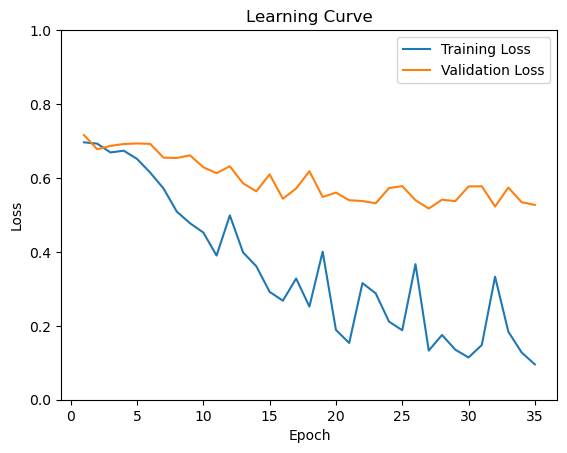

Fold 2
Accuracy Train: 0.8963265350278543. Accuracy valid: 0.6457142925688198
Recall Train: 0.848231315612793. Recall valid: 0.8142856955528259
Precision Train: 0.8885714411735535. Precision valid: 0.5535714030265808
Best Valid Accuracy Epoc: 6. Value = 0.7750000059604645 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.5250000059604645


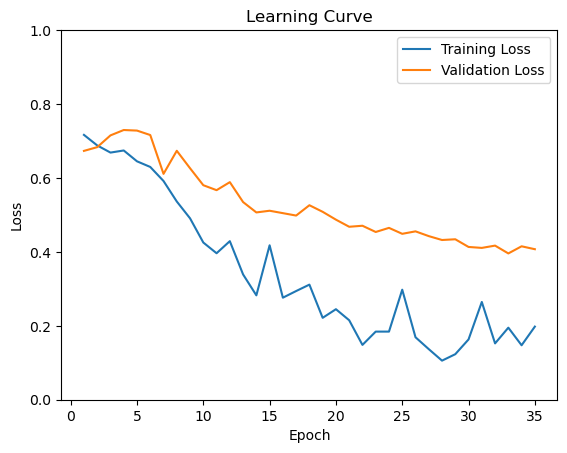

Fold 3
Accuracy Train: 0.873469392255861. Accuracy valid: 0.8214285731315613
Recall Train: 0.8182992935180664. Recall valid: 0.8142858147621155
Precision Train: 0.8557823300361633. Precision valid: 0.9119048118591309
Best Valid Accuracy Epoc: 11. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 1. Value = 0.8333333730697632 Acc val = 0.6500000059604645


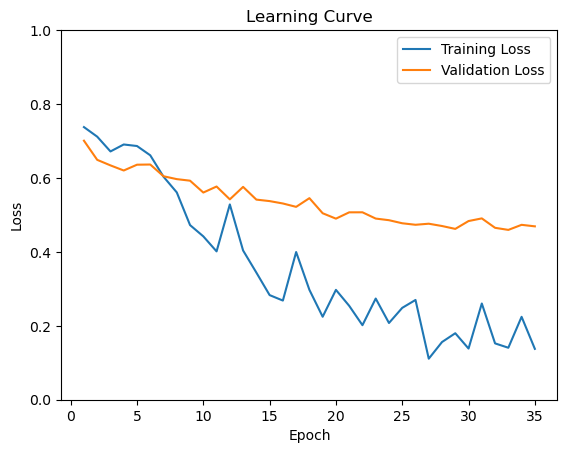

Fold 4
Accuracy Train: 0.8800000048413569. Accuracy valid: 0.86857143001897
Recall Train: 0.7785714864730835. Recall valid: 0.6714285612106323
Precision Train: 0.8523809909820557. Precision valid: 0.6288095252854483
Best Valid Accuracy Epoc: 14. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


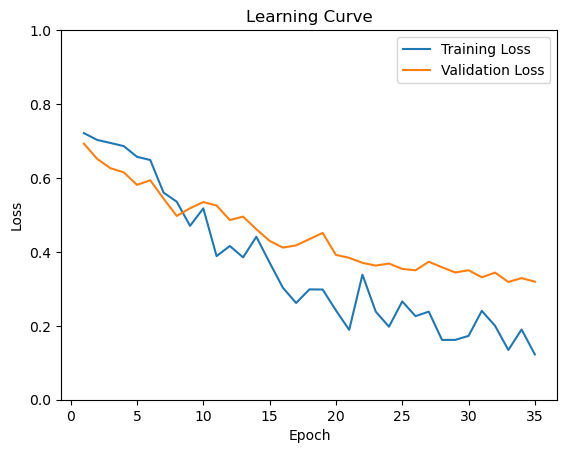

Fold 5
Accuracy Train: 0.7857142902378526. Accuracy valid: 0.6809523944343839
Recall Train: 0.677142858505249. Recall valid: 0.4214285612106323
Precision Train: 0.7217857241630554. Precision valid: 0.5095238089561462
Best Valid Accuracy Epoc: 26. Value = 0.9000000059604645 Recall val = 0.75
Best Valid Recall Epoc: 26. Value = 0.75 Acc val = 0.9000000059604645


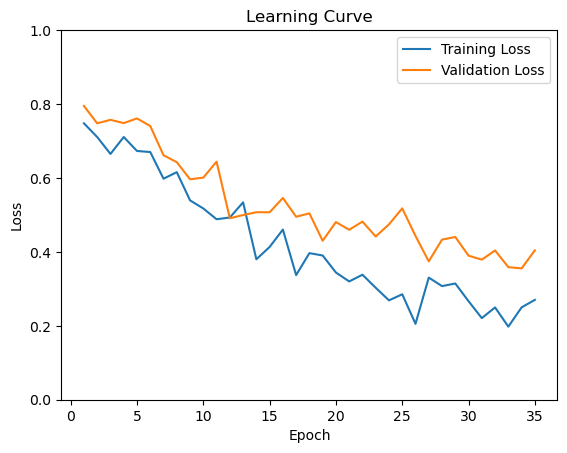

5
Fold 0: Training Loss: 0.35301606101649147, Validation Loss: 0.5946295665843147
Fold 1: Training Loss: 0.34182204646723613, Validation Loss: 0.5285873932497842
Fold 2: Training Loss: 0.36119964782680786, Validation Loss: 0.5367778143712453
Fold 3: Training Loss: 0.362229160964489, Validation Loss: 0.4462314224668911
Fold 4: Training Loss: 0.4232307834284646, Validation Loss: 0.5289707507405962
TRAIN LOSS MEDIA: 0.36829953994069775 VALID LOSS MEDIA: 0.5270393894825662
TRAIN ACC MEDIA: 0.8631020452827215 VALID ACC MEDIA: 0.7413333399380957
TRAIN RECALL MEDIA: 0.7902721166610718 VALID RECALL MEDIA: 0.6100000143051147
TRAIN PRECISION MEDIA: 0.8400305509567261 VALID PRECISION MEDIA: 0.6450476241111756


In [7]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.SGD , 5, 0.001, False, None)

Fold 1
Accuracy Train: 0.7787755190717931. Accuracy valid: 0.6228571525641851
Recall Train: 0.7134013772010803. Recall valid: 0.5928571224212646
Precision Train: 0.8193877339363098. Precision valid: 0.5833333509308951
Best Valid Accuracy Epoc: 1. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 10. Value = 0.75 Acc val = 0.5750000029802322


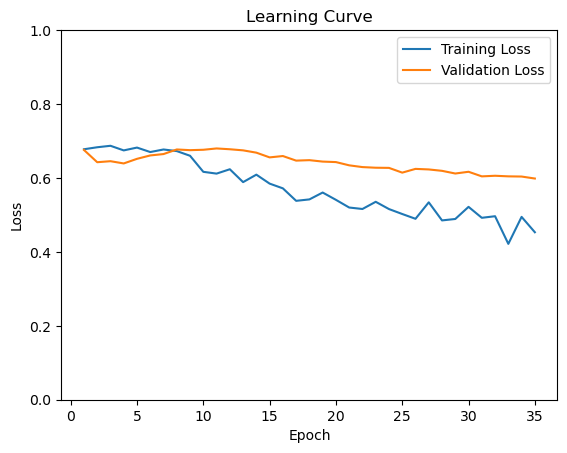

Fold 2
Accuracy Train: 0.7355102140684516. Accuracy valid: 0.6985714356814112
Recall Train: 0.47122448682785034. Recall valid: 0.39523813128471375
Precision Train: 0.644897963319506. Precision valid: 0.5571428571428572
Best Valid Accuracy Epoc: 30. Value = 0.9000000059604645 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 30. Value = 0.8333333730697632 Acc val = 0.9000000059604645


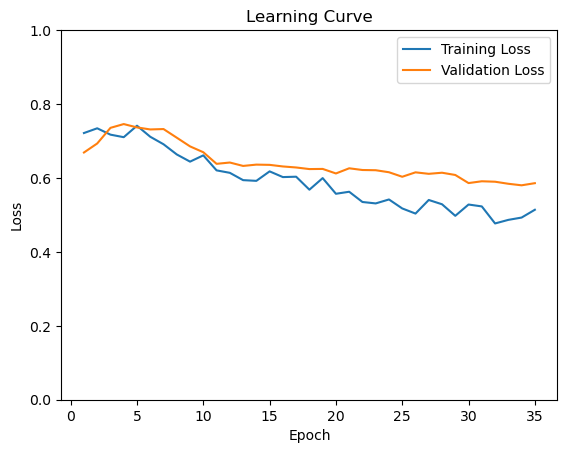

Fold 3
Accuracy Train: 0.765714293718338. Accuracy valid: 0.5792857216937202
Recall Train: 0.7293877601623535. Recall valid: 0.32857146859169006
Precision Train: 0.7785714864730835. Precision valid: 0.5885714292526245
Best Valid Accuracy Epoc: 30. Value = 0.75 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 0. Value = 0.8333333730697632 Acc val = 0.4750000014901161


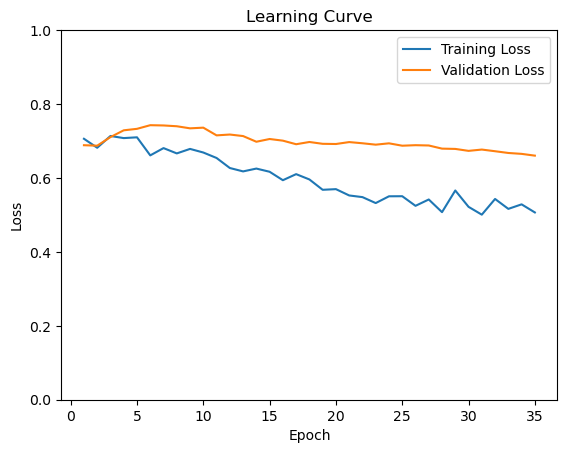

Fold 4
Accuracy Train: 0.7012245010356515. Accuracy valid: 0.5785714324031558
Recall Train: 0.4431973099708557. Recall valid: 0.02380952425301075
Precision Train: 0.6210884370974132. Precision valid: 0.05714285714285714
Best Valid Accuracy Epoc: 34. Value = 0.7750000059604645 Recall val = 0.3333333432674408
Best Valid Recall Epoc: 34. Value = 0.3333333432674408 Acc val = 0.7750000059604645


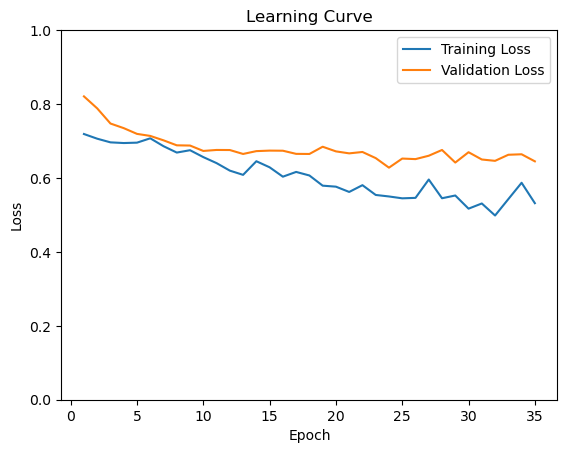

Fold 5
Accuracy Train: 0.694285723567009. Accuracy valid: 0.7047619206564767
Recall Train: 0.6911309957504272. Recall valid: 0.5285714268684387
Precision Train: 0.6498214602470398. Precision valid: 0.8142856955528259
Best Valid Accuracy Epoc: 9. Value = 0.9000000059604645 Recall val = 0.75
Best Valid Recall Epoc: 4. Value = 1.0 Acc val = 0.800000011920929


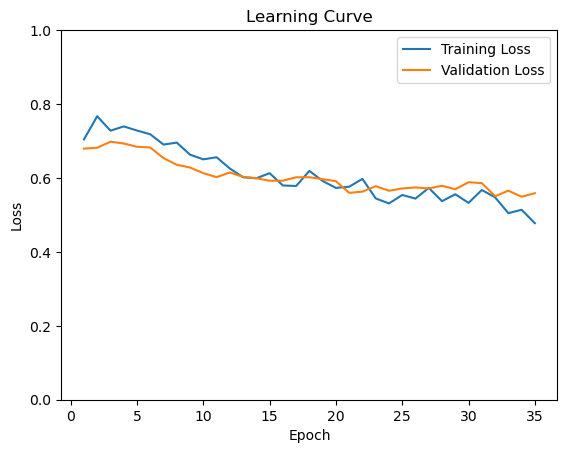

5
Fold 0: Training Loss: 0.5697116000311715, Validation Loss: 0.6415043064526149
Fold 1: Training Loss: 0.5927422395774297, Validation Loss: 0.6418722212314606
Fold 2: Training Loss: 0.5984308515276228, Validation Loss: 0.6993992643696921
Fold 3: Training Loss: 0.607670385496957, Validation Loss: 0.6810121502195086
Fold 4: Training Loss: 0.608011484997613, Validation Loss: 0.6050487211772374
TRAIN LOSS MEDIA: 0.5953133123261587 VALID LOSS MEDIA: 0.6537673326901028
TRAIN ACC MEDIA: 0.7351020502922486 VALID ACC MEDIA: 0.6368095325997898
TRAIN RECALL MEDIA: 0.6096683740615845 VALID RECALL MEDIA: 0.3738095164299011
TRAIN PRECISION MEDIA: 0.7027534162146705 VALID PRECISION MEDIA: 0.5200952380044119


In [15]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.SGD , 5, 0.0001, False, None)

Fold 1
Accuracy Train: 0.9053061251737633. Accuracy valid: 0.7342857199055808
Recall Train: 0.907619059085846. Recall valid: 0.6071428656578064
Precision Train: 0.8904081583023071. Precision valid: 0.8609523773193359
Best Valid Accuracy Epoc: 4. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.45000000298023224


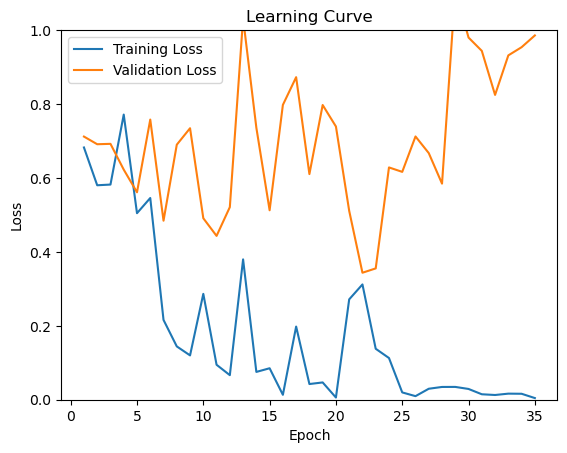

Fold 2
Accuracy Train: 0.8759183708502322. Accuracy valid: 0.86785714668887
Recall Train: 0.8456462025642395. Recall valid: 0.9666666388511658
Precision Train: 0.844761848449707. Precision valid: 0.8400000333786011
Best Valid Accuracy Epoc: 7. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.550000011920929


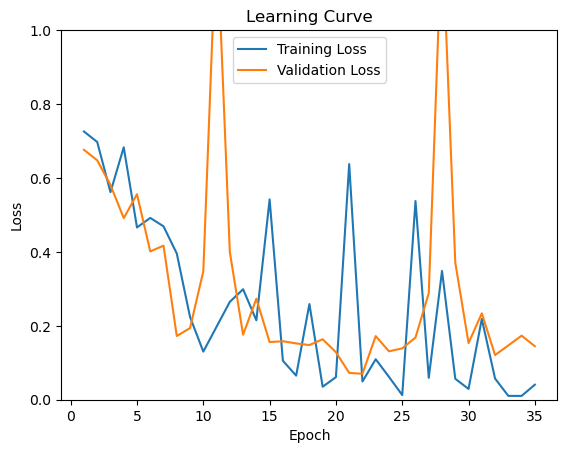

Fold 3
Accuracy Train: 0.8791836772646223. Accuracy valid: 0.7985714307853153
Recall Train: 0.8501361012458801. Recall valid: 0.795238196849823
Precision Train: 0.8512244820594788. Precision valid: 0.8533333335603986
Best Valid Accuracy Epoc: 6. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4750000014901161


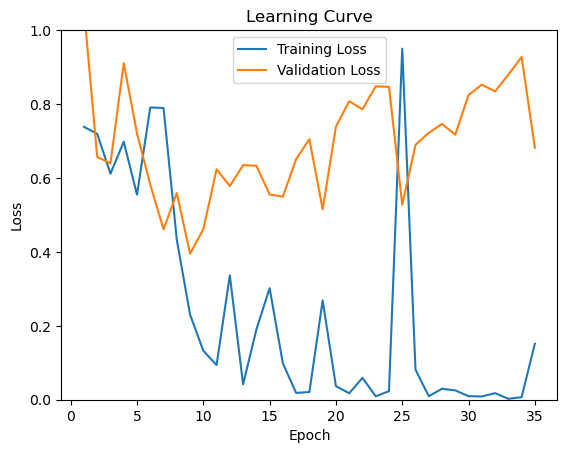

Fold 4
Accuracy Train: 0.8963265342371805. Accuracy valid: 0.8185714325734548
Recall Train: 0.8729251623153687. Recall valid: 0.7333332896232605
Precision Train: 0.8744217753410339. Precision valid: 0.6604761924062457
Best Valid Accuracy Epoc: 9. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 0.6500000059604645


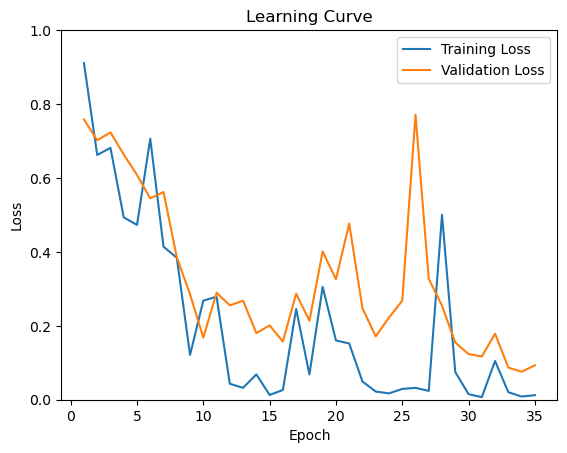

Fold 5
Accuracy Train: 0.8085714325840984. Accuracy valid: 0.7000000127724239
Recall Train: 0.7296428680419922. Recall valid: 0.6928571462631226
Precision Train: 0.7291072010993958. Precision valid: 0.6728571517126901
Best Valid Accuracy Epoc: 27. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 4. Value = 1.0 Acc val = 0.533333346247673


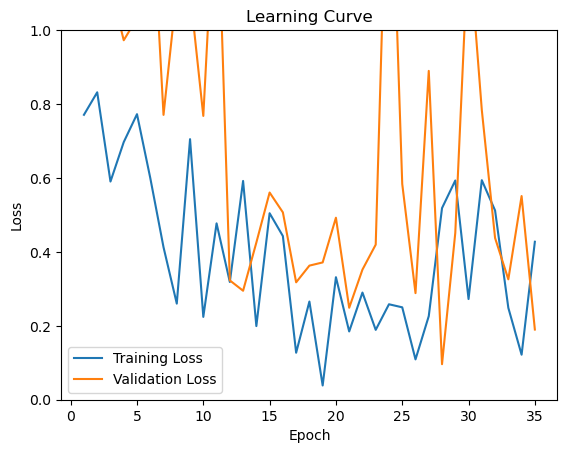

5
Fold 0: Training Loss: 0.18563193677525436, Validation Loss: 0.7042258869324411
Fold 1: Training Loss: 0.2607728755633746, Validation Loss: 0.3195091395771929
Fold 2: Training Loss: 0.24302077442407607, Validation Loss: 0.694771029108337
Fold 3: Training Loss: 0.21214746836838977, Validation Loss: 0.3299460121563503
Fold 4: Training Loss: 0.39875808911664146, Validation Loss: 0.7027350556171899
TRAIN LOSS MEDIA: 0.2600662288495473 VALID LOSS MEDIA: 0.5502374246783022
TRAIN ACC MEDIA: 0.8730612280219793 VALID ACC MEDIA: 0.7838571485451289
TRAIN RECALL MEDIA: 0.8411938548088074 VALID RECALL MEDIA: 0.7590476274490356
TRAIN PRECISION MEDIA: 0.8379847407341003 VALID PRECISION MEDIA: 0.7775238176754542


In [16]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.SGD , 5, 0.01, False, None)

### PRUEBAS BS

Fold 1
Accuracy Train: 0.8150793690057029. Accuracy valid: 0.6571428738889241
Recall Train: 0.6789681911468506. Recall valid: 0.2428571730852127
Precision Train: 0.721031665802002. Precision valid: 0.34603175606046405
Best Valid Accuracy Epoc: 7. Value = 0.7777777910232544 Recall val = 0.3333333432674408
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444576899211


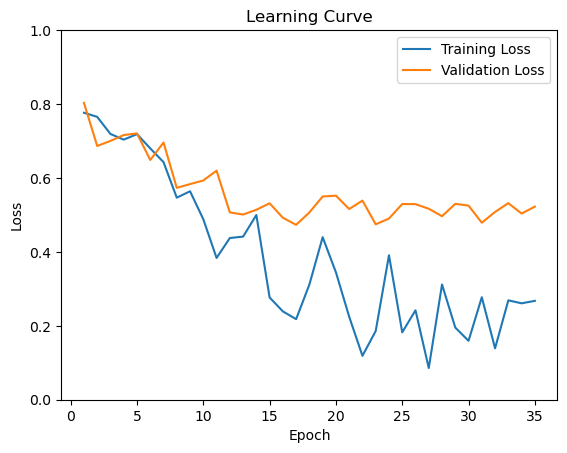

Fold 2
Accuracy Train: 0.7908730206035433. Accuracy valid: 0.6158730313891456
Recall Train: 0.6206350326538086. Recall valid: 0.7142857313156128
Precision Train: 0.6761904954910278. Precision valid: 0.6174603700637817
Best Valid Accuracy Epoc: 13. Value = 0.7777777910232544 Recall val = 0.8333333134651184
Best Valid Recall Epoc: 11. Value = 1.0 Acc val = 0.6666666766007742


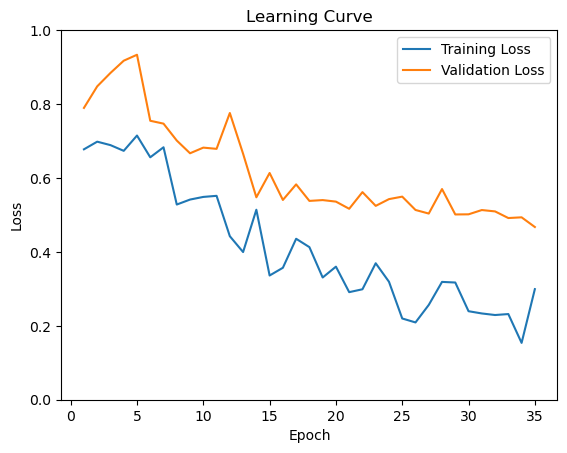

Fold 3
Accuracy Train: 0.8289682577053706. Accuracy valid: 0.8031746115003313
Recall Train: 0.6718254089355469. Recall valid: 0.538095235824585
Precision Train: 0.7015873193740845. Precision valid: 0.5476190635136196
Best Valid Accuracy Epoc: 9. Value = 0.8888888955116272 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 9. Value = 0.6666666865348816 Acc val = 0.8888888955116272


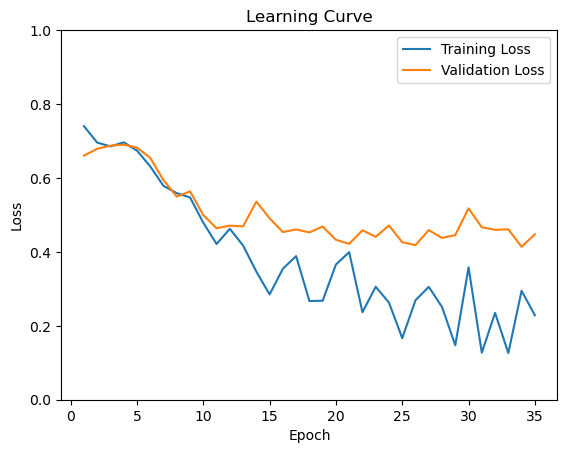

Fold 4
Accuracy Train: 0.8305555603333882. Accuracy valid: 0.8158730228741964
Recall Train: 0.6956349015235901. Recall valid: 0.8380951881408691
Precision Train: 0.7583333849906921. Precision valid: 0.723809529202325
Best Valid Accuracy Epoc: 10. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 8. Value = 1.0 Acc val = 0.6666666865348816


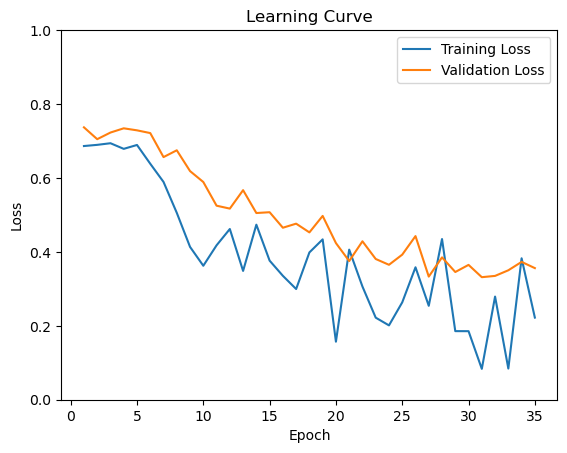

Fold 5
Accuracy Train: 0.8309523860613506. Accuracy valid: 0.8333333395776295
Recall Train: 0.670634925365448. Recall valid: 0.6666666269302368
Precision Train: 0.721428632736206. Precision valid: 0.6873015991279057
Best Valid Accuracy Epoc: 13. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 9. Value = 1.0 Acc val = 0.8888888955116272


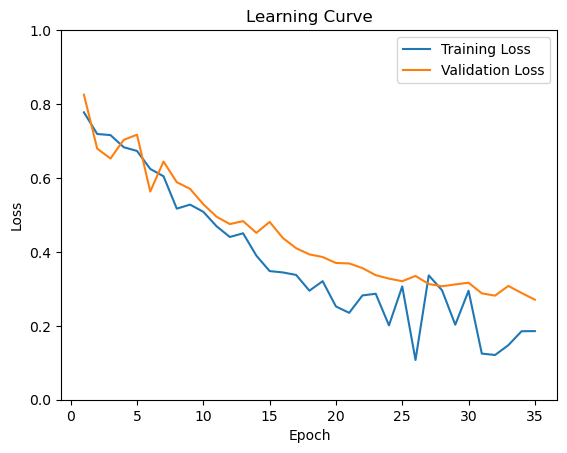

5
Fold 0: Training Loss: 0.38591827409608026, Validation Loss: 0.5617073473476228
Fold 1: Training Loss: 0.4153193827186312, Validation Loss: 0.6200679063796998
Fold 2: Training Loss: 0.38789163742746624, Validation Loss: 0.5058541392996198
Fold 3: Training Loss: 0.38624703947986877, Validation Loss: 0.49671018180393045
Fold 4: Training Loss: 0.3803773894906044, Validation Loss: 0.4453251615166665
TRAIN LOSS MEDIA: 0.39115074464253013 VALID LOSS MEDIA: 0.5259329472695079
TRAIN ACC MEDIA: 0.819285718741871 VALID ACC MEDIA: 0.7450793758460454
TRAIN RECALL MEDIA: 0.6675397157669067 VALID RECALL MEDIA: 0.6000000238418579
TRAIN PRECISION MEDIA: 0.7157143354415894 VALID PRECISION MEDIA: 0.5844444635936192


In [17]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.SGD , 3, 0.001, False, None)

Fold 1
Accuracy Train: 0.879761905499867. Accuracy valid: 0.38035714285714284
Recall Train: 0.849306046962738. Recall valid: 0.3809523582458496
Precision Train: 0.8667346239089966. Precision valid: 0.3629421889781952
Best Valid Accuracy Epoc: 2. Value = 0.75 Recall val = 1.0
Best Valid Recall Epoc: 2. Value = 1.0 Acc val = 0.75


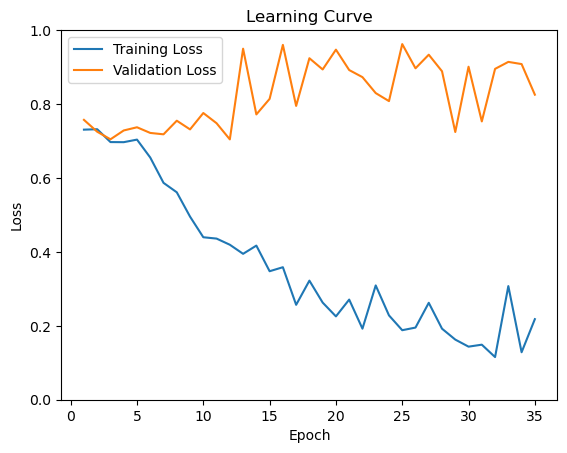

Fold 2
Accuracy Train: 0.8652380960328239. Accuracy valid: 0.8196428571428571
Recall Train: 0.8324897885322571. Recall valid: 0.8952380418777466
Precision Train: 0.8841972947120667. Precision valid: 0.7751190066337585
Best Valid Accuracy Epoc: 18. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.6875


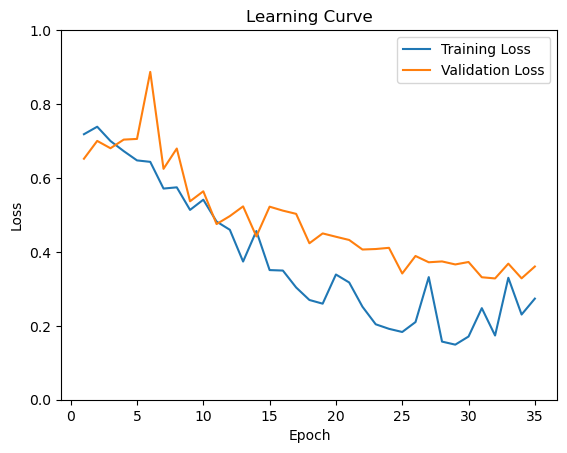

Fold 3
Accuracy Train: 0.8990476197855812. Accuracy valid: 0.875
Recall Train: 0.8489115834236145. Recall valid: 0.7476191520690918
Precision Train: 0.8916190266609192. Precision valid: 0.8904761927468436
Best Valid Accuracy Epoc: 6. Value = 0.9375 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 4. Value = 0.8333333730697632 Acc val = 0.875


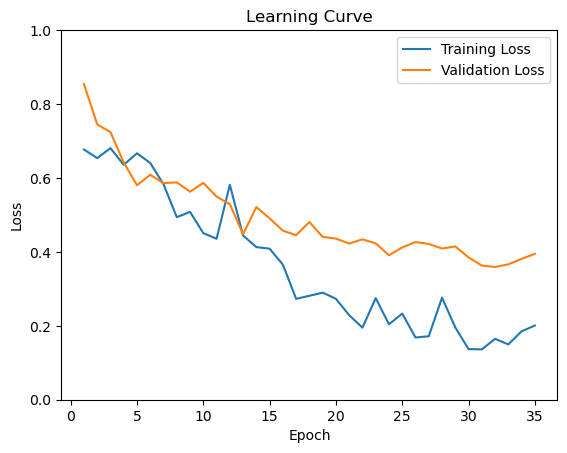

Fold 4
Accuracy Train: 0.8380952394008636. Accuracy valid: 0.8107142857142857
Recall Train: 0.7846258282661438. Recall valid: 0.2857142984867096
Precision Train: 0.8477142453193665. Precision valid: 0.3376190504857472
Best Valid Accuracy Epoc: 11. Value = 0.9375 Recall val = 0.375
Best Valid Recall Epoc: 10. Value = 0.375 Acc val = 0.75


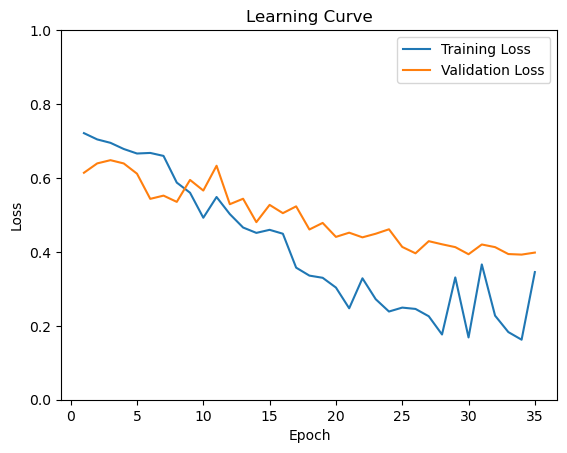

Fold 5
Accuracy Train: 0.8685714285714285. Accuracy valid: 0.6464285714285715
Recall Train: 0.7786257863044739. Recall valid: 0.5
Precision Train: 0.8161904811859131. Precision valid: 0.6595238157681056
Best Valid Accuracy Epoc: 12. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 27. Value = 1.0 Acc val = 0.875


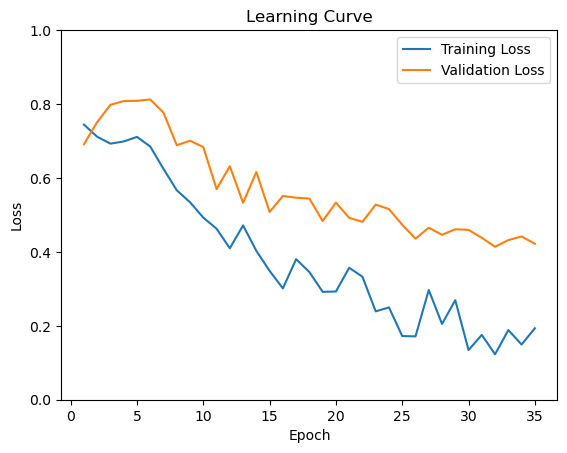

5
Fold 0: Training Loss: 0.3657607514943395, Validation Loss: 0.8247589660542352
Fold 1: Training Loss: 0.3825345699276243, Validation Loss: 0.4888897763831275
Fold 2: Training Loss: 0.3621806493827275, Validation Loss: 0.493694640483175
Fold 3: Training Loss: 0.41151567697525027, Validation Loss: 0.4957090782267707
Fold 4: Training Loss: 0.3835926909531866, Validation Loss: 0.5697843134403229
TRAIN LOSS MEDIA: 0.3811168677466256 VALID LOSS MEDIA: 0.5745673549175263
TRAIN ACC MEDIA: 0.8701428578581127 VALID ACC MEDIA: 0.7064285714285715
TRAIN RECALL MEDIA: 0.8187917470932007 VALID RECALL MEDIA: 0.561904788017273
TRAIN PRECISION MEDIA: 0.8612911105155945 VALID PRECISION MEDIA: 0.6051360509225301


In [18]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.SGD , 8, 0.001, False, None)

Fold 1
Accuracy Train: 0.8414682555766333. Accuracy valid: 0.7714285850524902
Recall Train: 0.7362774014472961. Recall valid: 0.6357142925262451
Precision Train: 0.8072789311408997. Precision valid: 0.8071428537368774
Best Valid Accuracy Epoc: 9. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 9. Value = 0.75 Acc val = 0.8888888955116272


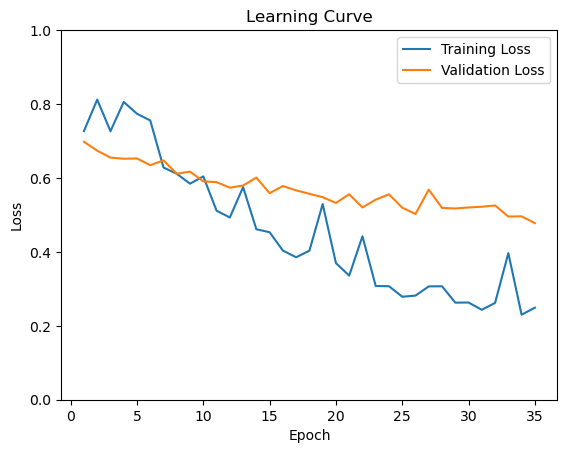

Fold 2
Accuracy Train: 0.82857143055825. Accuracy valid: 0.6507936647960118
Recall Train: 0.695036768913269. Recall valid: 0.4357142746448517
Precision Train: 0.758355975151062. Precision valid: 0.7252380984170096
Best Valid Accuracy Epoc: 14. Value = 0.7777777910232544 Recall val = 0.5
Best Valid Recall Epoc: 5. Value = 0.5 Acc val = 0.3333333432674408


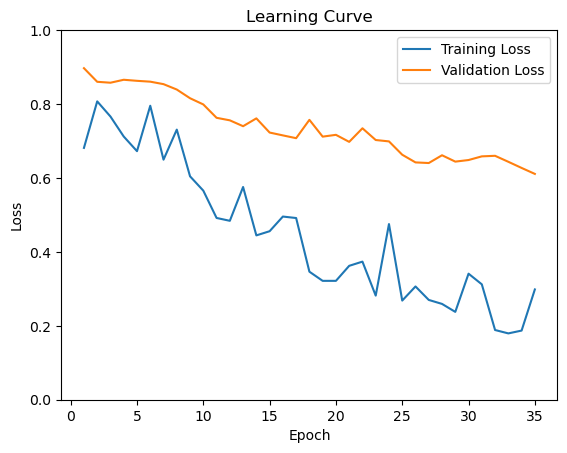

Fold 3
Accuracy Train: 0.8369047638915834. Accuracy valid: 0.6031746208667755
Recall Train: 0.7368937730789185. Recall valid: 0.41428571939468384
Precision Train: 0.805954098701477. Precision valid: 0.7269501158169338
Best Valid Accuracy Epoc: 30. Value = 0.7777777910232544 Recall val = 0.5
Best Valid Recall Epoc: 4. Value = 1.0 Acc val = 0.4444444477558136


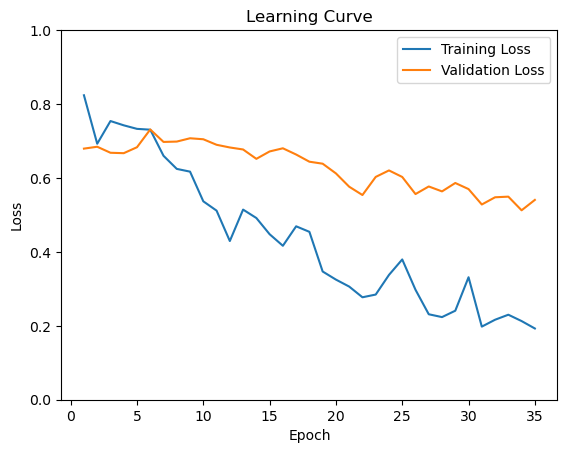

Fold 4
Accuracy Train: 0.8323412719227018. Accuracy valid: 0.7428571581840515
Recall Train: 0.7740616798400879. Recall valid: 0.699999988079071
Precision Train: 0.8239477276802063. Precision valid: 0.7482312968799046
Best Valid Accuracy Epoc: 4. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 8. Value = 1.0 Acc val = 0.6666666865348816


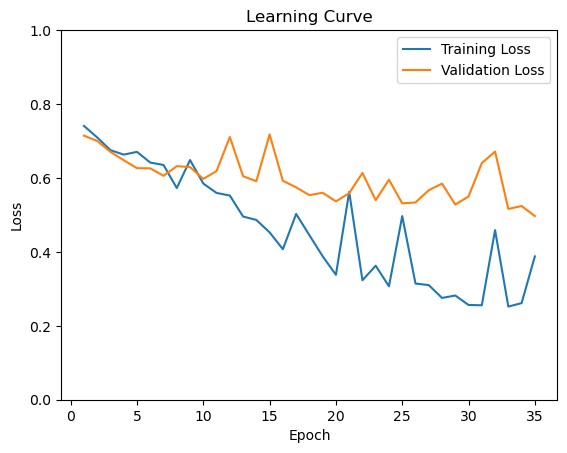

Fold 5
Accuracy Train: 0.8708333333333333. Accuracy valid: 0.6535714285714286
Recall Train: 0.8556235432624817. Recall valid: 0.3571428656578064
Precision Train: 0.8884296417236328. Precision valid: 0.7357142865657806
Best Valid Accuracy Epoc: 28. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 10. Value = 0.75 Acc val = 0.75


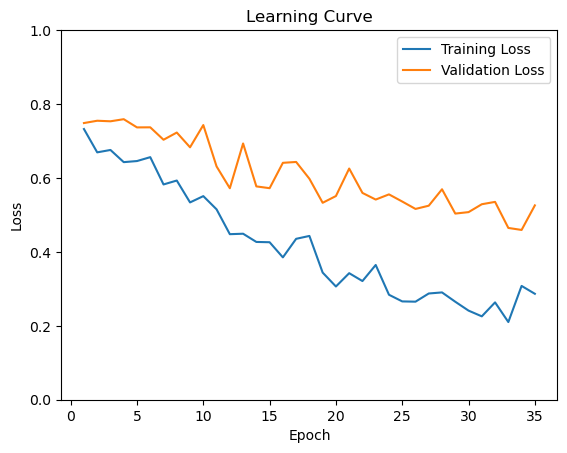

5
Fold 0: Training Loss: 0.4596417371715818, Validation Loss: 0.5701299718448094
Fold 1: Training Loss: 0.4501500908817564, Validation Loss: 0.7370384284428187
Fold 2: Training Loss: 0.4365872200046267, Validation Loss: 0.6291687709944589
Fold 3: Training Loss: 0.4650210976600647, Validation Loss: 0.5988948038646154
Fold 4: Training Loss: 0.4194981140749795, Validation Loss: 0.6088113691125597
TRAIN LOSS MEDIA: 0.4461796519586018 VALID LOSS MEDIA: 0.6288086688518525
TRAIN ACC MEDIA: 0.8420238110565004 VALID ACC MEDIA: 0.6843650914941515
TRAIN RECALL MEDIA: 0.7595786452293396 VALID RECALL MEDIA: 0.508571445941925
TRAIN PRECISION MEDIA: 0.8167932629585266 VALID PRECISION MEDIA: 0.7486553302833012


In [19]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.SGD , 16, 0.001, False, None)

### PRUEBAS EPOCS

Fold 1
Accuracy Train: 0.8840000040616309. Accuracy valid: 0.7825000041723251
Recall Train: 0.8290476202964783. Recall valid: 0.5600000023841858
Precision Train: 0.8861904740333557. Precision valid: 0.8216666674613953
Best Valid Accuracy Epoc: 34. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 13. Value = 1.0 Acc val = 0.875


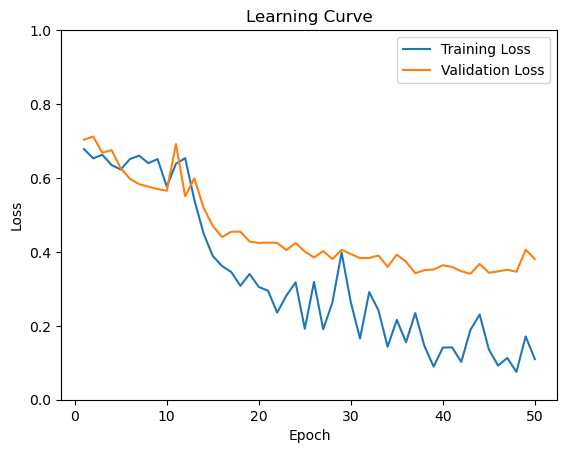

Fold 2
Accuracy Train: 0.8845714328118732. Accuracy valid: 0.7050000062584877
Recall Train: 0.8411905169487. Recall valid: 0.6899999976158142
Precision Train: 0.8947619795799255. Precision valid: 0.6816667318344116
Best Valid Accuracy Epoc: 23. Value = 0.875 Recall val = 1.0
Best Valid Recall Epoc: 23. Value = 1.0 Acc val = 0.875


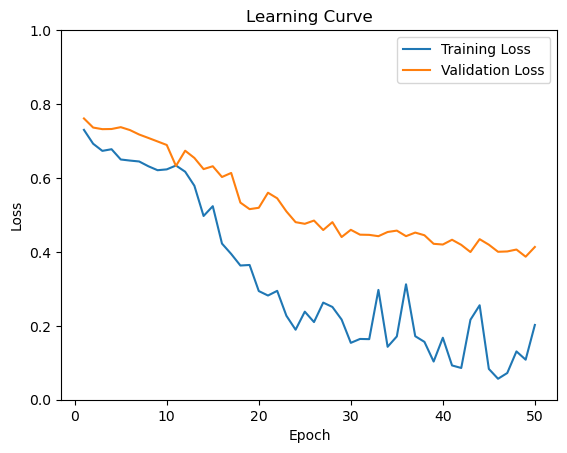

Fold 3
Accuracy Train: 0.8554285757030761. Accuracy valid: 0.6955000014603138
Recall Train: 0.7831429243087769. Recall valid: 0.5666667222976685
Precision Train: 0.8311904668807983. Precision valid: 0.7241666668653488
Best Valid Accuracy Epoc: 15. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 15. Value = 0.8333333730697632 Acc val = 0.875


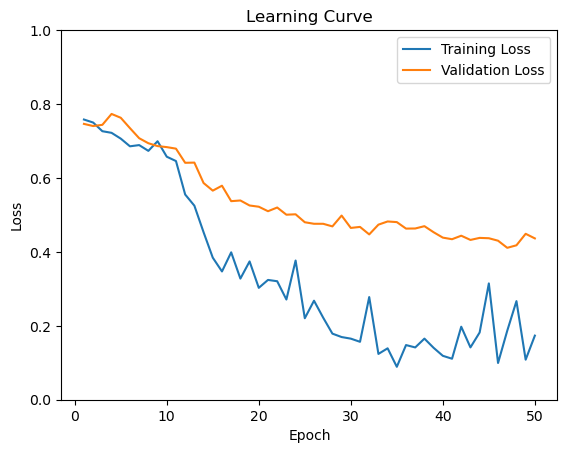

Fold 4
Accuracy Train: 0.8605714335611887. Accuracy valid: 0.7500000029802323
Recall Train: 0.7940000295639038. Recall valid: 0.8500000238418579
Precision Train: 0.8408094644546509. Precision valid: 0.6393333673477173
Best Valid Accuracy Epoc: 13. Value = 0.875 Recall val = 1.0
Best Valid Recall Epoc: 13. Value = 1.0 Acc val = 0.875


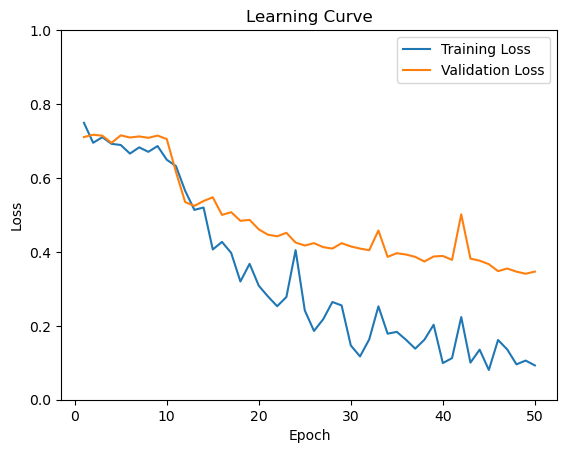

Fold 5
Accuracy Train: 0.8300000036507845. Accuracy valid: 0.7726666769385337
Recall Train: 0.687333345413208. Recall valid: 0.6399999856948853
Precision Train: 0.7454166668653488. Precision valid: 0.865
Best Valid Accuracy Epoc: 8. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 8. Value = 0.75 Acc val = 0.8333333432674408


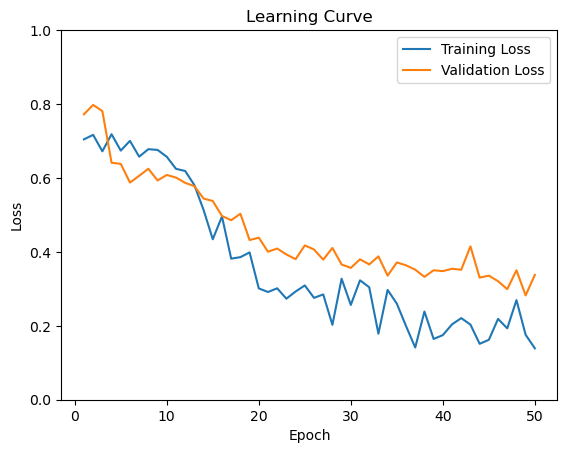

5
Fold 0: Training Loss: 0.33411616683006284, Validation Loss: 0.45277038276195525
Fold 1: Training Loss: 0.3352396729588509, Validation Loss: 0.5335925325751305
Fold 2: Training Loss: 0.3435954111814499, Validation Loss: 0.5390934771299363
Fold 3: Training Loss: 0.3356018620729446, Validation Loss: 0.485886565297842
Fold 4: Training Loss: 0.37247557163238526, Validation Loss: 0.4547508243471384
TRAIN LOSS MEDIA: 0.3442057369351387 VALID LOSS MEDIA: 0.49321875642240054
TRAIN ACC MEDIA: 0.8629142899577108 VALID ACC MEDIA: 0.7411333383619786
TRAIN RECALL MEDIA: 0.7869428992271423 VALID RECALL MEDIA: 0.6613333821296692
TRAIN PRECISION MEDIA: 0.839673810362816 VALID PRECISION MEDIA: 0.7463666867017746


In [7]:
prueba_k_fold_resnet_pre(df_mean, 5, 10,40, optim.SGD , 5, 0.001, False, None)

Fold 1
Accuracy Train: 0.9061224520206451. Accuracy valid: 0.6964285786662783
Recall Train: 0.8993877172470093. Recall valid: 0.4642857015132904
Precision Train: 0.8934693932533264. Precision valid: 0.7685714364051819
Best Valid Accuracy Epoc: 9. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.45000000298023224


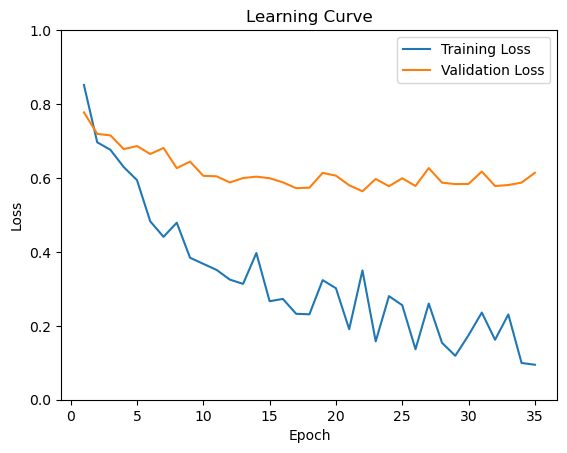

Fold 2
Accuracy Train: 0.9240816354143374. Accuracy valid: 0.8385714345744678
Recall Train: 0.8762584924697876. Recall valid: 0.6523810029029846
Precision Train: 0.9224489331245422. Precision valid: 0.8142857142857143
Best Valid Accuracy Epoc: 9. Value = 0.9000000059604645 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 9. Value = 0.8333333730697632 Acc val = 0.9000000059604645


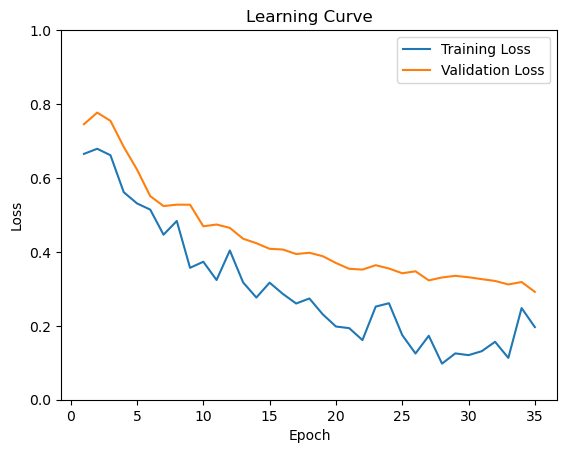

Fold 3
Accuracy Train: 0.9028571467618552. Accuracy valid: 0.8057142870766776
Recall Train: 0.8539456129074097. Recall valid: 0.6857143640518188
Precision Train: 0.9069388508796692. Precision valid: 0.8571428571428571
Best Valid Accuracy Epoc: 8. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 8. Value = 0.8333333730697632 Acc val = 0.875


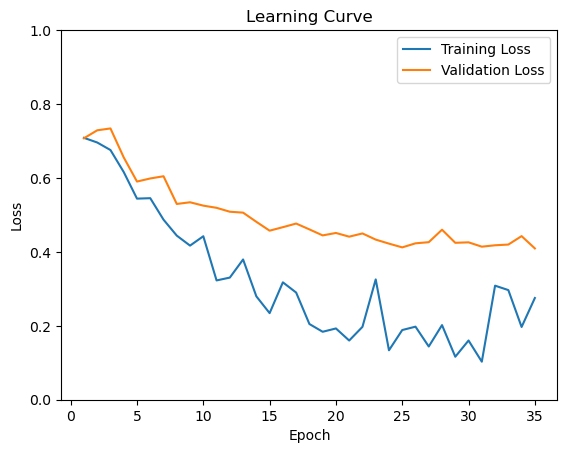

Fold 4
Accuracy Train: 0.9044897993000187. Accuracy valid: 0.8050000033208302
Recall Train: 0.8948299288749695. Recall valid: 0.699999988079071
Precision Train: 0.917755126953125. Precision valid: 0.5933333039283752
Best Valid Accuracy Epoc: 21. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


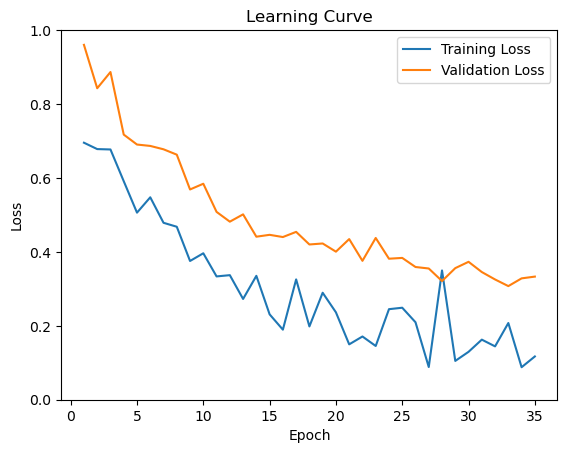

Fold 5
Accuracy Train: 0.8464285744088037. Accuracy valid: 0.7942857244185039
Recall Train: 0.7334523797035217. Recall valid: 0.6785714030265808
Precision Train: 0.7732142806053162. Precision valid: 0.8547619070325579
Best Valid Accuracy Epoc: 7. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 7. Value = 1.0 Acc val = 1.0


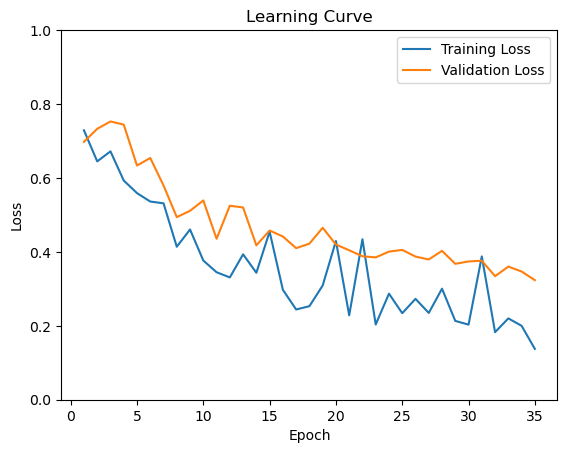

5
Fold 0: Training Loss: 0.3290873557329178, Validation Loss: 0.6172632566520146
Fold 1: Training Loss: 0.305468969472817, Validation Loss: 0.43860590415341516
Fold 2: Training Loss: 0.32334472473178594, Validation Loss: 0.49725067423922675
Fold 3: Training Loss: 0.30642137272017345, Validation Loss: 0.49175588829176764
Fold 4: Training Loss: 0.361623848761831, Validation Loss: 0.4711653679609299
TRAIN LOSS MEDIA: 0.32518925428390505 VALID LOSS MEDIA: 0.5032082182594708
TRAIN ACC MEDIA: 0.896795921581132 VALID ACC MEDIA: 0.7880000056113515
TRAIN RECALL MEDIA: 0.8515748977661133 VALID RECALL MEDIA: 0.6361905336380005
TRAIN PRECISION MEDIA: 0.8827652931213379 VALID PRECISION MEDIA: 0.7776190437589372


In [8]:
prueba_k_fold_resnet_pre(df_mean, 5, 2,33, optim.SGD , 5, 0.001, False, None)

Fold 1
Accuracy Train: 0.9165714320114681. Accuracy valid: 0.7170000064373017
Recall Train: 0.838904857635498. Recall valid: 0.44999998807907104
Precision Train: 0.890952467918396. Precision valid: 0.8483333334326744
Best Valid Accuracy Epoc: 9. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 0. Value = 0.5 Acc val = 0.75


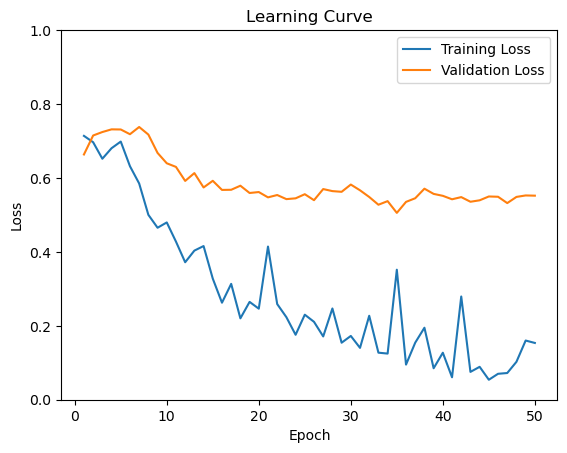

Fold 2
Accuracy Train: 0.8982857170701027. Accuracy valid: 0.7385000091791153
Recall Train: 0.8429047465324402. Recall valid: 0.6899999976158142
Precision Train: 0.8799999952316284. Precision valid: 0.701666693687439
Best Valid Accuracy Epoc: 16. Value = 0.9000000059604645 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 10. Value = 0.8333333730697632 Acc val = 0.800000011920929


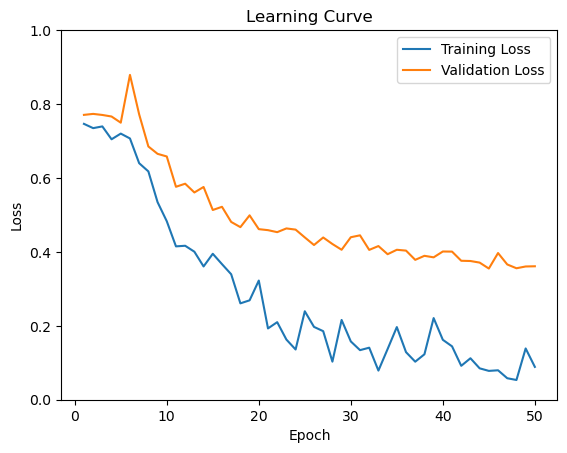

Fold 3
Accuracy Train: 0.9040000031249863. Accuracy valid: 0.8105000008642673
Recall Train: 0.855571448802948. Recall valid: 0.7466667294502258
Precision Train: 0.8983333706855774. Precision valid: 0.872333333492279
Best Valid Accuracy Epoc: 9. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4750000014901161


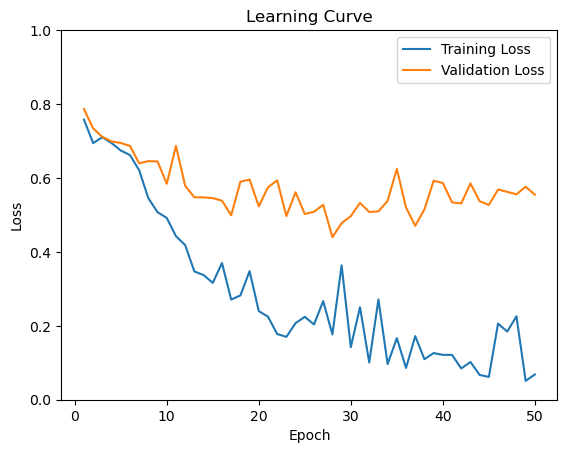

Fold 4
Accuracy Train: 0.9045714313643319. Accuracy valid: 0.8980000019073486
Recall Train: 0.8718571662902832. Recall valid: 0.8666666150093079
Precision Train: 0.9008094668388367. Precision valid: 0.8360000002384186
Best Valid Accuracy Epoc: 15. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 9. Value = 1.0 Acc val = 0.9000000059604645


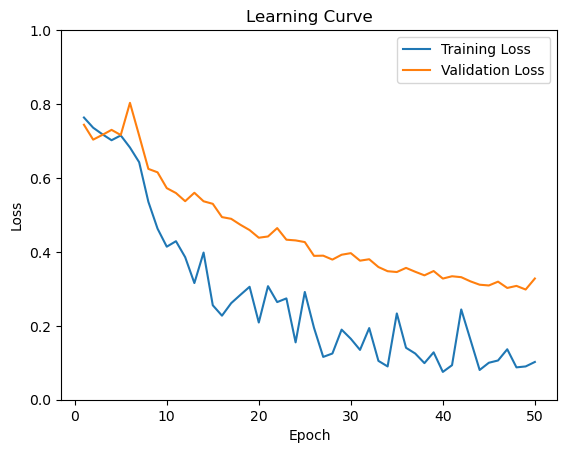

Fold 5
Accuracy Train: 0.8510000031813979. Accuracy valid: 0.7340000131726265
Recall Train: 0.7320833802223206. Recall valid: 0.5899999737739563
Precision Train: 0.7670416831970215. Precision valid: 0.779000004529953
Best Valid Accuracy Epoc: 18. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.533333346247673


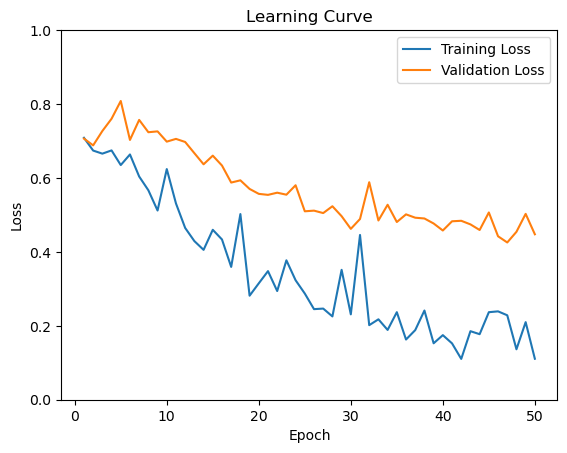

5
Fold 0: Training Loss: 0.2872049085795879, Validation Loss: 0.5868780919909478
Fold 1: Training Loss: 0.286558473482728, Validation Loss: 0.4974118956923485
Fold 2: Training Loss: 0.2911998319625855, Validation Loss: 0.5717414323985577
Fold 3: Training Loss: 0.2810690586268902, Validation Loss: 0.45695227205753325
Fold 4: Training Loss: 0.34874554723501205, Validation Loss: 0.5707068499922753
TRAIN LOSS MEDIA: 0.2989555639773607 VALID LOSS MEDIA: 0.5367381084263325
TRAIN ACC MEDIA: 0.8948857173504574 VALID ACC MEDIA: 0.7796000063121319
TRAIN RECALL MEDIA: 0.8282643556594849 VALID RECALL MEDIA: 0.668666660785675
TRAIN PRECISION MEDIA: 0.8674274682998657 VALID PRECISION MEDIA: 0.8074666730761528


In [9]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,45, optim.SGD , 5, 0.001, False, None)

## SGD DATA AUG

Fold 1
Accuracy Train: 0.8137142912830626. Accuracy valid: 0.6770000067353249
Recall Train: 0.7667619585990906. Recall valid: 0.4350000023841858
Precision Train: 0.8079999685287476. Precision valid: 0.7481666672229766
Best Valid Accuracy Epoc: 35. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.45000000298023224


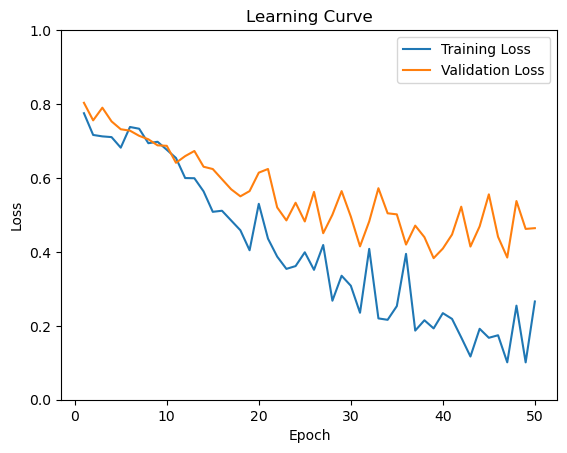

Fold 2
Accuracy Train: 0.8028571497116769. Accuracy valid: 0.7480000072717666
Recall Train: 0.7107619643211365. Recall valid: 0.5833333730697632
Precision Train: 0.7771428823471069. Precision valid: 0.7483333334326744
Best Valid Accuracy Epoc: 27. Value = 0.9000000059604645 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 27. Value = 0.8333333730697632 Acc val = 0.9000000059604645


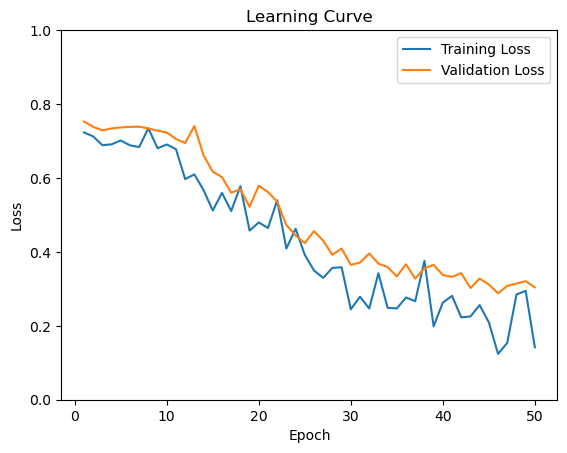

Fold 3
Accuracy Train: 0.8097142921601023. Accuracy valid: 0.7675000020861625
Recall Train: 0.7366191148757935. Recall valid: 0.7633333802223206
Precision Train: 0.8006190657615662. Precision valid: 0.8378334045410156
Best Valid Accuracy Epoc: 16. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4750000014901161


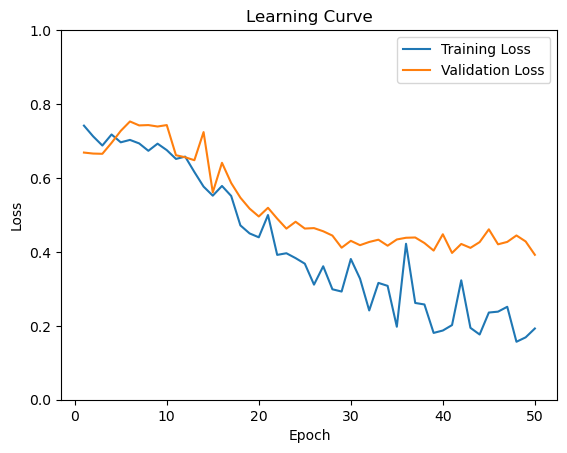

Fold 4
Accuracy Train: 0.8251428641591753. Accuracy valid: 0.647000008225441
Recall Train: 0.733571469783783. Recall valid: 0.8399999737739563
Precision Train: 0.8557142615318298. Precision valid: 0.5031666761636734
Best Valid Accuracy Epoc: 23. Value = 0.800000011920929 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 4. Value = 1.0 Acc val = 0.550000011920929


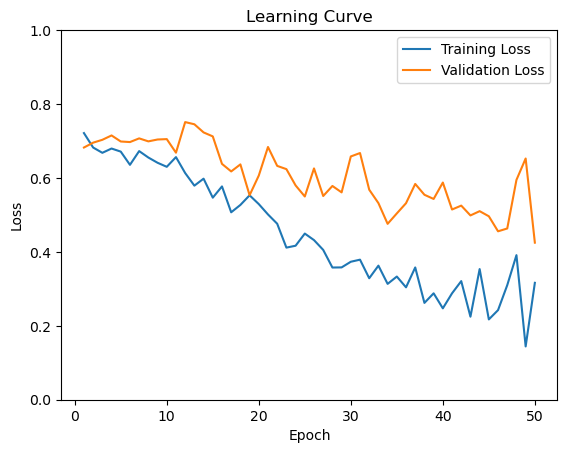

Fold 5
Accuracy Train: 0.7905000056698919. Accuracy valid: 0.7626666781306267
Recall Train: 0.6344166398048401. Recall valid: 0.6399999856948853
Precision Train: 0.6841666686534882. Precision valid: 0.8813332915306091
Best Valid Accuracy Epoc: 23. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.533333346247673


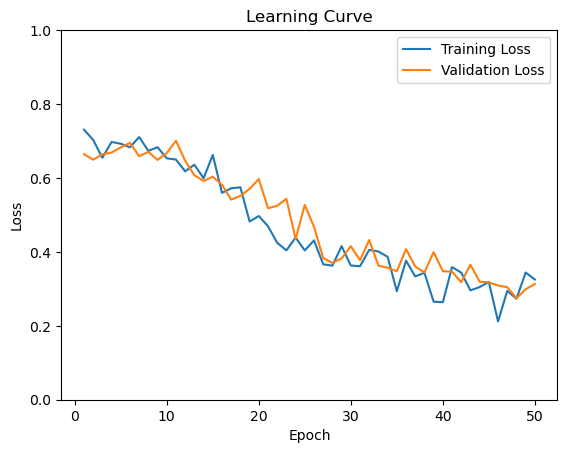

5
Fold 0: Training Loss: 0.4077362370491028, Validation Loss: 0.5598607295751572
Fold 1: Training Loss: 0.4277331992983818, Validation Loss: 0.49654398441314695
Fold 2: Training Loss: 0.42125506937503815, Validation Loss: 0.526250175833702
Fold 3: Training Loss: 0.45021419614553454, Validation Loss: 0.6077872878313064
Fold 4: Training Loss: 0.46627381145954133, Validation Loss: 0.4826349183917046
TRAIN LOSS MEDIA: 0.43464250266551974 VALID LOSS MEDIA: 0.5346154192090034
TRAIN ACC MEDIA: 0.8083857205967817 VALID ACC MEDIA: 0.7204333404898644
TRAIN RECALL MEDIA: 0.7164262533187866 VALID RECALL MEDIA: 0.6523333787918091
TRAIN PRECISION MEDIA: 0.7851285693645478 VALID PRECISION MEDIA: 0.7437666745781898


In [10]:
prueba_k_fold_resnet_pre(df_mean, 5, 10, 40, optim.SGD , 5, 0.001, True, None)

## SGD AUG GLOROT/HE INI

Fold 1
Accuracy Train: 0.846285719530923. Accuracy valid: 0.6965000061690807
Recall Train: 0.7944762706756592. Recall valid: 0.41999998688697815
Precision Train: 0.8285714983940125. Precision valid: 0.7975000143051147
Best Valid Accuracy Epoc: 12. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 0. Value = 0.5 Acc val = 0.3500000014901161


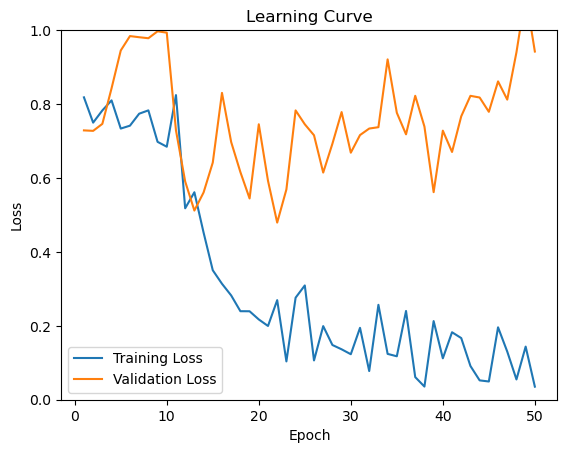

Fold 2
Accuracy Train: 0.8234285760777337. Accuracy valid: 0.7780000032484531
Recall Train: 0.7939523458480835. Recall valid: 0.8833333849906921
Precision Train: 0.8250476121902466. Precision valid: 0.7306666374206543
Best Valid Accuracy Epoc: 20. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 0.675000011920929


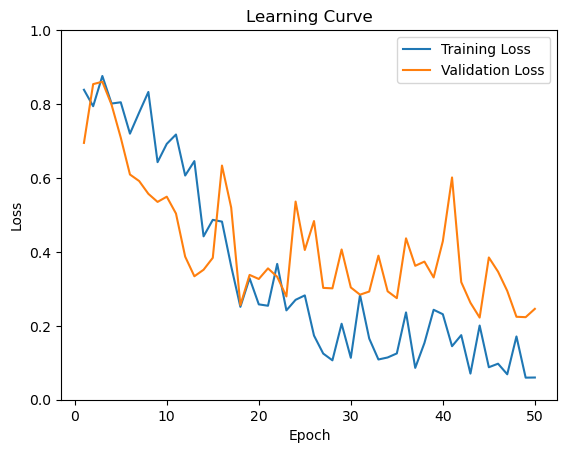

Fold 3
Accuracy Train: 0.8468571482811654. Accuracy valid: 0.7760000014305115
Recall Train: 0.7897619605064392. Recall valid: 0.7633334398269653
Precision Train: 0.8407142758369446. Precision valid: 0.8858333379030228
Best Valid Accuracy Epoc: 13. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.675000011920929


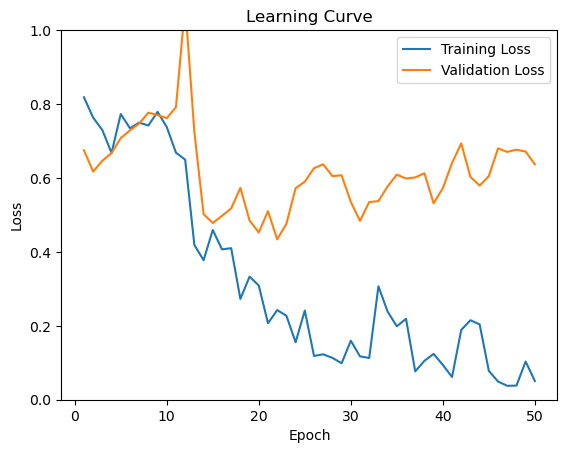

Fold 4
Accuracy Train: 0.7988571476936341. Accuracy valid: 0.5590000082552433
Recall Train: 0.7763333320617676. Recall valid: 0.5
Precision Train: 0.7945238351821899. Precision valid: 0.30116667330265046
Best Valid Accuracy Epoc: 14. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 11. Value = 1.0 Acc val = 0.42500001192092896


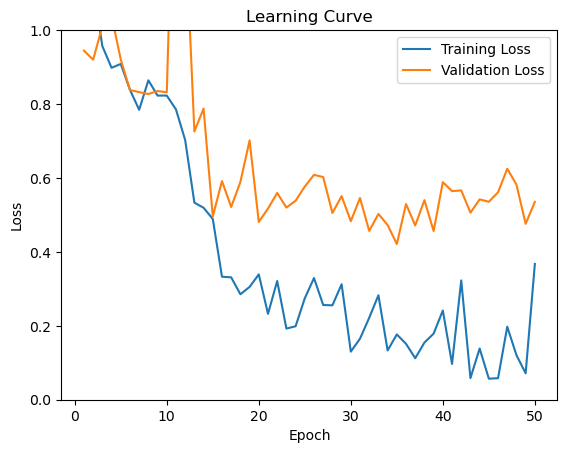

Fold 5
Accuracy Train: 0.7840000046044588. Accuracy valid: 0.682666677236557
Recall Train: 0.6954166889190674. Recall valid: 0.7649999856948853
Precision Train: 0.717791736125946. Precision valid: 0.7286666786670685
Best Valid Accuracy Epoc: 15. Value = 0.9000000059604645 Recall val = 0.75
Best Valid Recall Epoc: 4. Value = 1.0 Acc val = 0.7333333492279053


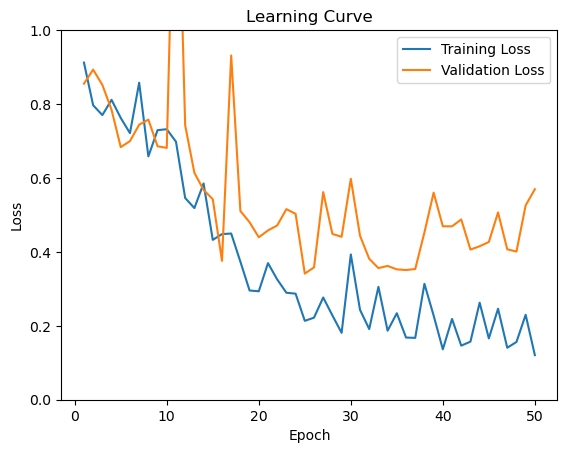

5
Fold 0: Training Loss: 0.319552778750658, Validation Loss: 0.7597713080048561
Fold 1: Training Loss: 0.34765920974314213, Validation Loss: 0.42181292846798896
Fold 2: Training Loss: 0.3220980339497328, Validation Loss: 0.6179403767362237
Fold 3: Training Loss: 0.4026355528831482, Validation Loss: 0.6561442190408706
Fold 4: Training Loss: 0.38389315754175185, Validation Loss: 0.5578346142917872
TRAIN LOSS MEDIA: 0.3551677465736866 VALID LOSS MEDIA: 0.6027006893083453
TRAIN ACC MEDIA: 0.8198857192375829 VALID ACC MEDIA: 0.6984333392679691
TRAIN RECALL MEDIA: 0.7699881196022034 VALID RECALL MEDIA: 0.6663333773612976
TRAIN PRECISION MEDIA: 0.8013297319412231 VALID PRECISION MEDIA: 0.6887666683197021


In [11]:
prueba_k_fold_resnet_pre(df_mean, 5, 10, 40, optim.SGD , 5, 0.001, True, 'G')


Fold 1
Accuracy Train: 0.8422857190029963. Accuracy valid: 0.7500000077486039
Recall Train: 0.8111428618431091. Recall valid: 0.5600000023841858
Precision Train: 0.8342381119728088. Precision valid: 0.731333315372467
Best Valid Accuracy Epoc: 15. Value = 0.9000000059604645 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.45000000298023224


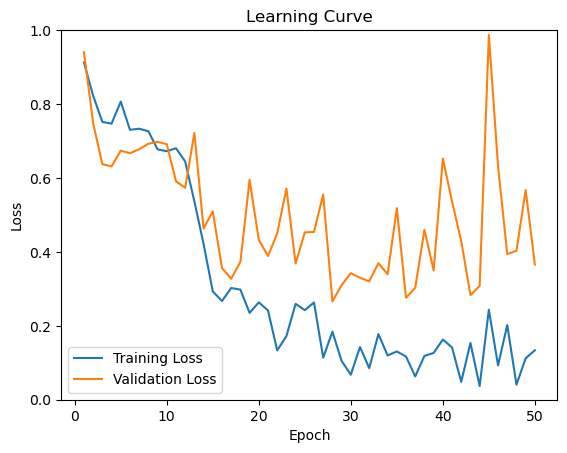

Fold 2
Accuracy Train: 0.8388571485025542. Accuracy valid: 0.7700000011920929
Recall Train: 0.8061904907226562. Recall valid: 0.9666666984558105
Precision Train: 0.8416666984558105. Precision valid: 0.6735000610351562
Best Valid Accuracy Epoc: 15. Value = 0.875 Recall val = 1.0
Best Valid Recall Epoc: 3. Value = 1.0 Acc val = 0.550000011920929


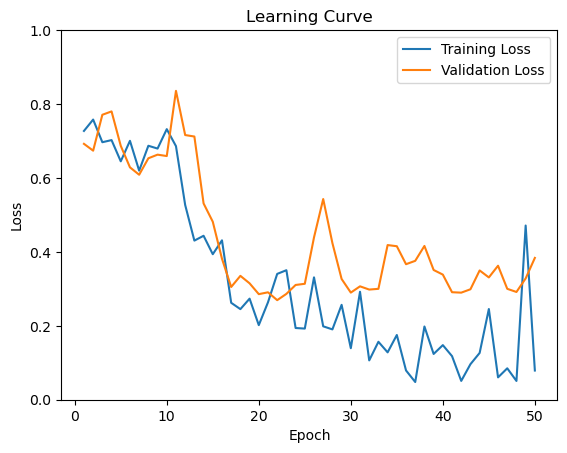

Fold 3
Accuracy Train: 0.857714291555541. Accuracy valid: 0.7970000022649765
Recall Train: 0.7783810496330261. Recall valid: 0.7133333086967468
Precision Train: 0.8376190066337585. Precision valid: 0.8683333337306977
Best Valid Accuracy Epoc: 12. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 11. Value = 0.8333333730697632 Acc val = 0.550000011920929


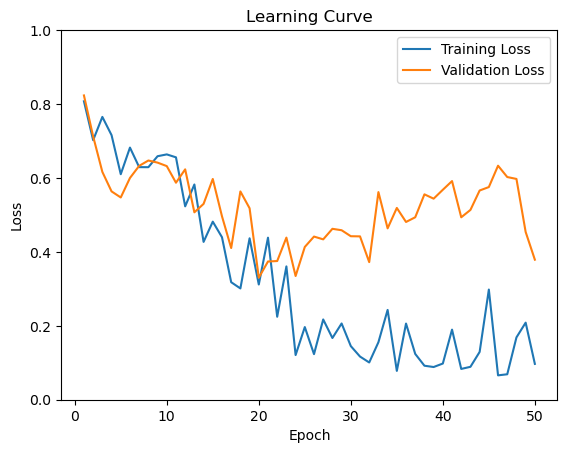

Fold 4
Accuracy Train: 0.8525714338251522. Accuracy valid: 0.6990000048279762
Recall Train: 0.7911428809165955. Recall valid: 0.7200000286102295
Precision Train: 0.8223809504508972. Precision valid: 0.5259999632835388
Best Valid Accuracy Epoc: 31. Value = 0.875 Recall val = 1.0
Best Valid Recall Epoc: 10. Value = 1.0 Acc val = 0.42500001192092896


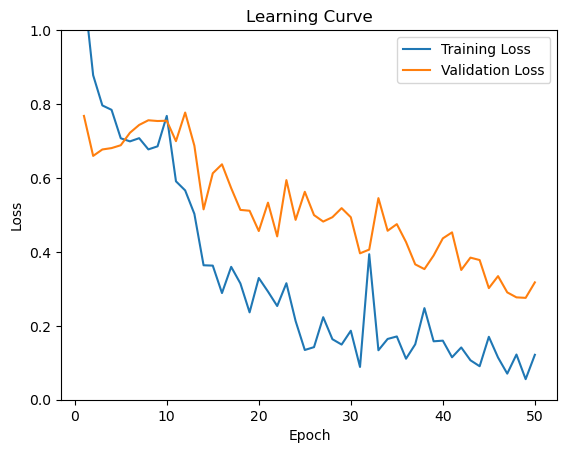

Fold 5
Accuracy Train: 0.8220000049471855. Accuracy valid: 0.9100000047683716
Recall Train: 0.7083333730697632. Recall valid: 0.8500000238418579
Precision Train: 0.7487499713897705. Precision valid: 0.9483333826065063
Best Valid Accuracy Epoc: 6. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 1.0


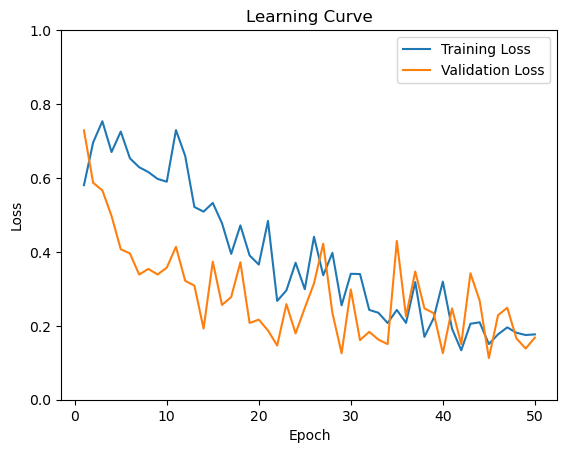

5
Fold 0: Training Loss: 0.31508292600512505, Validation Loss: 0.49964576385915277
Fold 1: Training Loss: 0.3227802046388388, Validation Loss: 0.4404350443929434
Fold 2: Training Loss: 0.3248456688225269, Validation Loss: 0.5232194852456451
Fold 3: Training Loss: 0.3337687546759844, Validation Loss: 0.5181839267909527
Fold 4: Training Loss: 0.38706287831068037, Validation Loss: 0.2852905056625605
TRAIN LOSS MEDIA: 0.3367080864906311 VALID LOSS MEDIA: 0.4533549451902509
TRAIN ACC MEDIA: 0.8426857195666859 VALID ACC MEDIA: 0.7852000041604041
TRAIN RECALL MEDIA: 0.77903813123703 VALID RECALL MEDIA: 0.7619999647140503
TRAIN PRECISION MEDIA: 0.8169309477806092 VALID PRECISION MEDIA: 0.7495000112056732


In [12]:
prueba_k_fold_resnet_pre(df_mean, 5, 10, 40, optim.SGD , 5, 0.001, True, 'H')

## RMSProp NO AUG

### PRUEBAS LR

Fold 1
Accuracy Train: 0.8293877621694488. Accuracy valid: 0.6850000036614282
Recall Train: 0.8123809695243835. Recall valid: 0.75
Precision Train: 0.8232653737068176. Precision valid: 0.6957142898014613
Best Valid Accuracy Epoc: 29. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.45000000298023224


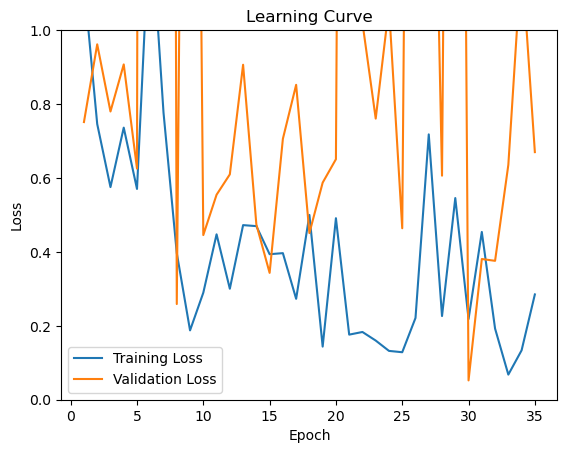

Fold 2
Accuracy Train: 0.8302040882256565. Accuracy valid: 0.7828571481364114
Recall Train: 0.8147618770599365. Recall valid: 0.8095238208770752
Precision Train: 0.8310204148292542. Precision valid: 0.6792857204164777
Best Valid Accuracy Epoc: 9. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 4. Value = 1.0 Acc val = 0.42500001192092896


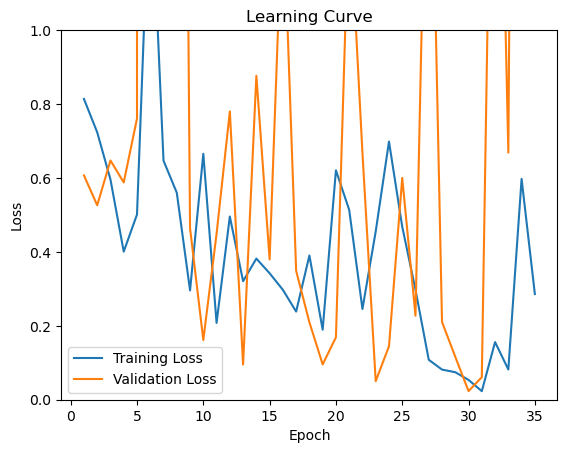

Fold 3
Accuracy Train: 0.8497959251306495. Accuracy valid: 0.7964285733444351
Recall Train: 0.8426529765129089. Recall valid: 0.7523810267448425
Precision Train: 0.8164625763893127. Precision valid: 0.8385714301041194
Best Valid Accuracy Epoc: 4. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.675000011920929


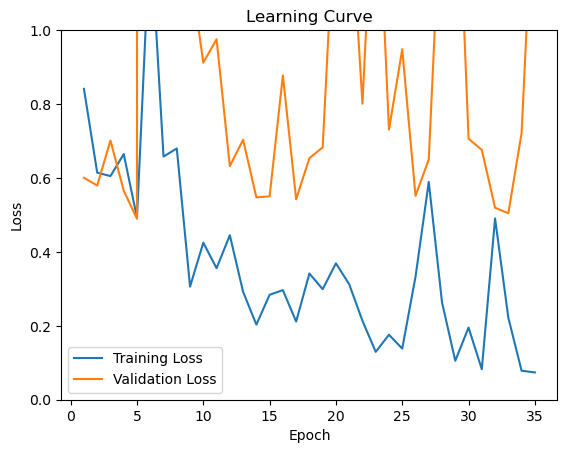

Fold 4
Accuracy Train: 0.768163273954878. Accuracy valid: 0.73642857670784
Recall Train: 0.7211564779281616. Recall valid: 0.8047618865966797
Precision Train: 0.7696599364280701. Precision valid: 0.6109523858342852
Best Valid Accuracy Epoc: 14. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 2. Value = 1.0 Acc val = 0.42500001192092896


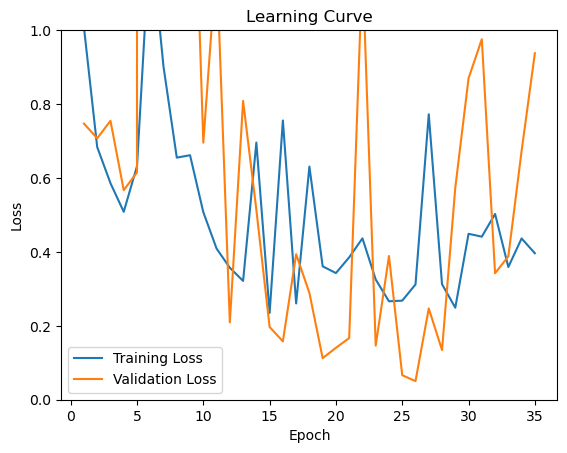

Fold 5
Accuracy Train: 0.745000006790672. Accuracy valid: 0.6590476338352476
Recall Train: 0.6910715103149414. Recall valid: 0.7142857313156128
Precision Train: 0.7144047617912292. Precision valid: 0.6347619192940849
Best Valid Accuracy Epoc: 8. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.533333346247673


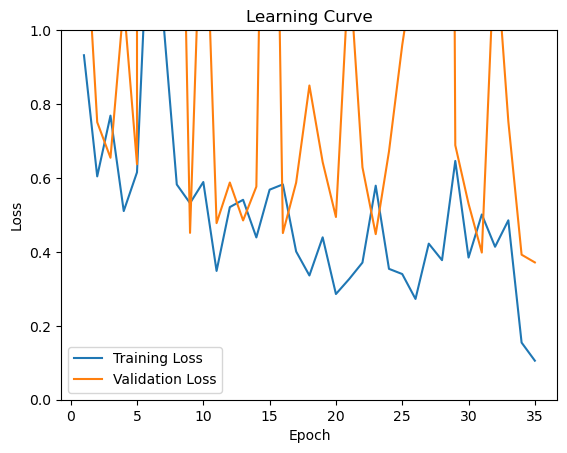

5
Fold 0: Training Loss: 0.4131777735693114, Validation Loss: 2.0249297466395157
Fold 1: Training Loss: 0.4081757039363895, Validation Loss: 13.957002655599666
Fold 2: Training Loss: 0.37319838042770115, Validation Loss: 7.4418705225389985
Fold 3: Training Loss: 0.50532277907644, Validation Loss: 11.718362927649702
Fold 4: Training Loss: 0.5077854633331299, Validation Loss: 13.589847263241452
TRAIN LOSS MEDIA: 0.4415320200685944 VALID LOSS MEDIA: 9.746402623133866
TRAIN ACC MEDIA: 0.804510211254261 VALID ACC MEDIA: 0.7319523871370726
TRAIN RECALL MEDIA: 0.7764047384262085 VALID RECALL MEDIA: 0.7661905288696289
TRAIN PRECISION MEDIA: 0.7909626364707947 VALID PRECISION MEDIA: 0.6918571490900857


In [25]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.RMSprop , 5, 0.001, False, None)

Fold 1
Accuracy Train: 0.8963265341155383. Accuracy valid: 0.7492857164570264
Recall Train: 0.8582993745803833. Recall valid: 0.5714285969734192
Precision Train: 0.8791837692260742. Precision valid: 0.7557142853736878
Best Valid Accuracy Epoc: 5. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 7. Value = 1.0 Acc val = 0.45000000298023224


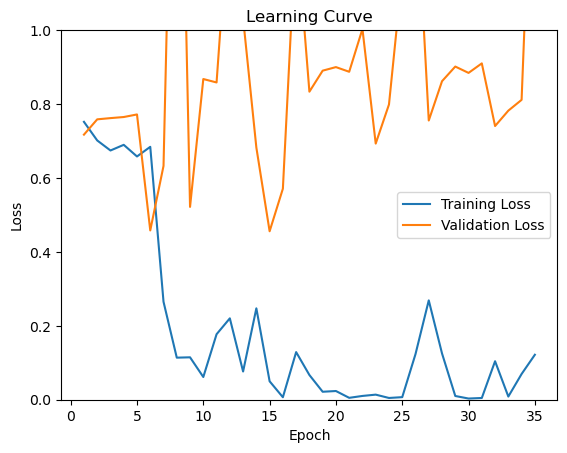

Fold 2
Accuracy Train: 0.8881632688094159. Accuracy valid: 0.9300000011920929
Recall Train: 0.8306803107261658. Recall valid: 0.8761904835700989
Precision Train: 0.8459183573722839. Precision valid: 0.8821428571428571
Best Valid Accuracy Epoc: 5. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 1.0


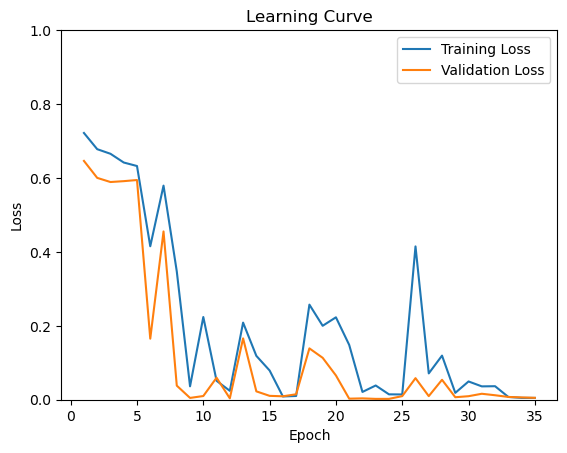

Fold 3
Accuracy Train: 0.9338775541709393. Accuracy valid: 0.8221428577389036
Recall Train: 0.9053741693496704. Recall valid: 0.8238096237182617
Precision Train: 0.9405442476272583. Precision valid: 0.9307143092155457
Best Valid Accuracy Epoc: 5. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4750000014901161


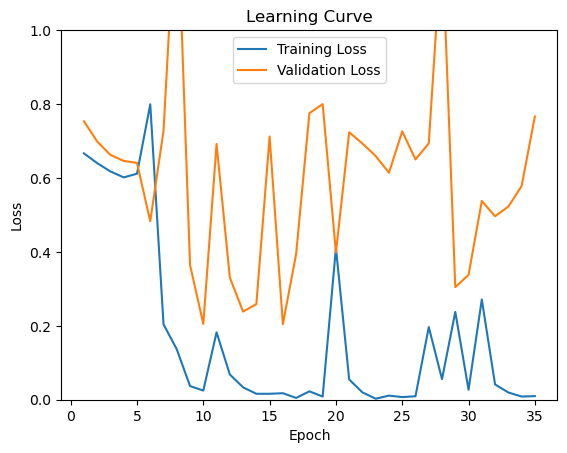

Fold 4
Accuracy Train: 0.8906122486810295. Accuracy valid: 0.7935714327863285
Recall Train: 0.8214966058731079. Recall valid: 0.8238095045089722
Precision Train: 0.8510204068252019. Precision valid: 0.6504761934280395
Best Valid Accuracy Epoc: 16. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.675000011920929


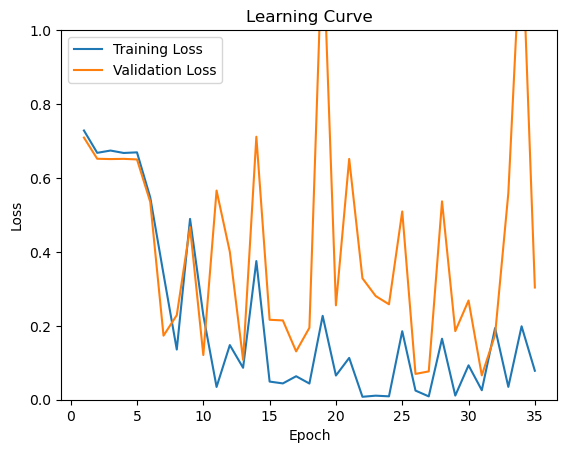

Fold 5
Accuracy Train: 0.8935714316687413. Accuracy valid: 0.7819047732012613
Recall Train: 0.7407737970352173. Recall valid: 0.7214285731315613
Precision Train: 0.7416666678019932. Precision valid: 0.8333333390099662
Best Valid Accuracy Epoc: 6. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 1.0


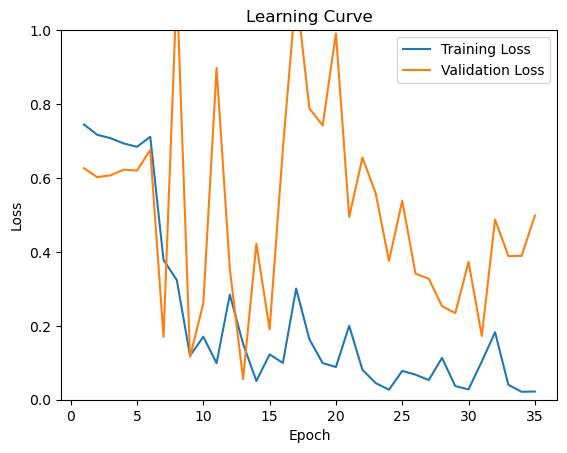

5
Fold 0: Training Loss: 0.1889520989797477, Validation Loss: 0.9041025240772537
Fold 1: Training Loss: 0.20348124391000186, Validation Loss: 0.1287156258838617
Fold 2: Training Loss: 0.1740450652781874, Validation Loss: 0.5977003382457042
Fold 3: Training Loss: 0.212748358531722, Validation Loss: 0.4132058079620557
Fold 4: Training Loss: 0.22312542923859188, Validation Loss: 0.5066484813112766
TRAIN LOSS MEDIA: 0.20047043918765017 VALID LOSS MEDIA: 0.5100745554960303
TRAIN ACC MEDIA: 0.9005102074891329 VALID ACC MEDIA: 0.8153809562751226
TRAIN RECALL MEDIA: 0.8313247561454773 VALID RECALL MEDIA: 0.7633333802223206
TRAIN PRECISION MEDIA: 0.8516666897705623 VALID PRECISION MEDIA: 0.8104761968340192


In [26]:
prueba_k_fold_resnet_pre(df_mosaic, 5, 5,30, optim.RMSprop , 5, 0.0001, False, None)

Fold 1
Accuracy Train: 0.8906122472213239. Accuracy valid: 0.7228571478809629
Recall Train: 0.9761224985122681. Recall valid: 0.6142857074737549
Precision Train: 0.8875510096549988. Precision valid: 0.8785714507102966
Best Valid Accuracy Epoc: 5. Value = 0.7750000059604645 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.45000000298023224


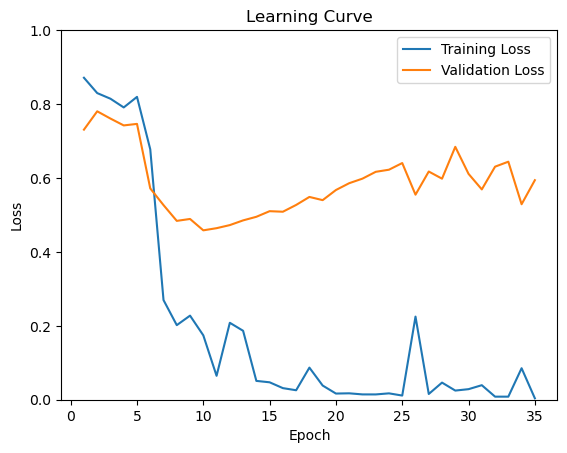

Fold 2
Accuracy Train: 0.896326533872254. Accuracy valid: 0.8221428636993681
Recall Train: 0.9251019954681396. Recall valid: 0.73333340883255
Precision Train: 0.8736734390258789. Precision valid: 0.8478571431977409
Best Valid Accuracy Epoc: 10. Value = 0.9000000059604645 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


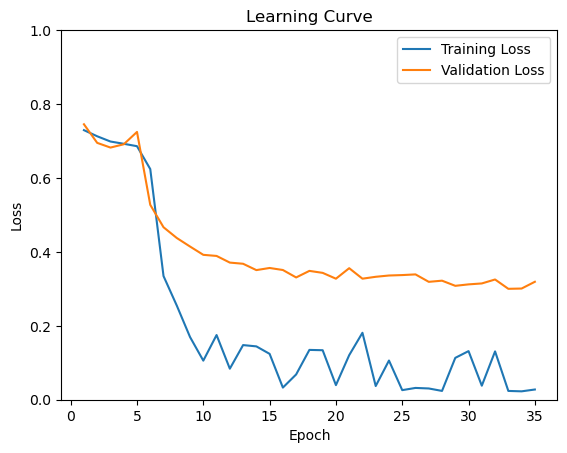

Fold 3
Accuracy Train: 0.896326533020759. Accuracy valid: 0.8257142867360796
Recall Train: 0.9075510501861572. Recall valid: 0.8142857551574707
Precision Train: 0.8730612397193909. Precision valid: 0.9107142865657807
Best Valid Accuracy Epoc: 7. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.7750000059604645


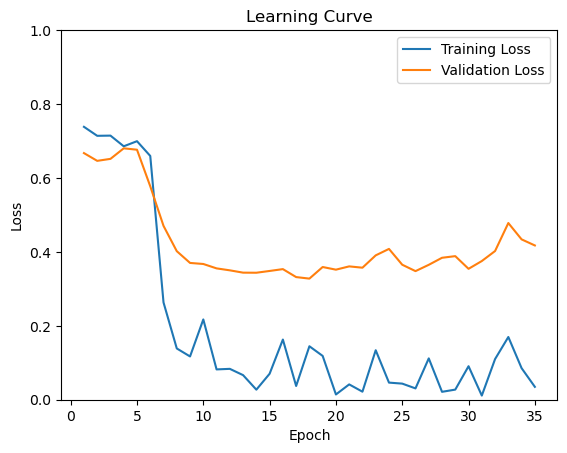

Fold 4
Accuracy Train: 0.9159183701082152. Accuracy valid: 0.738571429678372
Recall Train: 0.8631972670555115. Recall valid: 0.5190476775169373
Precision Train: 0.9034013748168945. Precision valid: 0.5083333339009967
Best Valid Accuracy Epoc: 8. Value = 0.875 Recall val = 0.5
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.75


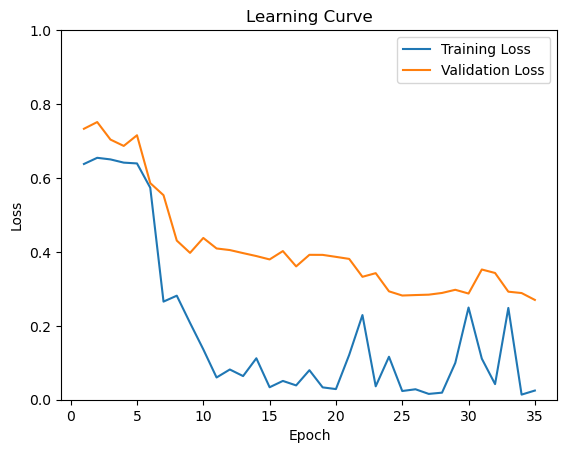

Fold 5
Accuracy Train: 0.8800000025757722. Accuracy valid: 0.8190476255757468
Recall Train: 0.7088690400123596. Recall valid: 0.7071428298950195
Precision Train: 0.7303571701049805. Precision valid: 0.8428571428571429
Best Valid Accuracy Epoc: 12. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 12. Value = 1.0 Acc val = 1.0


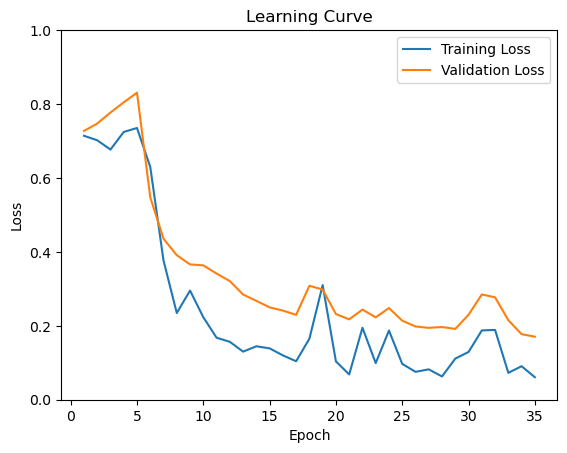

5
Fold 0: Training Loss: 0.19976771757272738, Validation Loss: 0.5858172650848116
Fold 1: Training Loss: 0.2039127080036061, Validation Loss: 0.4046217007296426
Fold 2: Training Loss: 0.19242188068372862, Validation Loss: 0.4229218671896628
Fold 3: Training Loss: 0.19000667410769634, Validation Loss: 0.41503848848598346
Fold 4: Training Loss: 0.2446131294327123, Validation Loss: 0.34416845057691847
TRAIN LOSS MEDIA: 0.20614442196009417 VALID LOSS MEDIA: 0.43451355441340384
TRAIN ACC MEDIA: 0.8958367373596647 VALID ACC MEDIA: 0.7856666707141058
TRAIN RECALL MEDIA: 0.8761683702468872 VALID RECALL MEDIA: 0.6776190996170044
TRAIN PRECISION MEDIA: 0.8536089062690735 VALID PRECISION MEDIA: 0.7976666714463916


In [27]:
prueba_k_fold_resnet_pre(df_mean, 5,5,30, optim.RMSprop , 5, 0.00001, False, None)

### PRUEBAS BS

Fold 1
Accuracy Train: 0.8222222265743072. Accuracy valid: 0.7301587422688801
Recall Train: 0.7357142567634583. Recall valid: 0.5428571105003357
Precision Train: 0.7599206566810608. Precision valid: 0.6428571939468384
Best Valid Accuracy Epoc: 6. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.4444444576899211


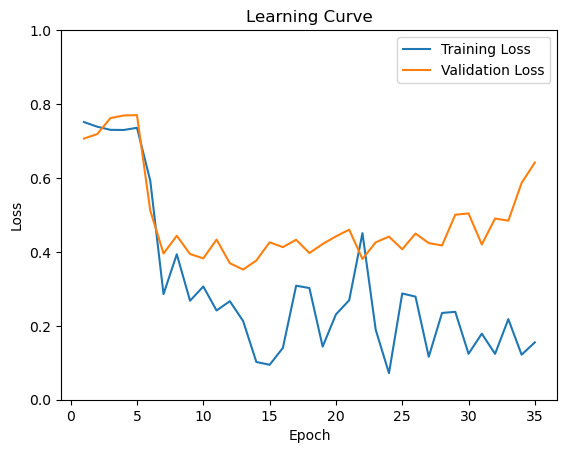

Fold 2
Accuracy Train: 0.8365079408600217. Accuracy valid: 0.7777777847789582
Recall Train: 0.6682539582252502. Recall valid: 0.7904762029647827
Precision Train: 0.7357142567634583. Precision valid: 0.7000000476837158
Best Valid Accuracy Epoc: 32. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 8. Value = 1.0 Acc val = 0.8888888955116272


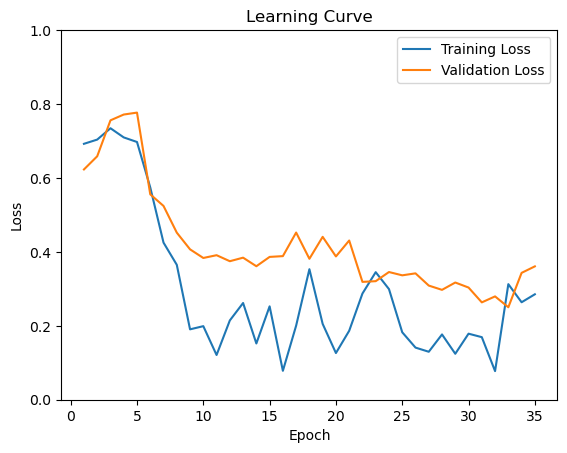

Fold 3
Accuracy Train: 0.8349206392254147. Accuracy valid: 0.8349206419218154
Recall Train: 0.7285714745521545. Recall valid: 0.6714285016059875
Precision Train: 0.7817460894584656. Precision valid: 0.6428571343421936
Best Valid Accuracy Epoc: 5. Value = 0.8888888955116272 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.5555555721124014


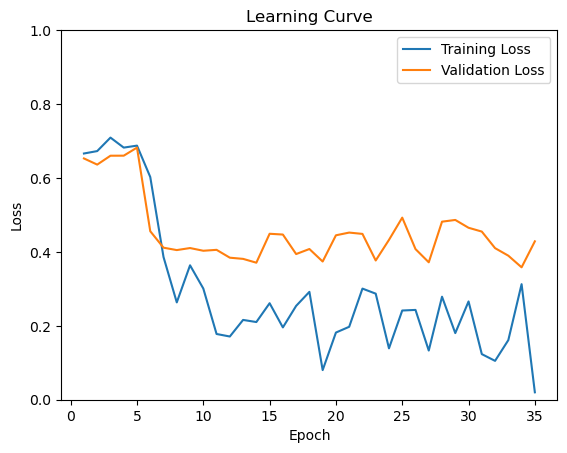

Fold 4
Accuracy Train: 0.8246031791681334. Accuracy valid: 0.8222222308317821
Recall Train: 0.7880951762199402. Recall valid: 0.9809524416923523
Precision Train: 0.7710317373275757. Precision valid: 0.769841194152832
Best Valid Accuracy Epoc: 16. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 2. Value = 1.0 Acc val = 0.5555555721124014


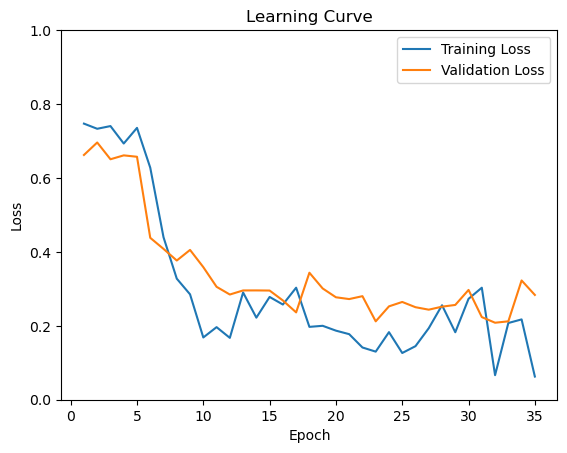

Fold 5
Accuracy Train: 0.8563492109378179. Accuracy valid: 0.9349206370966775
Recall Train: 0.7765873074531555. Recall valid: 0.9476190805435181
Precision Train: 0.7650793790817261. Precision valid: 0.9190476536750793
Best Valid Accuracy Epoc: 6. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.5000000099341074


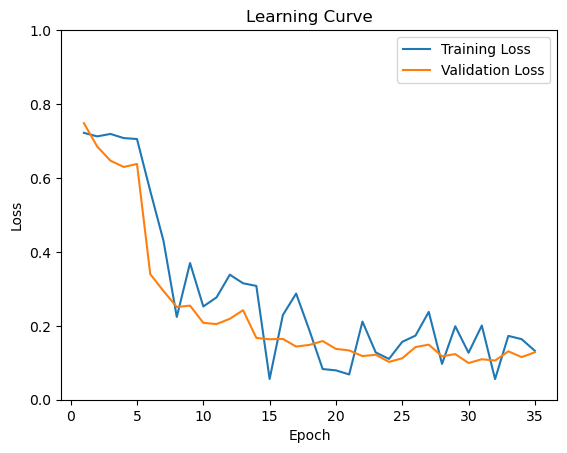

5
Fold 0: Training Loss: 0.3038040791239057, Validation Loss: 0.4843096581243333
Fold 1: Training Loss: 0.29761794741664616, Validation Loss: 0.4192845135217622
Fold 2: Training Loss: 0.2960677742958069, Validation Loss: 0.4540671715778964
Fold 3: Training Loss: 0.29888702652284077, Validation Loss: 0.34425100528058555
Fold 4: Training Loss: 0.2800612867942878, Validation Loss: 0.2358315519633747
TRAIN LOSS MEDIA: 0.2952876228306974 VALID LOSS MEDIA: 0.38754878009359045
TRAIN ACC MEDIA: 0.834920639353139 VALID ACC MEDIA: 0.8200000073796228
TRAIN RECALL MEDIA: 0.7394444346427917 VALID RECALL MEDIA: 0.7866666913032532
TRAIN PRECISION MEDIA: 0.7626984715461731 VALID PRECISION MEDIA: 0.7349206209182739


In [28]:
prueba_k_fold_resnet_pre(df_mean, 5,5,30, optim.RMSprop , 3, 0.00001, False, None)

Fold 1
Accuracy Train: 0.9064285722800663. Accuracy valid: 0.48035714285714287
Recall Train: 0.8014694452285767. Recall valid: 0.3523809313774109
Precision Train: 0.817142857824053. Precision valid: 0.5285714285714286
Best Valid Accuracy Epoc: 17. Value = 0.9375 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 17. Value = 0.8333333730697632 Acc val = 0.9375


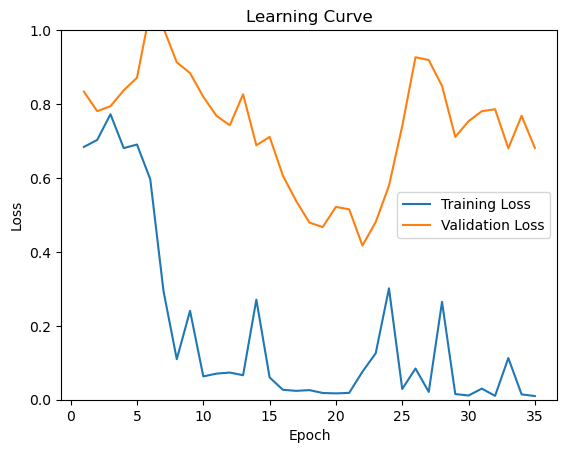

Fold 2
Accuracy Train: 0.8838095246042523. Accuracy valid: 0.8964285714285715
Recall Train: 0.9485714435577393. Recall valid: 0.8809524774551392
Precision Train: 0.8653469681739807. Precision valid: 0.9156292676925659
Best Valid Accuracy Epoc: 23. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.75


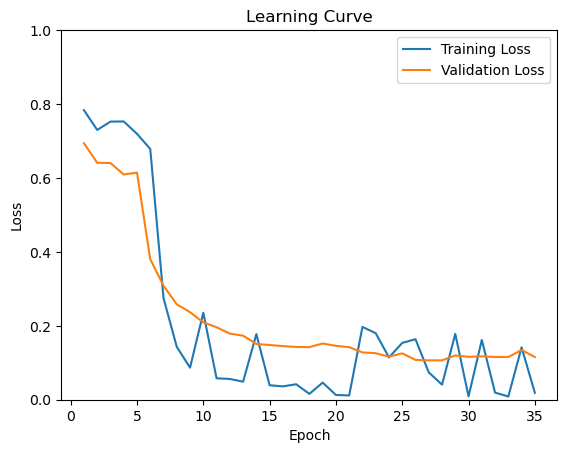

Fold 3
Accuracy Train: 0.9142857153075082. Accuracy valid: 0.8303571428571429
Recall Train: 0.8908026814460754. Recall valid: 0.7285714745521545
Precision Train: 0.9236190915107727. Precision valid: 0.857142858845847
Best Valid Accuracy Epoc: 7. Value = 0.9375 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 5. Value = 0.8333333730697632 Acc val = 0.875


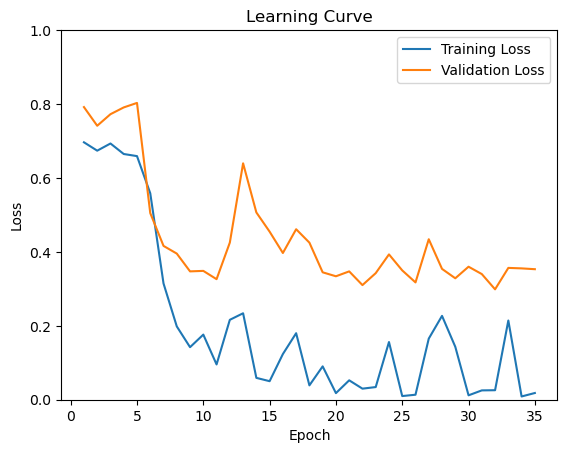

Fold 4
Accuracy Train: 0.9069047626427241. Accuracy valid: 0.8482142857142857
Recall Train: 0.864693820476532. Recall valid: 0.3321428596973419
Precision Train: 0.8966666460037231. Precision valid: 0.30928571607385363
Best Valid Accuracy Epoc: 22. Value = 0.9375 Recall val = 0.5
Best Valid Recall Epoc: 20. Value = 0.5 Acc val = 0.875


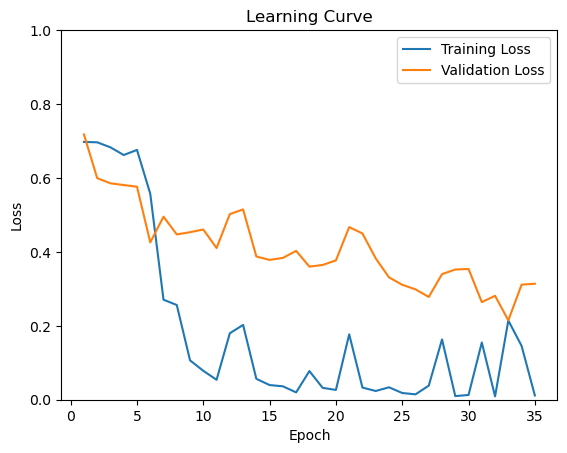

Fold 5
Accuracy Train: 0.92. Accuracy valid: 0.8071428571428572
Recall Train: 0.814081609249115. Recall valid: 0.6285714507102966
Precision Train: 0.8285714302744184. Precision valid: 0.8571428571428571
Best Valid Accuracy Epoc: 6. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 6. Value = 0.75 Acc val = 0.875


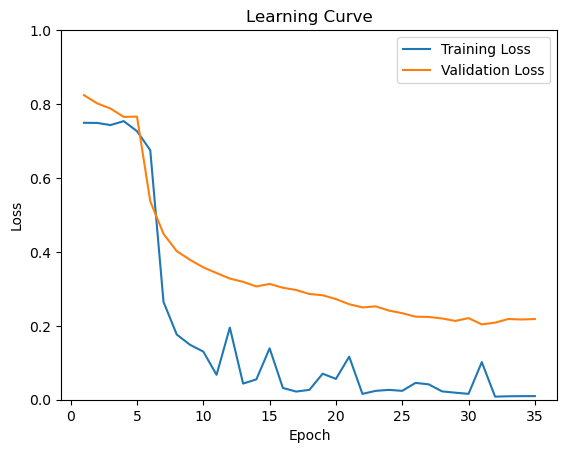

5
Fold 0: Training Loss: 0.18893132329519305, Validation Loss: 0.7350886093718665
Fold 1: Training Loss: 0.2046251011214086, Validation Loss: 0.2274398174136877
Fold 2: Training Loss: 0.200525934781347, Validation Loss: 0.4419148230126926
Fold 3: Training Loss: 0.18477031255939178, Validation Loss: 0.41063616701534816
Fold 4: Training Loss: 0.1804199515176671, Validation Loss: 0.3578172381435122
TRAIN LOSS MEDIA: 0.19185452465500152 VALID LOSS MEDIA: 0.4345793309914214
TRAIN ACC MEDIA: 0.9062857149669103 VALID ACC MEDIA: 0.7725
TRAIN RECALL MEDIA: 0.8639238476753235 VALID RECALL MEDIA: 0.5845237970352173
TRAIN PRECISION MEDIA: 0.8662693987573895 VALID PRECISION MEDIA: 0.6935544256653104


In [29]:
prueba_k_fold_resnet_pre(df_mean, 5,5,30, optim.RMSprop , 8, 0.00001, False, None)

Fold 1
Accuracy Train: 0.9087301609062014. Accuracy valid: 0.6920635061604636
Recall Train: 0.9283937811851501. Recall valid: 0.3499999940395355
Precision Train: 0.8931820392608643. Precision valid: 0.7904761910438538
Best Valid Accuracy Epoc: 10. Value = 0.7777777910232544 Recall val = 0.5
Best Valid Recall Epoc: 10. Value = 0.5 Acc val = 0.7777777910232544


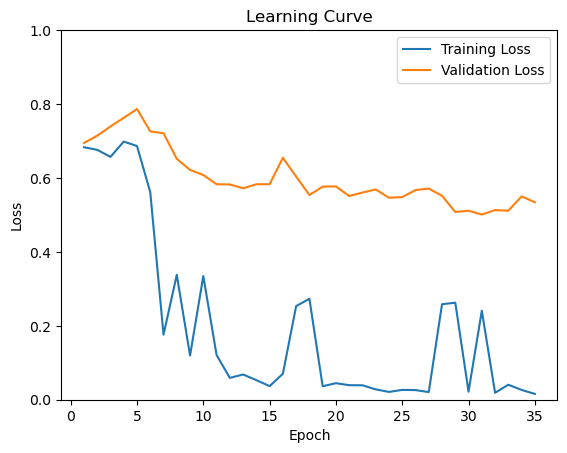

Fold 2
Accuracy Train: 0.914087302344186. Accuracy valid: 0.8126984238624573
Recall Train: 0.8117460012435913. Recall valid: 0.5785714387893677
Precision Train: 0.8174603172710964. Precision valid: 0.8
Best Valid Accuracy Epoc: 24. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 24. Value = 1.0 Acc val = 1.0


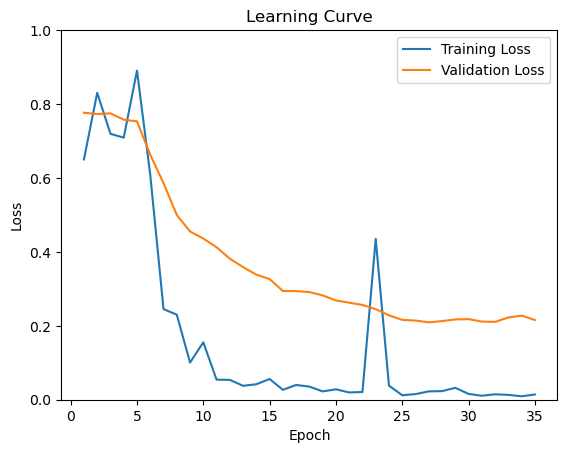

Fold 3
Accuracy Train: 0.9083333347524916. Accuracy valid: 0.8000000102179391
Recall Train: 0.9285224080085754. Recall valid: 0.6714285612106323
Precision Train: 0.8895331025123596. Precision valid: 0.8828571430274419
Best Valid Accuracy Epoc: 8. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.5555555820465088


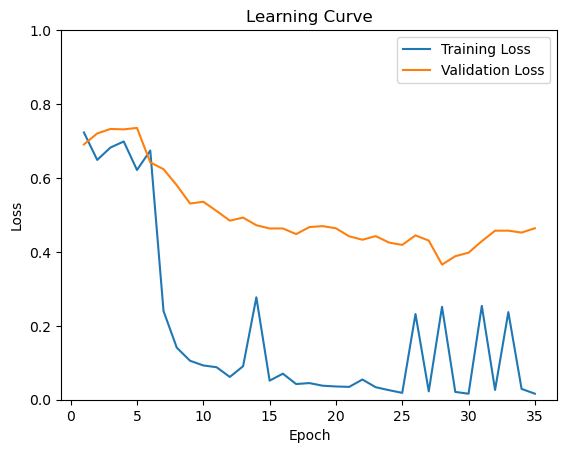

Fold 4
Accuracy Train: 0.8732142868496123. Accuracy valid: 0.7365079505102975
Recall Train: 0.9424036145210266. Recall valid: 0.8642857074737549
Precision Train: 0.8717197775840759. Precision valid: 0.6595010757446289
Best Valid Accuracy Epoc: 32. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444477558136


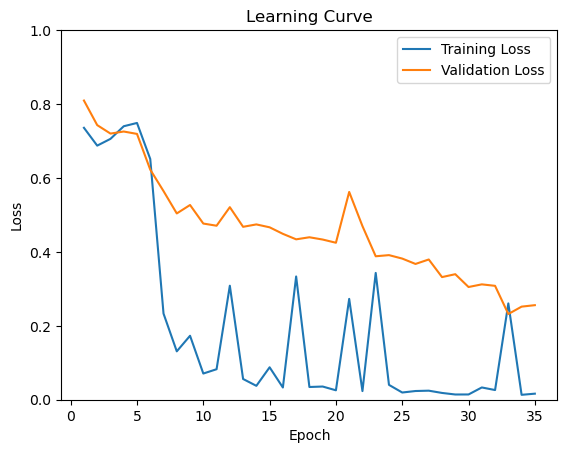

Fold 5
Accuracy Train: 0.9083333333333333. Accuracy valid: 0.7892857142857143
Recall Train: 0.8763718605041504. Recall valid: 0.8214285969734192
Precision Train: 0.8705874681472778. Precision valid: 0.8530612587928772
Best Valid Accuracy Epoc: 12. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.5


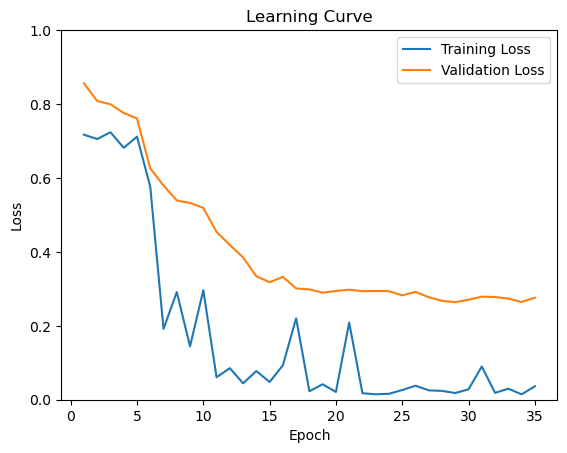

5
Fold 0: Training Loss: 0.20093703615878308, Validation Loss: 0.5997397746358599
Fold 1: Training Loss: 0.17806095387786627, Validation Loss: 0.37401978969573973
Fold 2: Training Loss: 0.19148793263094765, Validation Loss: 0.5059309950896672
Fold 3: Training Loss: 0.20156274451208966, Validation Loss: 0.4648202738591603
Fold 4: Training Loss: 0.1817274278828076, Validation Loss: 0.41214461837496075
TRAIN LOSS MEDIA: 0.19075521901249887 VALID LOSS MEDIA: 0.47133109033107756
TRAIN ACC MEDIA: 0.902539683637165 VALID ACC MEDIA: 0.7661111210073743
TRAIN RECALL MEDIA: 0.897487461566925 VALID RECALL MEDIA: 0.6571428775787354
TRAIN PRECISION MEDIA: 0.8684965409551347 VALID PRECISION MEDIA: 0.7971791337217604


In [30]:
prueba_k_fold_resnet_pre(df_mean, 5,5,30, optim.RMSprop , 16, 0.00001, False, None)

### PRUEBAS EPOCS

Fold 1
Accuracy Train: 0.8388888939718404. Accuracy valid: 0.6688889010747274
Recall Train: 0.7694444060325623. Recall valid: 0.48666664958000183
Precision Train: 0.7688890099525452. Precision valid: 0.5644444227218628
Best Valid Accuracy Epoc: 13. Value = 0.8888888955116272 Recall val = 0.8333333134651184
Best Valid Recall Epoc: 13. Value = 0.8333333134651184 Acc val = 0.8888888955116272


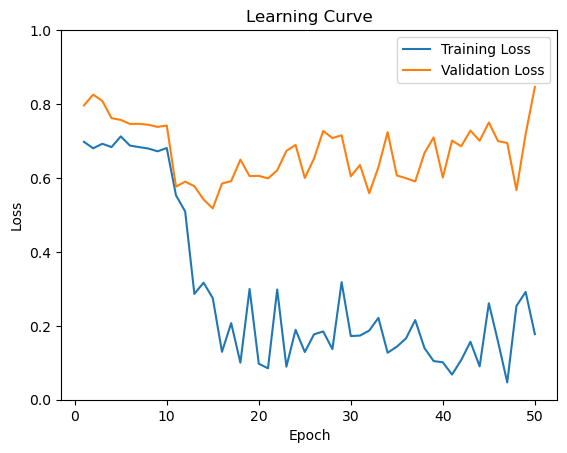

Fold 2
Accuracy Train: 0.8044444496929646. Accuracy valid: 0.6888888986905417
Recall Train: 0.7933333516120911. Recall valid: 0.7566666603088379
Precision Train: 0.7522222399711609. Precision valid: 0.5899999737739563
Best Valid Accuracy Epoc: 39. Value = 0.8888888955116272 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444576899211


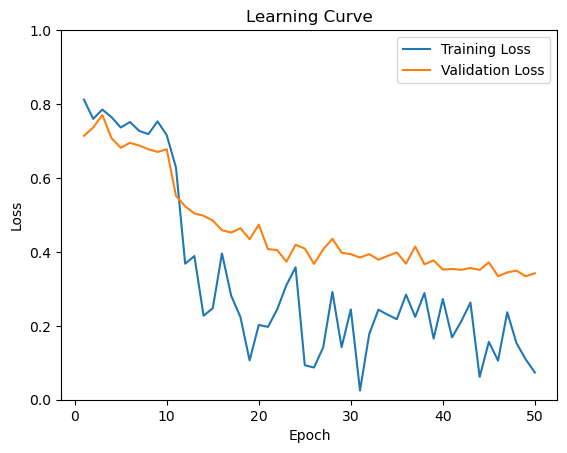

Fold 3
Accuracy Train: 0.838611115217209. Accuracy valid: 0.8177777866522472
Recall Train: 0.6205555200576782. Recall valid: 0.5233333706855774
Precision Train: 0.6650000025331974. Precision valid: 0.5266666823625564
Best Valid Accuracy Epoc: 11. Value = 0.8888888955116272 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 11. Value = 0.6666666865348816 Acc val = 0.8888888955116272


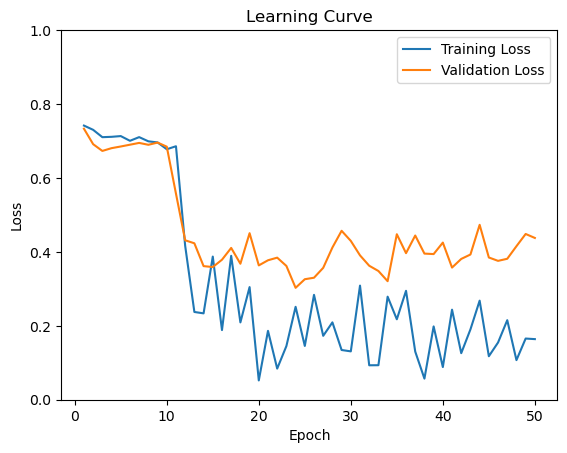

Fold 4
Accuracy Train: 0.809722226758798. Accuracy valid: 0.6822222316265107
Recall Train: 0.6055555939674377. Recall valid: 0.6466667056083679
Precision Train: 0.6700000166893005. Precision valid: 0.4777778387069702
Best Valid Accuracy Epoc: 18. Value = 0.8888888955116272 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 25. Value = 1.0 Acc val = 0.777777781089147


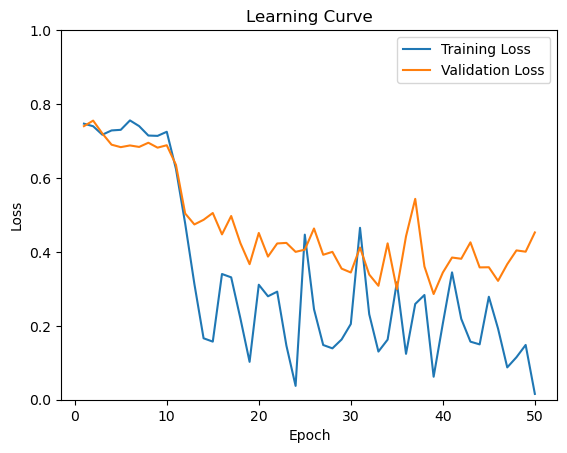

Fold 5
Accuracy Train: 0.8383333374063174. Accuracy valid: 0.9000000019868214
Recall Train: 0.6641666889190674. Recall valid: 0.8799999952316284
Precision Train: 0.7166666984558105. Precision valid: 0.8533332943916321
Best Valid Accuracy Epoc: 10. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 10. Value = 1.0 Acc val = 1.0


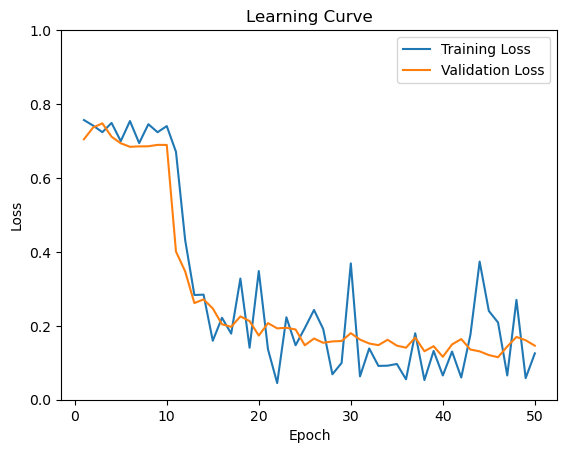

5
Fold 0: Training Loss: 0.29228969000279903, Validation Loss: 0.6701921968658766
Fold 1: Training Loss: 0.3274755685776472, Validation Loss: 0.4638004988431931
Fold 2: Training Loss: 0.3090445087850094, Validation Loss: 0.45467108649512133
Fold 3: Training Loss: 0.32814771849662067, Validation Loss: 0.46849244549870483
Fold 4: Training Loss: 0.295396157130599, Validation Loss: 0.2845577183614174
TRAIN LOSS MEDIA: 0.31047072859853503 VALID LOSS MEDIA: 0.4683427892128626
TRAIN ACC MEDIA: 0.8260000046094259 VALID ACC MEDIA: 0.7515555640061697
TRAIN RECALL MEDIA: 0.6906111240386963 VALID RECALL MEDIA: 0.658666729927063
TRAIN PRECISION MEDIA: 0.7145555935204029 VALID PRECISION MEDIA: 0.6024444423913955


In [16]:
prueba_k_fold_resnet_pre(df_mean, 5,10,40, optim.RMSprop , 3, 0.00001, False, None)

Fold 1
Accuracy Train: 0.8694444471881503. Accuracy valid: 0.7428571567648934
Recall Train: 0.7067461013793945. Recall valid: 0.44285714626312256
Precision Train: 0.745238093818937. Precision valid: 0.5952380895614624
Best Valid Accuracy Epoc: 22. Value = 0.8888888955116272 Recall val = 0.8333333134651184
Best Valid Recall Epoc: 22. Value = 0.8333333134651184 Acc val = 0.8888888955116272


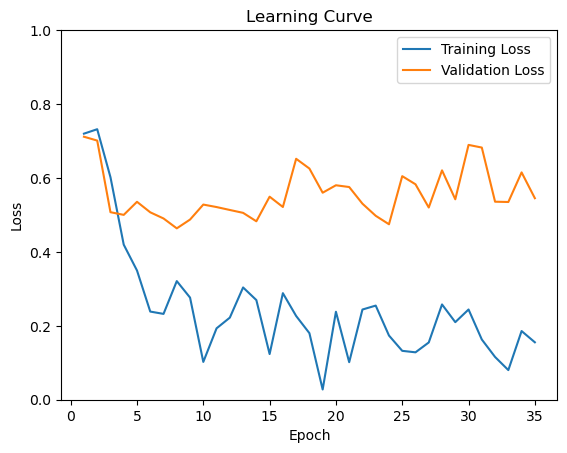

Fold 2
Accuracy Train: 0.8873015897614616. Accuracy valid: 0.9111111155578069
Recall Train: 0.7198413014411926. Recall valid: 0.8714285492897034
Precision Train: 0.7690476230212621. Precision valid: 0.8222222226006645
Best Valid Accuracy Epoc: 9. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 9. Value = 1.0 Acc val = 1.0


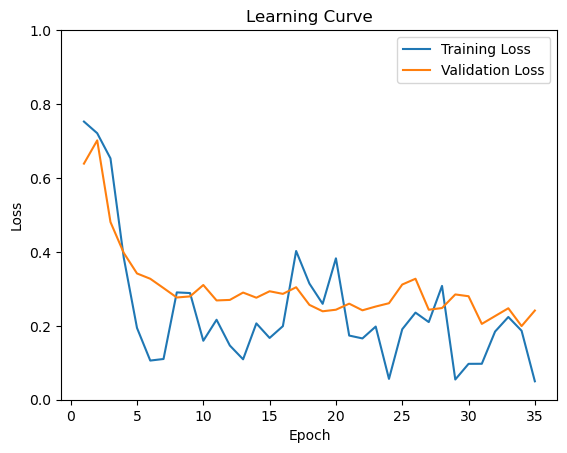

Fold 3
Accuracy Train: 0.8757936533717882. Accuracy valid: 0.8190476281302316
Recall Train: 0.7031745910644531. Recall valid: 0.5571427941322327
Precision Train: 0.7547619049038206. Precision valid: 0.5857143027441842
Best Valid Accuracy Epoc: 8. Value = 0.8888888955116272 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 8. Value = 0.6666666865348816 Acc val = 0.8888888955116272


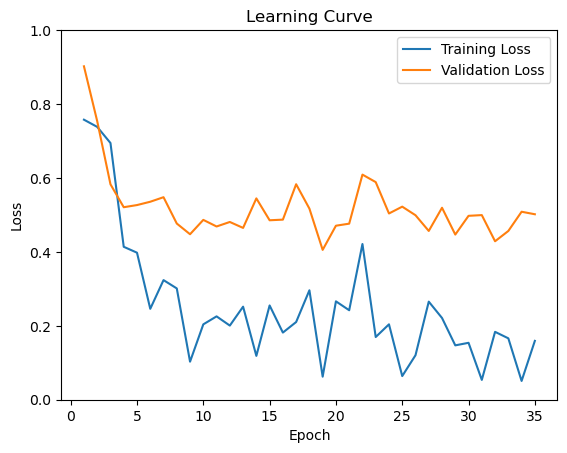

Fold 4
Accuracy Train: 0.8424603218124026. Accuracy valid: 0.8285714368025463
Recall Train: 0.7873015403747559. Recall valid: 0.9857142567634583
Precision Train: 0.7992063164710999. Precision valid: 0.7984126806259155
Best Valid Accuracy Epoc: 2. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 2. Value = 1.0 Acc val = 1.0


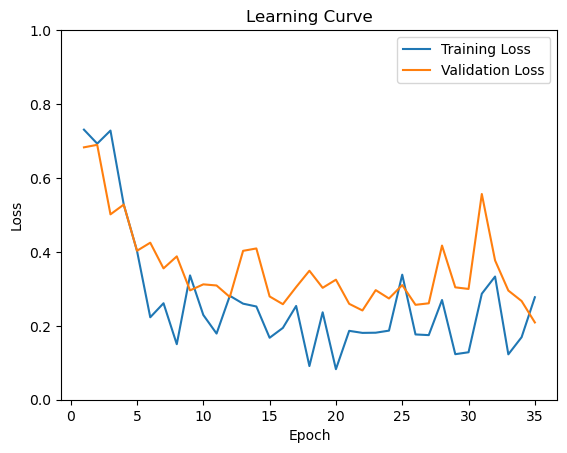

Fold 5
Accuracy Train: 0.8936507965837206. Accuracy valid: 0.9079365125724248
Recall Train: 0.7551587224006653. Recall valid: 0.8809524178504944
Precision Train: 0.7928571701049805. Precision valid: 0.8349206447601318
Best Valid Accuracy Epoc: 7. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 7. Value = 1.0 Acc val = 1.0


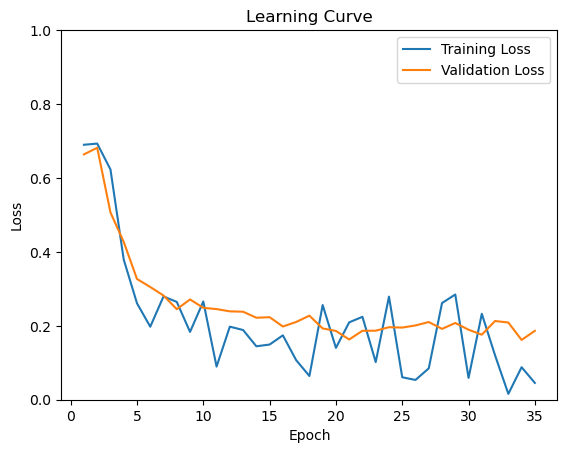

5
Fold 0: Training Loss: 0.2476360329559871, Validation Loss: 0.5570140033960344
Fold 1: Training Loss: 0.2427396557160786, Validation Loss: 0.30326576899914515
Fold 2: Training Loss: 0.25343201852270536, Validation Loss: 0.5201245043249358
Fold 3: Training Loss: 0.26904897285359247, Validation Loss: 0.35498298179535637
Fold 4: Training Loss: 0.21339976196842533, Validation Loss: 0.25752731591817873
TRAIN LOSS MEDIA: 0.2452512884033578 VALID LOSS MEDIA: 0.39858291488673003
TRAIN ACC MEDIA: 0.8737301617435046 VALID ACC MEDIA: 0.8419047699655806
TRAIN RECALL MEDIA: 0.7344444394111633 VALID RECALL MEDIA: 0.7476190328598022
TRAIN PRECISION MEDIA: 0.77222222166402 VALID PRECISION MEDIA: 0.7273015880584717


In [17]:
prueba_k_fold_resnet_pre(df_mean, 5,2,33, optim.RMSprop , 3, 0.00001, False, None)

Fold 1
Accuracy Train: 0.8505555592477321. Accuracy valid: 0.7955555669466655
Recall Train: 0.7622222304344177. Recall valid: 0.6233333349227905
Precision Train: 0.7947221994400024. Precision valid: 0.7277777791023254
Best Valid Accuracy Epoc: 7. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.6666666865348816


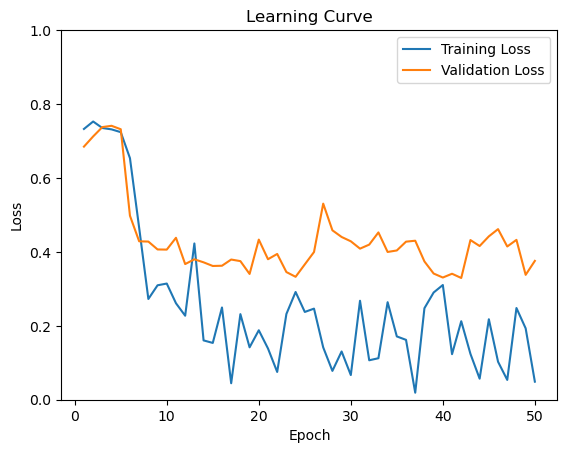

Fold 2
Accuracy Train: 0.8500000032285849. Accuracy valid: 0.8311111183961234
Recall Train: 0.8119444847106934. Recall valid: 0.8933334350585938
Precision Train: 0.7961110472679138. Precision valid: 0.7311111688613892
Best Valid Accuracy Epoc: 31. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444576899211


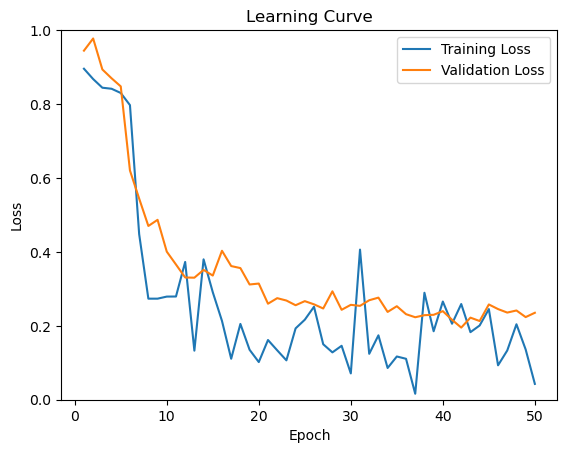

Fold 3
Accuracy Train: 0.8702777813374998. Accuracy valid: 0.8244444519281388
Recall Train: 0.7280555963516235. Recall valid: 0.6033333539962769
Precision Train: 0.7841666340827942. Precision valid: 0.596666693687439
Best Valid Accuracy Epoc: 9. Value = 0.8888888955116272 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 5. Value = 0.6666666865348816 Acc val = 0.7777777910232544


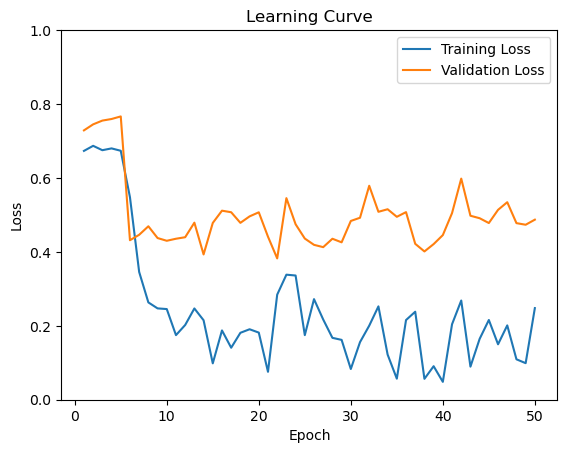

Fold 4
Accuracy Train: 0.8613888926804067. Accuracy valid: 0.8577777850627899
Recall Train: 0.7730555534362793. Recall valid: 0.9666666388511658
Precision Train: 0.8022221326828003. Precision valid: 0.8122222423553467
Best Valid Accuracy Epoc: 5. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 1.0


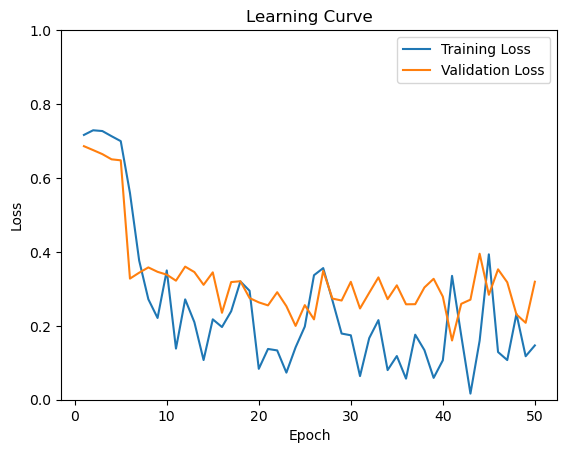

Fold 5
Accuracy Train: 0.8883333371579647. Accuracy valid: 0.8677777840693792
Recall Train: 0.7341666221618652. Recall valid: 0.6733333468437195
Precision Train: 0.7891666889190674. Precision valid: 0.6666666814684867
Best Valid Accuracy Epoc: 5. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 1.0


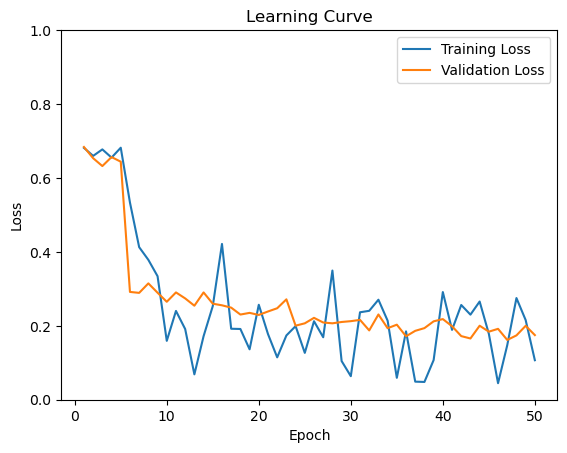

5
Fold 0: Training Loss: 0.2548283885419369, Validation Loss: 0.4326167607307434
Fold 1: Training Loss: 0.2721339649707079, Validation Loss: 0.3573418918748697
Fold 2: Training Loss: 0.2430795042216778, Validation Loss: 0.49991813207666075
Fold 3: Training Loss: 0.2486187633499503, Validation Loss: 0.32978195930520693
Fold 4: Training Loss: 0.25197964400053025, Validation Loss: 0.26698611068228884
TRAIN LOSS MEDIA: 0.2541280530169606 VALID LOSS MEDIA: 0.3773289709339539
TRAIN ACC MEDIA: 0.8641111147304377 VALID ACC MEDIA: 0.8353333412806194
TRAIN RECALL MEDIA: 0.761888861656189 VALID RECALL MEDIA: 0.7520000338554382
TRAIN PRECISION MEDIA: 0.7932776808738708 VALID PRECISION MEDIA: 0.7068889130949974


In [18]:
prueba_k_fold_resnet_pre(df_mean, 5,5,45, optim.RMSprop , 3, 0.00001, False, None)

## RMSProp DATA AUG

Fold 1
Accuracy Train: 0.8126984183986982. Accuracy valid: 0.7301587431203751
Recall Train: 0.6936508417129517. Recall valid: 0.4571428596973419
Precision Train: 0.7630952596664429. Precision valid: 0.5904762080737522
Best Valid Accuracy Epoc: 6. Value = 0.7777777910232544 Recall val = 0.5
Best Valid Recall Epoc: 5. Value = 0.5 Acc val = 0.6666666766007742


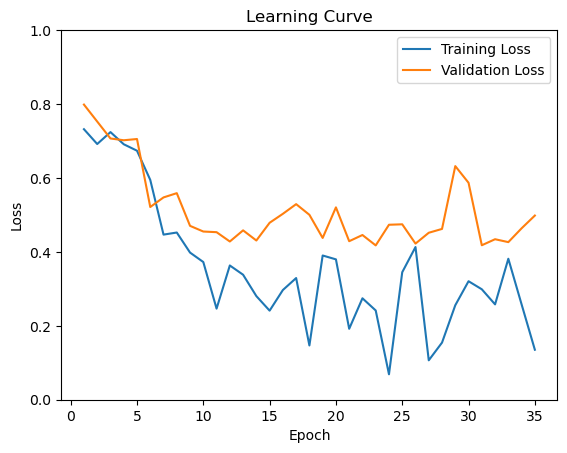

Fold 2
Accuracy Train: 0.8103174653081666. Accuracy valid: 0.8031746103650048
Recall Train: 0.7698413729667664. Recall valid: 0.6666666269302368
Precision Train: 0.7777777910232544. Precision valid: 0.6142856478691101
Best Valid Accuracy Epoc: 7. Value = 0.8888888955116272 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444576899211


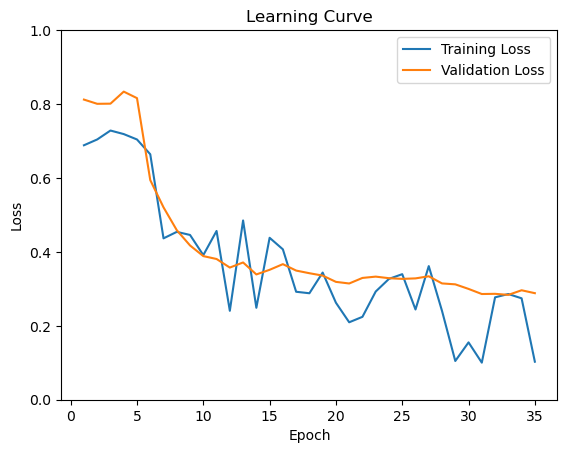

Fold 3
Accuracy Train: 0.8361111153449331. Accuracy valid: 0.8253968341009957
Recall Train: 0.642460286617279. Recall valid: 0.5428571105003357
Precision Train: 0.6976190481867109. Precision valid: 0.5523809688431877
Best Valid Accuracy Epoc: 8. Value = 0.8888888955116272 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 8. Value = 0.6666666865348816 Acc val = 0.8888888955116272


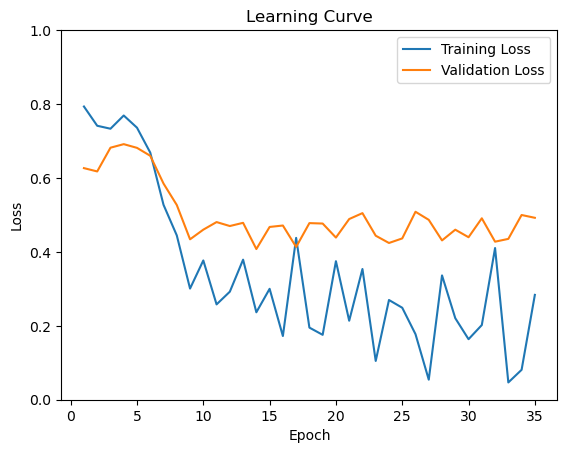

Fold 4
Accuracy Train: 0.8420634965101879. Accuracy valid: 0.7301587397143954
Recall Train: 0.7666667103767395. Recall valid: 0.7523809671401978
Precision Train: 0.800000011920929. Precision valid: 0.5777778029441833
Best Valid Accuracy Epoc: 21. Value = 0.8888888955116272 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.5555555621782938


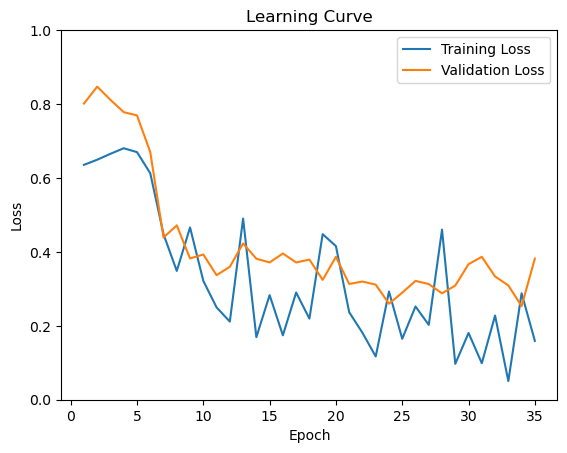

Fold 5
Accuracy Train: 0.8277777830759685. Accuracy valid: 0.7396825472513834
Recall Train: 0.649206280708313. Recall valid: 0.6523809432983398
Precision Train: 0.7023808360099792. Precision valid: 0.5492063760757446
Best Valid Accuracy Epoc: 9. Value = 0.8888888955116272 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.5000000099341074


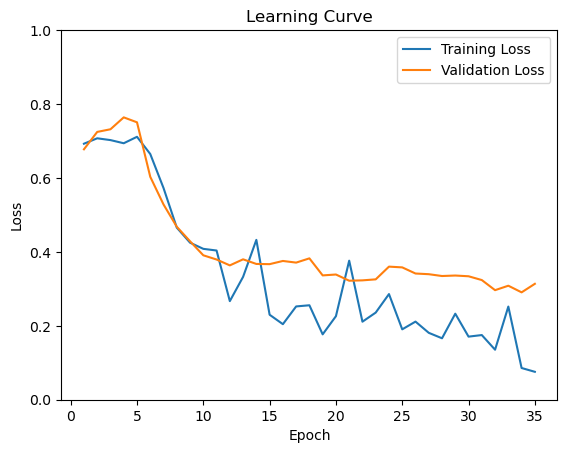

5
Fold 0: Training Loss: 0.3569405525922775, Validation Loss: 0.5141239592007227
Fold 1: Training Loss: 0.36965367900473733, Validation Loss: 0.4176686982313792
Fold 2: Training Loss: 0.34512690220560344, Validation Loss: 0.5004760521153608
Fold 3: Training Loss: 0.32735210838062423, Validation Loss: 0.42424466957648593
Fold 4: Training Loss: 0.33741988028798786, Validation Loss: 0.41816006686006274
TRAIN LOSS MEDIA: 0.3472986244942461 VALID LOSS MEDIA: 0.4549346891968023
TRAIN ACC MEDIA: 0.8257936557275908 VALID ACC MEDIA: 0.765714294910431
TRAIN RECALL MEDIA: 0.704365074634552 VALID RECALL MEDIA: 0.6142856478691101
TRAIN PRECISION MEDIA: 0.7481745893614633 VALID PRECISION MEDIA: 0.5768254007611956


In [19]:
prueba_k_fold_resnet_pre(df_mean, 5,5,30, optim.RMSprop , 3, 0.00001, True, None)

## RMSPROP GLOROT/HE INI

Fold 1
Accuracy Train: 0.8019841316200438. Accuracy valid: 0.7142857273419698
Recall Train: 0.791269838809967. Recall valid: 0.5571428537368774
Precision Train: 0.757539689540863. Precision valid: 0.6063492298126221
Best Valid Accuracy Epoc: 8. Value = 0.7777777910232544 Recall val = 0.5
Best Valid Recall Epoc: 3. Value = 1.0 Acc val = 0.4444444576899211


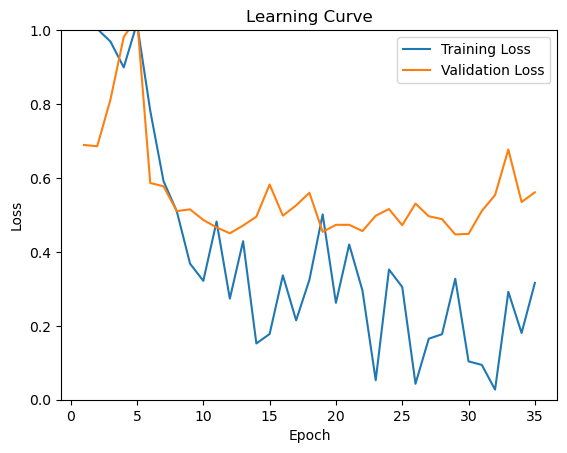

Fold 2
Accuracy Train: 0.8293650838590803. Accuracy valid: 0.8349206433409737
Recall Train: 0.7753968238830566. Recall valid: 0.6190475821495056
Precision Train: 0.7992063760757446. Precision valid: 0.6238095164299011
Best Valid Accuracy Epoc: 6. Value = 0.8888888955116272 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 6. Value = 0.6666666865348816 Acc val = 0.8888888955116272


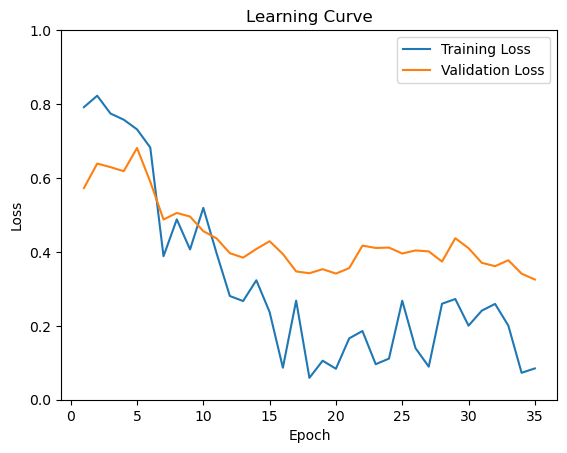

Fold 3
Accuracy Train: 0.8178571477532388. Accuracy valid: 0.8253968341009957
Recall Train: 0.6087300777435303. Recall valid: 0.5619047284126282
Precision Train: 0.6571428609745843. Precision valid: 0.5904762080737522
Best Valid Accuracy Epoc: 10. Value = 0.8888888955116272 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 10. Value = 0.6666666865348816 Acc val = 0.8888888955116272


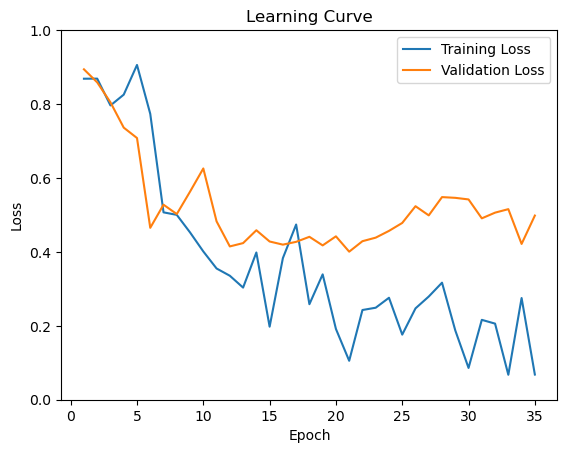

Fold 4
Accuracy Train: 0.8250000047541799. Accuracy valid: 0.7428571559133984
Recall Train: 0.6158730387687683. Recall valid: 0.5904761552810669
Precision Train: 0.6761904725006649. Precision valid: 0.449206348827907
Best Valid Accuracy Epoc: 23. Value = 0.8888888955116272 Recall val = 1.0
Best Valid Recall Epoc: 23. Value = 1.0 Acc val = 0.8888888955116272


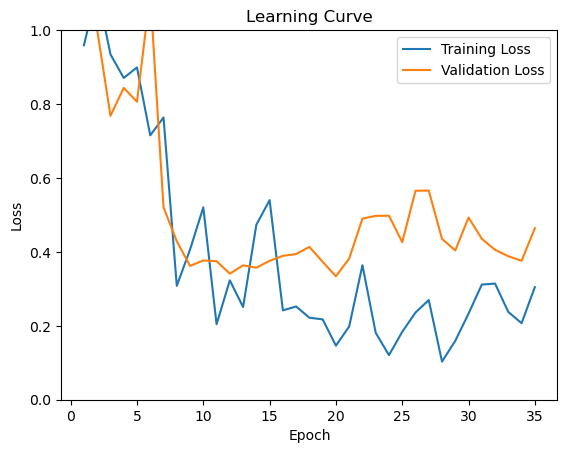

Fold 5
Accuracy Train: 0.8063492118602708. Accuracy valid: 0.8460317532221477
Recall Train: 0.7440475821495056. Recall valid: 0.6904761791229248
Precision Train: 0.757539689540863. Precision valid: 0.6714285612106323
Best Valid Accuracy Epoc: 9. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.5000000099341074


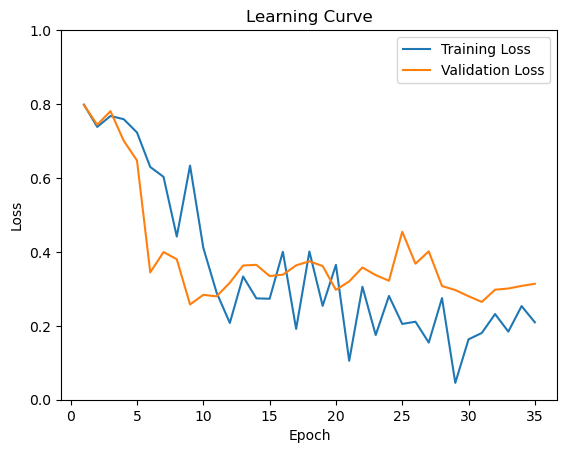

5
Fold 0: Training Loss: 0.39424142608685153, Validation Loss: 0.557682246324562
Fold 1: Training Loss: 0.31761638107044354, Validation Loss: 0.4371167881148202
Fold 2: Training Loss: 0.37523803945098605, Validation Loss: 0.5238301897687573
Fold 3: Training Loss: 0.39373652232544765, Validation Loss: 0.5072879095162665
Fold 4: Training Loss: 0.3564712089087282, Validation Loss: 0.3902845526025408
TRAIN LOSS MEDIA: 0.36746071556849136 VALID LOSS MEDIA: 0.4832403372653894
TRAIN ACC MEDIA: 0.8161111159693627 VALID ACC MEDIA: 0.7926984227838971
TRAIN RECALL MEDIA: 0.7070634961128235 VALID RECALL MEDIA: 0.6038094758987427
TRAIN PRECISION MEDIA: 0.729523817726544 VALID PRECISION MEDIA: 0.5882539728709629


In [20]:
prueba_k_fold_resnet_pre(df_mean, 5,5,30, optim.RMSprop , 3, 0.00001, True, 'G')

Fold 1
Accuracy Train: 0.8047619099418323. Accuracy valid: 0.7746031846318926
Recall Train: 0.8206348419189453. Recall valid: 0.7285714149475098
Precision Train: 0.7658730149269104. Precision valid: 0.7428570985794067
Best Valid Accuracy Epoc: 8. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444576899211


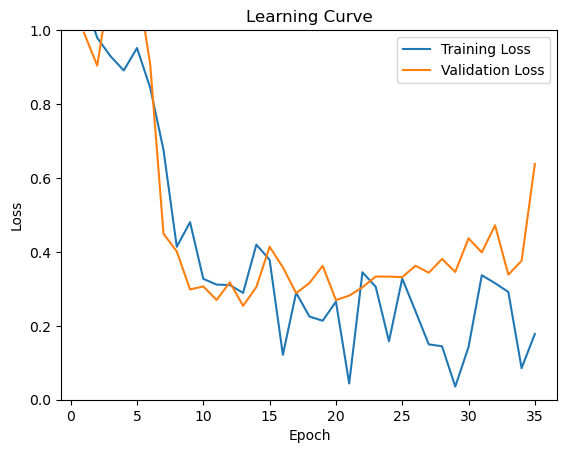

Fold 2
Accuracy Train: 0.8146825443421092. Accuracy valid: 0.8222222294126238
Recall Train: 0.7960317134857178. Recall valid: 0.9238094687461853
Precision Train: 0.7809523940086365. Precision valid: 0.8365079164505005
Best Valid Accuracy Epoc: 19. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.6666666766007742


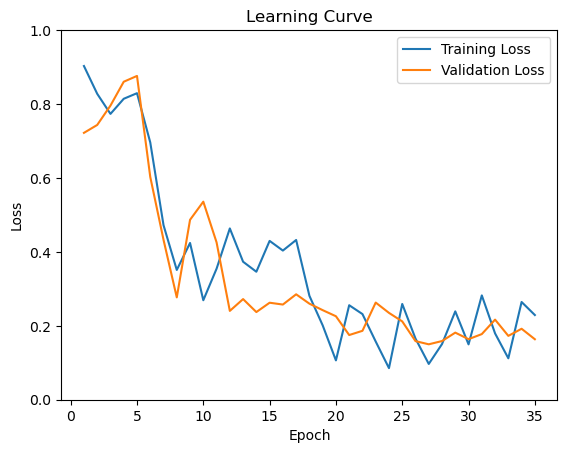

Fold 3
Accuracy Train: 0.8269841319748332. Accuracy valid: 0.8603174686431885
Recall Train: 0.6646826267242432. Recall valid: 0.6238095164299011
Precision Train: 0.7297619581222534. Precision valid: 0.6380952000617981
Best Valid Accuracy Epoc: 5. Value = 0.8888888955116272 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 5. Value = 0.6666666865348816 Acc val = 0.8888888955116272


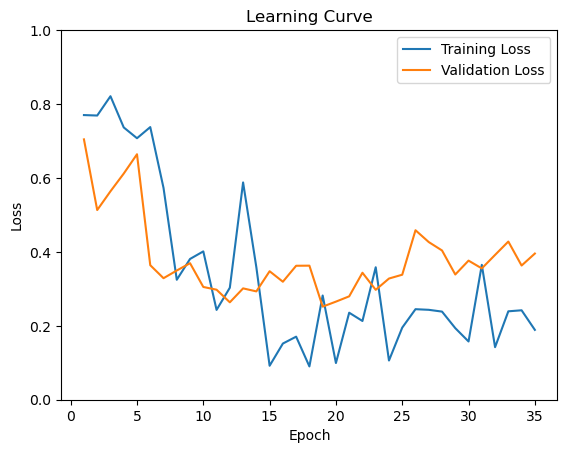

Fold 4
Accuracy Train: 0.8031746080233937. Accuracy valid: 0.6984127129827227
Recall Train: 0.8011904358863831. Recall valid: 0.9142857193946838
Precision Train: 0.7591269612312317. Precision valid: 0.6444444060325623
Best Valid Accuracy Epoc: 18. Value = 0.8888888955116272 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444576899211


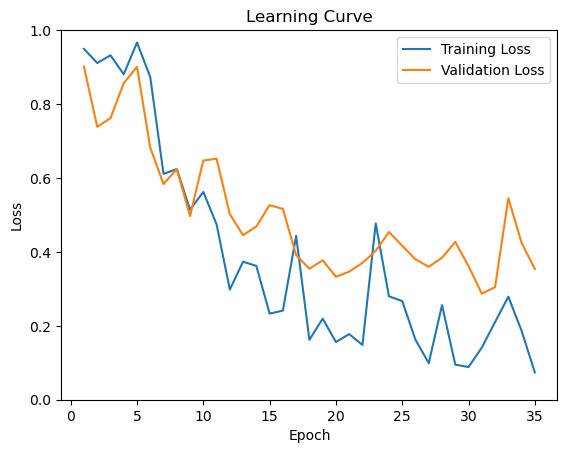

Fold 5
Accuracy Train: 0.834920640573615. Accuracy valid: 0.8730158800170535
Recall Train: 0.7257936000823975. Recall valid: 0.6952380537986755
Precision Train: 0.7821428775787354. Precision valid: 0.6682538986206055
Best Valid Accuracy Epoc: 5. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.6111111243565878


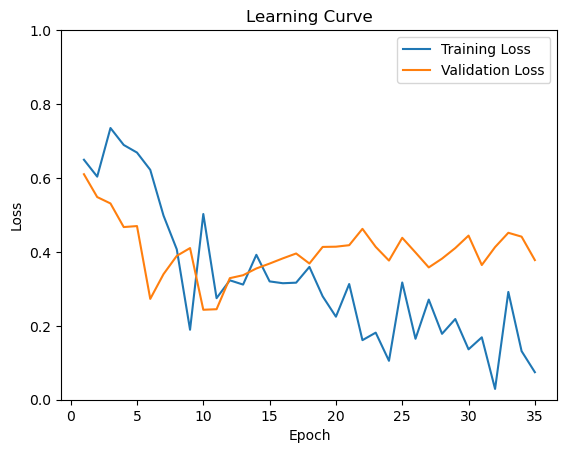

5
Fold 0: Training Loss: 0.38573035980973924, Validation Loss: 0.47071759055058165
Fold 1: Training Loss: 0.3603044867515564, Validation Loss: 0.33851918936485337
Fold 2: Training Loss: 0.34180421637637276, Validation Loss: 0.3818238306258406
Fold 3: Training Loss: 0.3921780111534255, Validation Loss: 0.5021571433260327
Fold 4: Training Loss: 0.3264137674123049, Validation Loss: 0.40112381056838087
TRAIN LOSS MEDIA: 0.3612861683006797 VALID LOSS MEDIA: 0.4188683128871379
TRAIN ACC MEDIA: 0.8169047669711567 VALID ACC MEDIA: 0.8057142951374962
TRAIN RECALL MEDIA: 0.7616666555404663 VALID RECALL MEDIA: 0.7771428823471069
TRAIN PRECISION MEDIA: 0.7635714411735535 VALID PRECISION MEDIA: 0.7060316801071167


In [21]:
prueba_k_fold_resnet_pre(df_mean, 5,5,30, optim.RMSprop , 3, 0.00001, True, 'H')

## ADAMW NO AUG

### PRUEBAS LR

Fold 1
Accuracy Train: 0.8710204126275316. Accuracy valid: 0.6700000077486038
Recall Train: 0.8282312750816345. Recall valid: 0.44285714626312256
Precision Train: 0.8474149703979492. Precision valid: 0.5828571455819266
Best Valid Accuracy Epoc: 22. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 12. Value = 1.0 Acc val = 0.7750000059604645


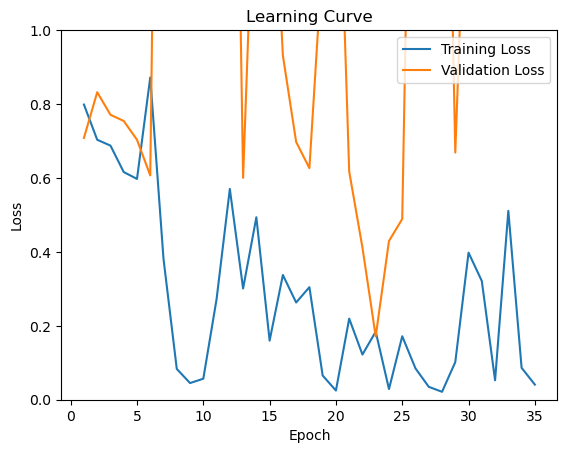

Fold 2
Accuracy Train: 0.8653061282269809. Accuracy valid: 0.6928571500948497
Recall Train: 0.8338775038719177. Recall valid: 0.7190476059913635
Precision Train: 0.8346939086914062. Precision valid: 0.6847619090761458
Best Valid Accuracy Epoc: 7. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 7. Value = 1.0 Acc val = 1.0


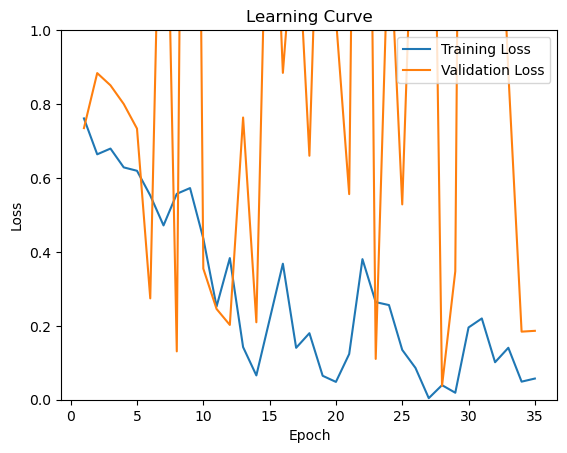

Fold 3
Accuracy Train: 0.867755107551205. Accuracy valid: 0.7550000028950827
Recall Train: 0.828299343585968. Recall valid: 0.73333340883255
Precision Train: 0.8662585616111755. Precision valid: 0.7535714311259133
Best Valid Accuracy Epoc: 10. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.675000011920929


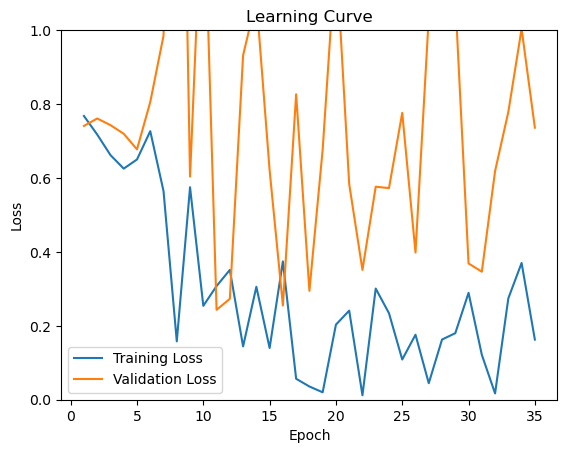

Fold 4
Accuracy Train: 0.8653061276187702. Accuracy valid: 0.750000005534717
Recall Train: 0.8258504271507263. Recall valid: 0.7666666507720947
Precision Train: 0.8479592204093933. Precision valid: 0.6204761947904315
Best Valid Accuracy Epoc: 11. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 4. Value = 1.0 Acc val = 0.550000011920929


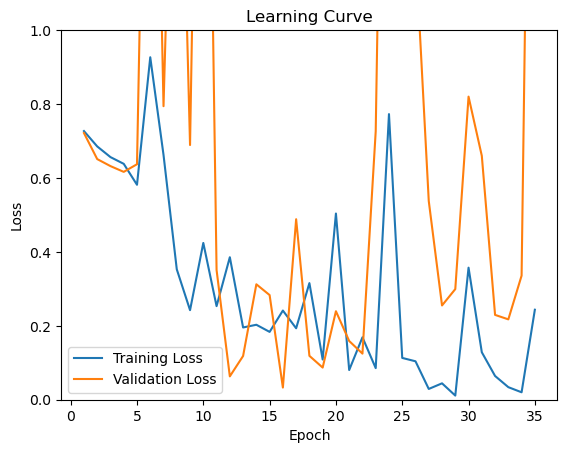

Fold 5
Accuracy Train: 0.8142857185431889. Accuracy valid: 0.6638095378875732
Recall Train: 0.7417262196540833. Recall valid: 0.6857143044471741
Precision Train: 0.7239285715988704. Precision valid: 0.6085714442389352
Best Valid Accuracy Epoc: 33. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.533333346247673


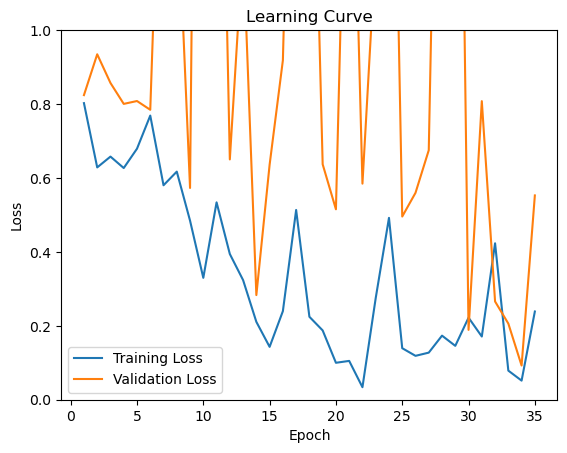

5
Fold 0: Training Loss: 0.28606575839221476, Validation Loss: 1.7830981285976513
Fold 1: Training Loss: 0.2821680349963052, Validation Loss: 1.255483205809391
Fold 2: Training Loss: 0.29525168240070343, Validation Loss: 0.831973644415848
Fold 3: Training Loss: 0.3067668816606913, Validation Loss: 0.8023127972281405
Fold 4: Training Loss: 0.33833718991705347, Validation Loss: 1.1412827337426799
TRAIN LOSS MEDIA: 0.3017179094733936 VALID LOSS MEDIA: 1.1628301019587421
TRAIN ACC MEDIA: 0.8567346989135352 VALID ACC MEDIA: 0.7063333408321653
TRAIN RECALL MEDIA: 0.8115969896316528 VALID RECALL MEDIA: 0.6695238351821899
TRAIN PRECISION MEDIA: 0.824051046541759 VALID PRECISION MEDIA: 0.6500476249626704


In [36]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.AdamW , 5, 0.001, False, None)

Fold 1
Accuracy Train: 0.8873469420233551. Accuracy valid: 0.7271428625498499
Recall Train: 0.8880272507667542. Recall valid: 0.5571428537368774
Precision Train: 0.8804081678390503. Precision valid: 0.8507143259048462
Best Valid Accuracy Epoc: 5. Value = 0.9000000059604645 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.45000000298023224


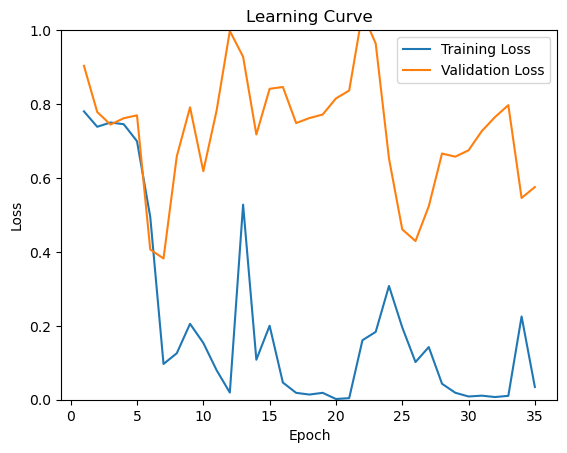

Fold 2
Accuracy Train: 0.8865306153589365. Accuracy valid: 0.86142857670784
Recall Train: 0.7862585783004761. Recall valid: 0.7523809671401978
Precision Train: 0.7925170063972473. Precision valid: 0.8464285739830562
Best Valid Accuracy Epoc: 10. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 10. Value = 1.0 Acc val = 1.0


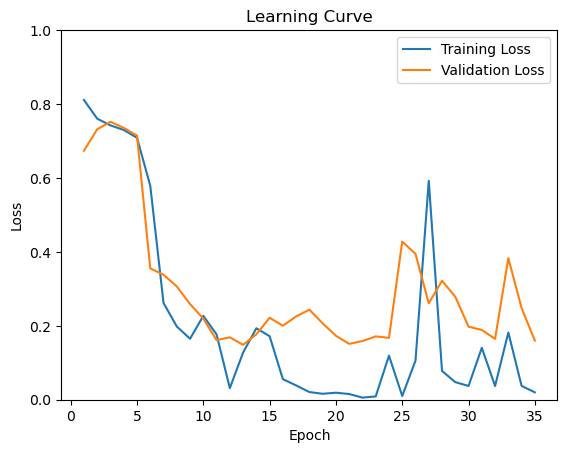

Fold 3
Accuracy Train: 0.8873469431789555. Accuracy valid: 0.8157142869063786
Recall Train: 0.8331973552703857. Recall valid: 0.7095238566398621
Precision Train: 0.8551021218299866. Precision valid: 0.8571428571428571
Best Valid Accuracy Epoc: 5. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 5. Value = 0.8333333730697632 Acc val = 0.875


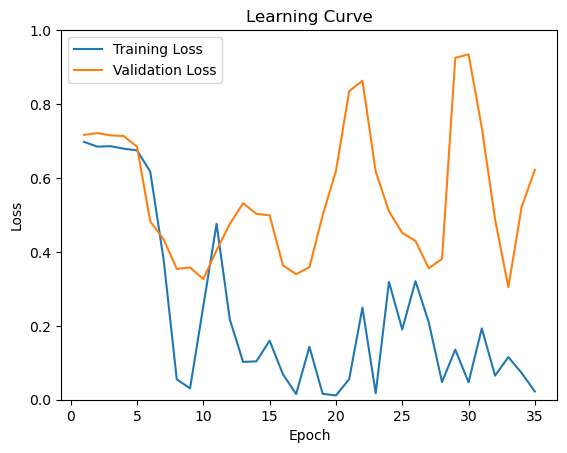

Fold 4
Accuracy Train: 0.9102040855252013. Accuracy valid: 0.7857142901846341
Recall Train: 0.8444897532463074. Recall valid: 0.8428571224212646
Precision Train: 0.8945578336715698. Precision valid: 0.641904764516013
Best Valid Accuracy Epoc: 10. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.9000000059604645


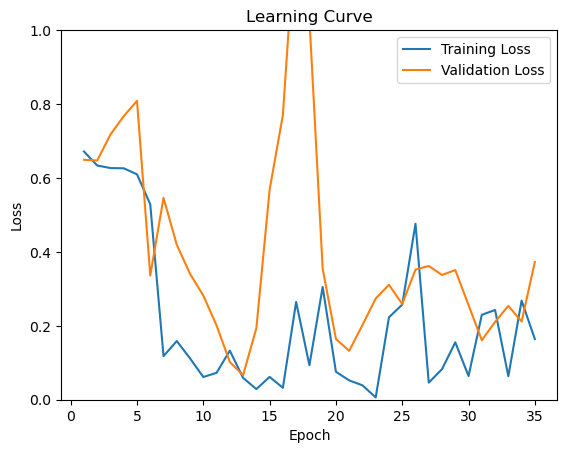

Fold 5
Accuracy Train: 0.8707142882049084. Accuracy valid: 0.7914285821574075
Recall Train: 0.8454167246818542. Recall valid: 0.7428571581840515
Precision Train: 0.789226233959198. Precision valid: 0.9190476536750793
Best Valid Accuracy Epoc: 18. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 18. Value = 1.0 Acc val = 1.0


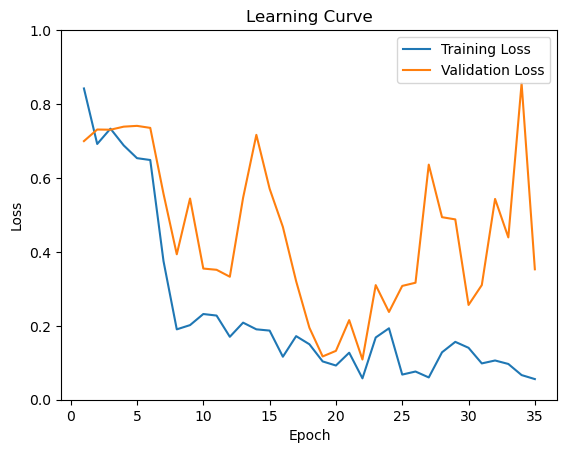

5
Fold 0: Training Loss: 0.2080261959627803, Validation Loss: 0.7241633255566869
Fold 1: Training Loss: 0.2134514664033694, Validation Loss: 0.30534669842704065
Fold 2: Training Loss: 0.23239889929869345, Validation Loss: 0.5449222541613771
Fold 3: Training Loss: 0.2183882033718484, Validation Loss: 0.40900556285466466
Fold 4: Training Loss: 0.24215510934591294, Validation Loss: 0.452829067834786
TRAIN LOSS MEDIA: 0.22288397487652092 VALID LOSS MEDIA: 0.4872533817669111
TRAIN ACC MEDIA: 0.8884285748582712 VALID ACC MEDIA: 0.7962857197012221
TRAIN RECALL MEDIA: 0.8394778966903687 VALID RECALL MEDIA: 0.7209523916244507
TRAIN PRECISION MEDIA: 0.8423622727394104 VALID PRECISION MEDIA: 0.8230476350443704


In [37]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.AdamW , 5, 0.0001, False, None)

Fold 1
Accuracy Train: 0.9110204112164829. Accuracy valid: 0.7357142925262451
Recall Train: 0.9302040934562683. Recall valid: 0.5142857432365417
Precision Train: 0.8925169706344604. Precision valid: 0.8580952286720276
Best Valid Accuracy Epoc: 2. Value = 0.7750000059604645 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.45000000298023224


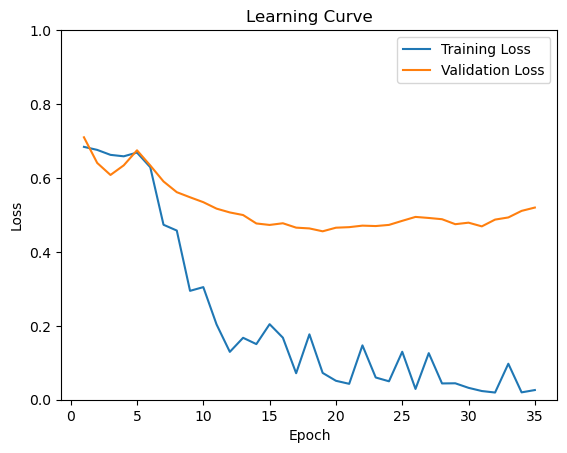

Fold 2
Accuracy Train: 0.8938775541222825. Accuracy valid: 0.8235714314239365
Recall Train: 0.78632652759552. Recall valid: 0.7380952835083008
Precision Train: 0.8265306353569031. Precision valid: 0.7285714285714285
Best Valid Accuracy Epoc: 20. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 12. Value = 1.0 Acc val = 0.875


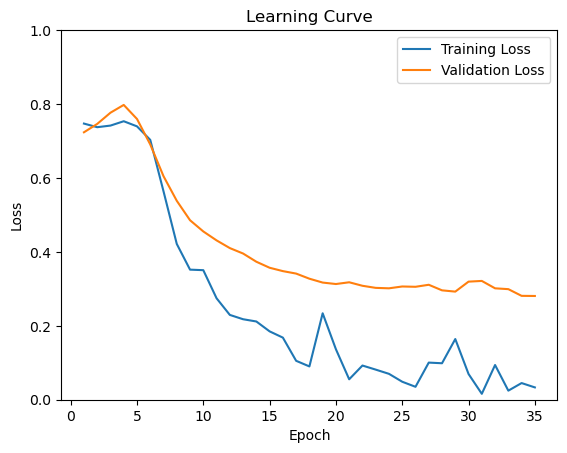

Fold 3
Accuracy Train: 0.8987755134397623. Accuracy valid: 0.7742857149669102
Recall Train: 0.8623129725456238. Recall valid: 0.6952381730079651
Precision Train: 0.8884353637695312. Precision valid: 0.825
Best Valid Accuracy Epoc: 7. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 7. Value = 0.8333333730697632 Acc val = 0.875


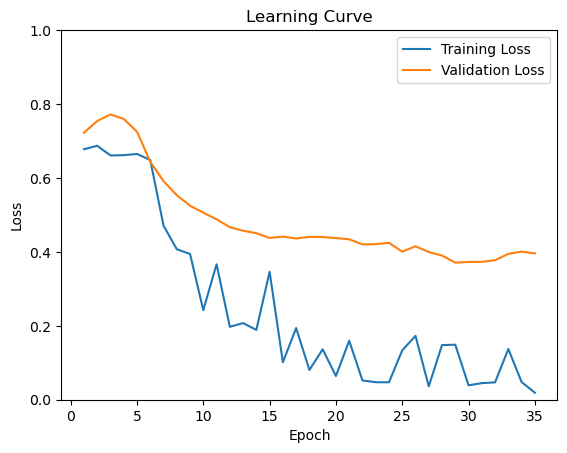

Fold 4
Accuracy Train: 0.8538775536478782. Accuracy valid: 0.6600000062159129
Recall Train: 0.9606803059577942. Recall valid: 0.800000011920929
Precision Train: 0.8491156697273254. Precision valid: 0.5130952596664429
Best Valid Accuracy Epoc: 26. Value = 0.875 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


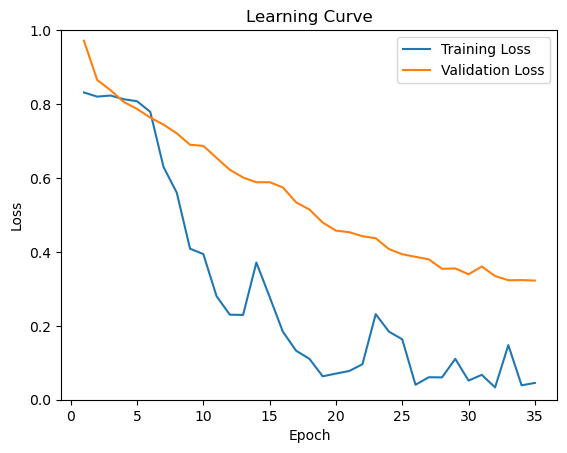

Fold 5
Accuracy Train: 0.8100000023309674. Accuracy valid: 0.7580952491079058
Recall Train: 0.8827975988388062. Recall valid: 0.7928571701049805
Precision Train: 0.7986904978752136. Precision valid: 0.8519048094749451
Best Valid Accuracy Epoc: 18. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 4. Value = 1.0 Acc val = 0.6333333551883698


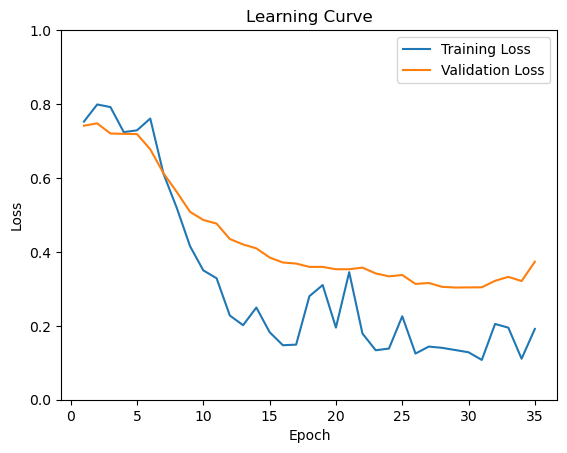

5
Fold 0: Training Loss: 0.2227748892669167, Validation Loss: 0.5203018435410091
Fold 1: Training Loss: 0.25687661889408314, Validation Loss: 0.4210469220365797
Fold 2: Training Loss: 0.24796850574868065, Validation Loss: 0.4868606444980417
Fold 3: Training Loss: 0.29217327567083495, Validation Loss: 0.5456980896847589
Fold 4: Training Loss: 0.3208275814141546, Validation Loss: 0.43857126235961913
TRAIN LOSS MEDIA: 0.26812417419893403 VALID LOSS MEDIA: 0.4824957524240016
TRAIN ACC MEDIA: 0.8735102069514745 VALID ACC MEDIA: 0.7503333388481821
TRAIN RECALL MEDIA: 0.8844642639160156 VALID RECALL MEDIA: 0.7080952525138855
TRAIN PRECISION MEDIA: 0.8510578274726868 VALID PRECISION MEDIA: 0.7553333452769688


In [38]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.AdamW , 5, 0.00001, False, None)

### PRUEBAS BS

Fold 1
Accuracy Train: 0.8253968283534049. Accuracy valid: 0.7238095382849377
Recall Train: 0.5869048237800598. Recall valid: 0.37142857909202576
Precision Train: 0.6142857138599668. Precision valid: 0.5047619198049818
Best Valid Accuracy Epoc: 9. Value = 0.7777777910232544 Recall val = 0.5
Best Valid Recall Epoc: 9. Value = 0.5 Acc val = 0.7777777910232544


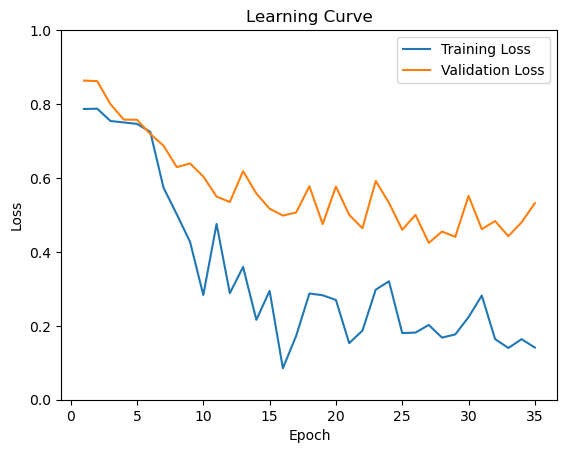

Fold 2
Accuracy Train: 0.7611111150611014. Accuracy valid: 0.7365079471043178
Recall Train: 0.8111111521720886. Recall valid: 0.7428571581840515
Precision Train: 0.7384920716285706. Precision valid: 0.5746031403541565
Best Valid Accuracy Epoc: 12. Value = 0.8888888955116272 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444576899211


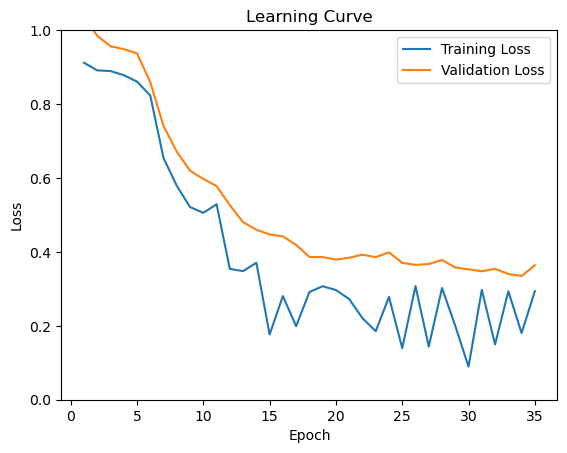

Fold 3
Accuracy Train: 0.8353174640309243. Accuracy valid: 0.7777777870496114
Recall Train: 0.6567460894584656. Recall valid: 0.4761905074119568
Precision Train: 0.7107143402099609. Precision valid: 0.48571430018969947
Best Valid Accuracy Epoc: 14. Value = 0.8888888955116272 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 14. Value = 0.6666666865348816 Acc val = 0.8888888955116272


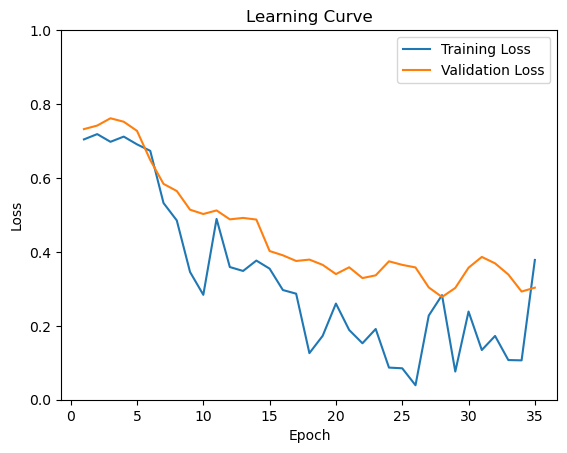

Fold 4
Accuracy Train: 0.7801587341087205. Accuracy valid: 0.6063492170401981
Recall Train: 0.8297618627548218. Recall valid: 1.0
Precision Train: 0.7571428418159485. Precision valid: 0.6047620177268982
Best Valid Accuracy Epoc: 33. Value = 0.777777781089147 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444576899211


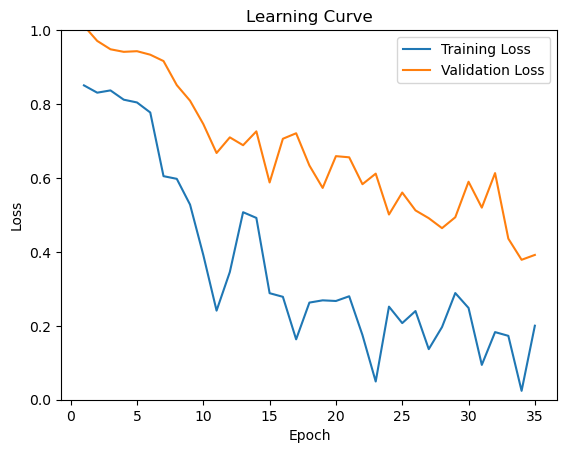

Fold 5
Accuracy Train: 0.8492063537949609. Accuracy valid: 0.8142857228006636
Recall Train: 0.7281745672225952. Recall valid: 0.5809524059295654
Precision Train: 0.7821428775787354. Precision valid: 0.6269841194152832
Best Valid Accuracy Epoc: 11. Value = 0.8888888955116272 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 0. Value = 0.8333333134651184 Acc val = 0.5000000099341074


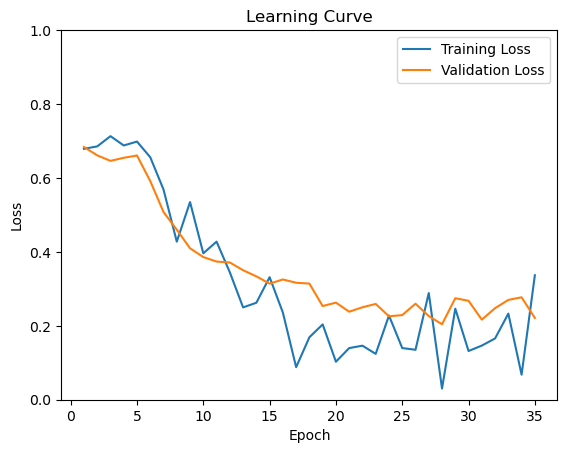

5
Fold 0: Training Loss: 0.34424123125416894, Validation Loss: 0.5728797359125954
Fold 1: Training Loss: 0.40055047337497984, Validation Loss: 0.5242587041287194
Fold 2: Training Loss: 0.3252120241522789, Validation Loss: 0.45180741591112955
Fold 3: Training Loss: 0.3684595143156392, Validation Loss: 0.6727393201419285
Fold 4: Training Loss: 0.31492117771080563, Validation Loss: 0.35840509099264944
TRAIN LOSS MEDIA: 0.3506768841615745 VALID LOSS MEDIA: 0.5160180534174044
TRAIN ACC MEDIA: 0.8102380990698224 VALID ACC MEDIA: 0.7317460424559457
TRAIN RECALL MEDIA: 0.7225397229194641 VALID RECALL MEDIA: 0.6342857480049133
TRAIN PRECISION MEDIA: 0.7205555690186365 VALID PRECISION MEDIA: 0.5593650994982038


In [39]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.AdamW , 3, 0.00001, False, None)

Fold 1
Accuracy Train: 0.8659523817471095. Accuracy valid: 0.37142857142857144
Recall Train: 0.8628571033477783. Recall valid: 0.37142857909202576
Precision Train: 0.8455918431282043. Precision valid: 0.3106462359428406
Best Valid Accuracy Epoc: 0. Value = 0.75 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.75


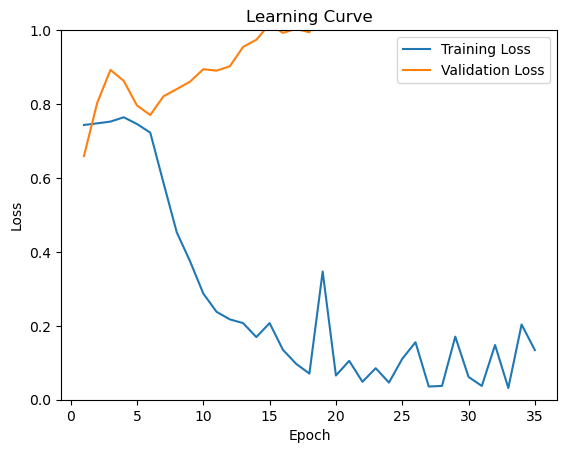

Fold 2
Accuracy Train: 0.8642857153075082. Accuracy valid: 0.9
Recall Train: 0.8885713815689087. Recall valid: 0.9666666388511658
Precision Train: 0.8413469195365906. Precision valid: 0.8851020336151123
Best Valid Accuracy Epoc: 19. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.6875


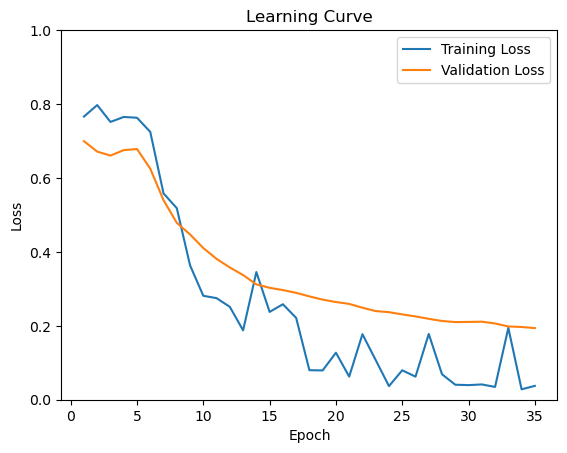

Fold 3
Accuracy Train: 0.8811904769284384. Accuracy valid: 0.8535714285714285
Recall Train: 0.9332380890846252. Recall valid: 0.8238096237182617
Precision Train: 0.8608911037445068. Precision valid: 0.8948469161987305
Best Valid Accuracy Epoc: 9. Value = 0.9375 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.6875


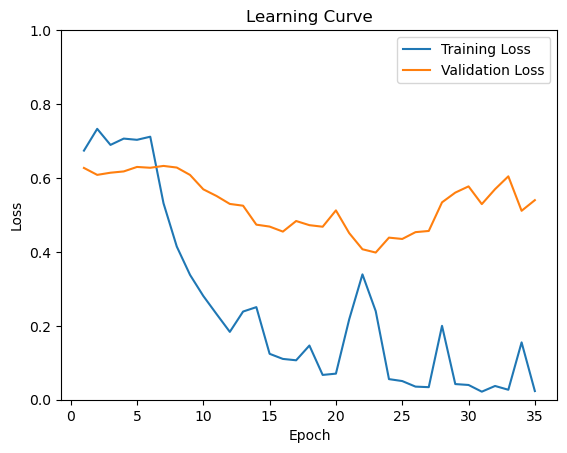

Fold 4
Accuracy Train: 0.8309523815768105. Accuracy valid: 0.6089285714285714
Recall Train: 0.9466665983200073. Recall valid: 0.4392857253551483
Precision Train: 0.823455810546875. Precision valid: 0.2741836905479431
Best Valid Accuracy Epoc: 30. Value = 0.875 Recall val = 0.375
Best Valid Recall Epoc: 0. Value = 0.5 Acc val = 0.25


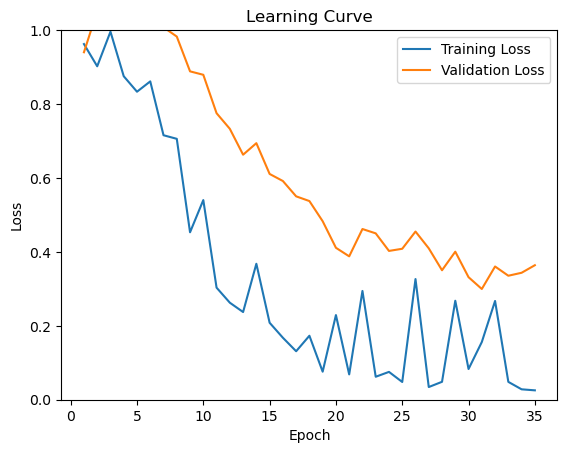

Fold 5
Accuracy Train: 0.8671428571428572. Accuracy valid: 0.7714285714285715
Recall Train: 0.9631428122520447. Recall valid: 0.6714285612106323
Precision Train: 0.8505101799964905. Precision valid: 0.8985714316368103
Best Valid Accuracy Epoc: 8. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 0.75 Acc val = 0.625


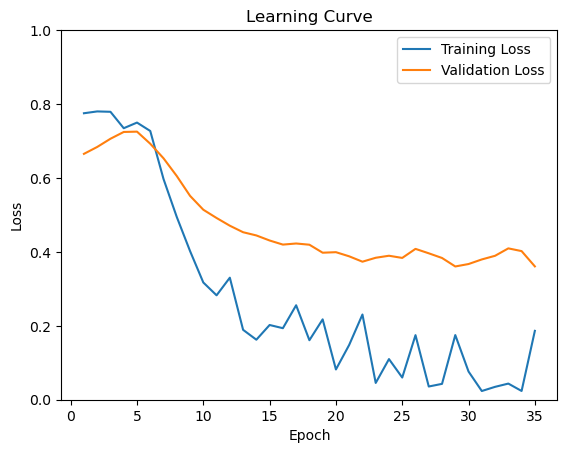

5
Fold 0: Training Loss: 0.26697771613086974, Validation Loss: 1.036920960034643
Fold 1: Training Loss: 0.2725876128567117, Validation Loss: 0.3507911652326584
Fold 2: Training Loss: 0.2522993446460792, Validation Loss: 0.5305087221520287
Fold 3: Training Loss: 0.33812179123716696, Validation Loss: 0.626960477232933
Fold 4: Training Loss: 0.281236575118133, Validation Loss: 0.47562860591070993
TRAIN LOSS MEDIA: 0.28224460799779216 VALID LOSS MEDIA: 0.6041619861125946
TRAIN ACC MEDIA: 0.8619047625405447 VALID ACC MEDIA: 0.7010714285714286
TRAIN RECALL MEDIA: 0.9188952445983887 VALID RECALL MEDIA: 0.6545238494873047
TRAIN PRECISION MEDIA: 0.8443592190742493 VALID PRECISION MEDIA: 0.6526700854301453


In [40]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.AdamW , 8, 0.00001, False, None)

Fold 1
Accuracy Train: 0.8849206362451826. Accuracy valid: 0.7047619223594666
Recall Train: 0.740107536315918. Recall valid: 0.33571428060531616
Precision Train: 0.800000011920929. Precision valid: 0.6857142857142857
Best Valid Accuracy Epoc: 12. Value = 0.7777777910232544 Recall val = 0.5
Best Valid Recall Epoc: 12. Value = 0.5 Acc val = 0.7777777910232544


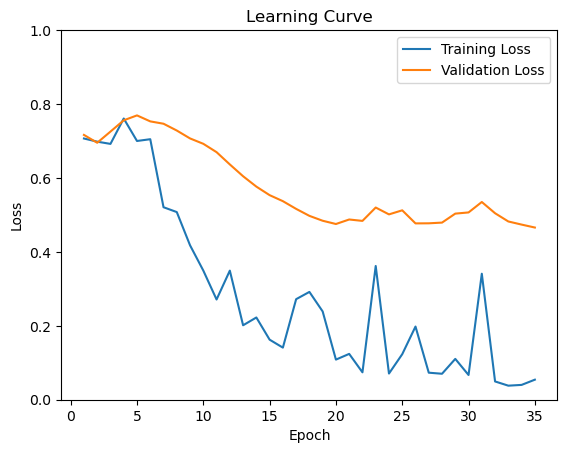

Fold 2
Accuracy Train: 0.8378968270052047. Accuracy valid: 0.6349206481661115
Recall Train: 0.9406084418296814. Recall valid: 0.9214285612106323
Precision Train: 0.8341760635375977. Precision valid: 0.5847052335739136
Best Valid Accuracy Epoc: 33. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444477558136


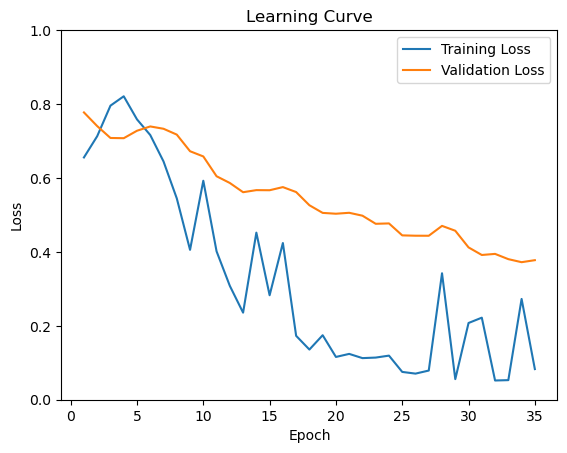

Fold 3
Accuracy Train: 0.9126984142121816. Accuracy valid: 0.7111111223697663
Recall Train: 0.8017308712005615. Recall valid: 0.6357142925262451
Precision Train: 0.9063491821289062. Precision valid: 0.8588888645172119
Best Valid Accuracy Epoc: 26. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444477558136


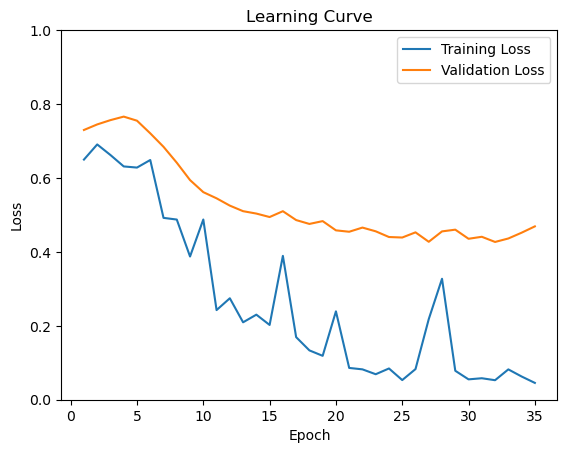

Fold 4
Accuracy Train: 0.8896825418585823. Accuracy valid: 0.67936509677342
Recall Train: 0.7988662123680115. Recall valid: 0.7142857313156128
Precision Train: 0.8498186469078064. Precision valid: 0.5510884514876775
Best Valid Accuracy Epoc: 7. Value = 0.7777777910232544 Recall val = 0.75
Best Valid Recall Epoc: 8. Value = 1.0 Acc val = 0.7777777910232544


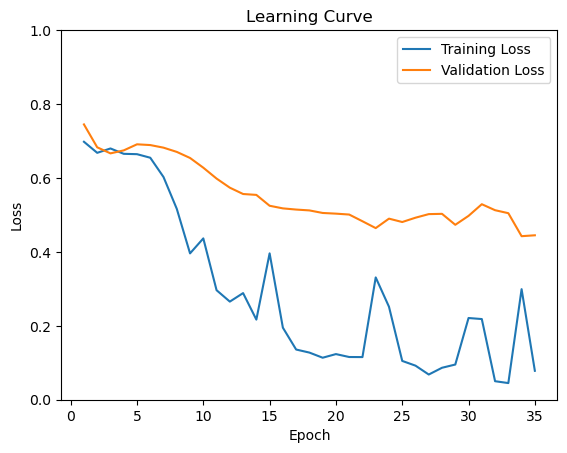

Fold 5
Accuracy Train: 0.7910714285714285. Accuracy valid: 0.6571428571428571
Recall Train: 0.9523810148239136. Recall valid: 0.949999988079071
Precision Train: 0.7822895646095276. Precision valid: 0.6370748281478882
Best Valid Accuracy Epoc: 22. Value = 0.875 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.5


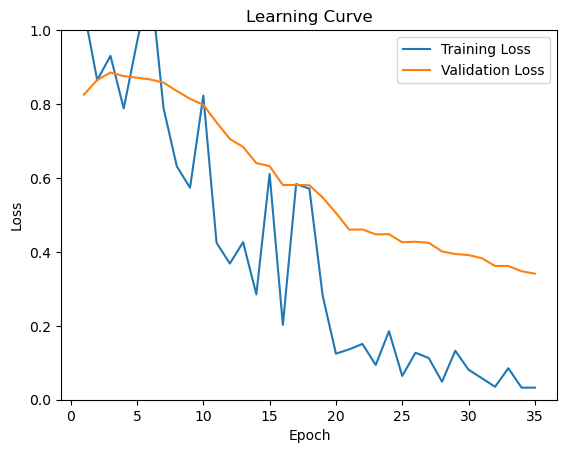

5
Fold 0: Training Loss: 0.28894405290484426, Validation Loss: 0.5786437630653382
Fold 1: Training Loss: 0.3237972030682223, Validation Loss: 0.5509852349758149
Fold 2: Training Loss: 0.2689071145440851, Validation Loss: 0.5330450517790658
Fold 3: Training Loss: 0.2946327492594719, Validation Loss: 0.5561483442783356
Fold 4: Training Loss: 0.3947432952267783, Validation Loss: 0.5936547756195069
TRAIN LOSS MEDIA: 0.3142048830006804 VALID LOSS MEDIA: 0.5624954339436122
TRAIN ACC MEDIA: 0.8632539695785161 VALID ACC MEDIA: 0.6774603293623243
TRAIN RECALL MEDIA: 0.8467388153076172 VALID RECALL MEDIA: 0.7114285826683044
TRAIN PRECISION MEDIA: 0.8345267176628113 VALID PRECISION MEDIA: 0.6634943326881955


In [41]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.AdamW , 16, 0.00001, False, None)

### PRUEBAS EPOCS

Fold 1
Accuracy Train: 0.8428571453690529. Accuracy valid: 0.6350000062584877
Recall Train: 0.8603333234786987. Recall valid: 0.5249999761581421
Precision Train: 0.8308095335960388. Precision valid: 0.737333357334137
Best Valid Accuracy Epoc: 21. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 1. Value = 0.75 Acc val = 0.32500000298023224


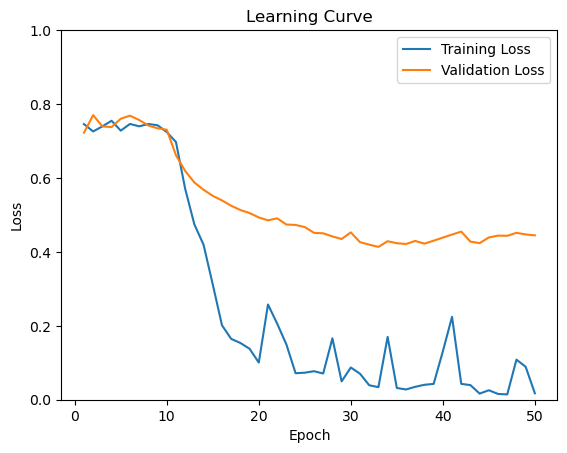

Fold 2
Accuracy Train: 0.8851428606680461. Accuracy valid: 0.8715000033378602
Recall Train: 0.7439048290252686. Recall valid: 0.7166666984558105
Precision Train: 0.7628571444749832. Precision valid: 0.785
Best Valid Accuracy Epoc: 19. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 19. Value = 1.0 Acc val = 1.0


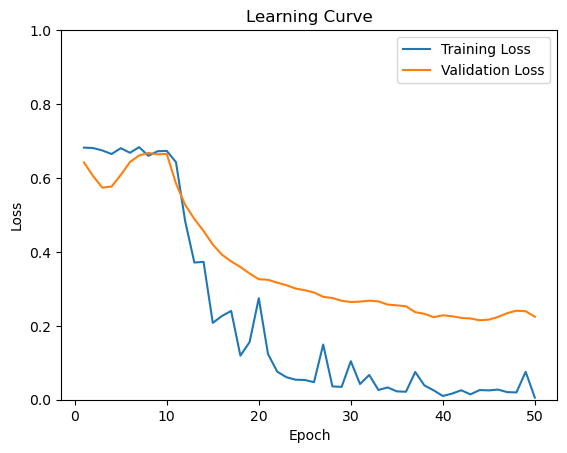

Fold 3
Accuracy Train: 0.8891428612811225. Accuracy valid: 0.7715000015497208
Recall Train: 0.7417619228363037. Recall valid: 0.6466667056083679
Precision Train: 0.7914286255836487. Precision valid: 0.7683333334326744
Best Valid Accuracy Epoc: 17. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 17. Value = 0.8333333730697632 Acc val = 0.875


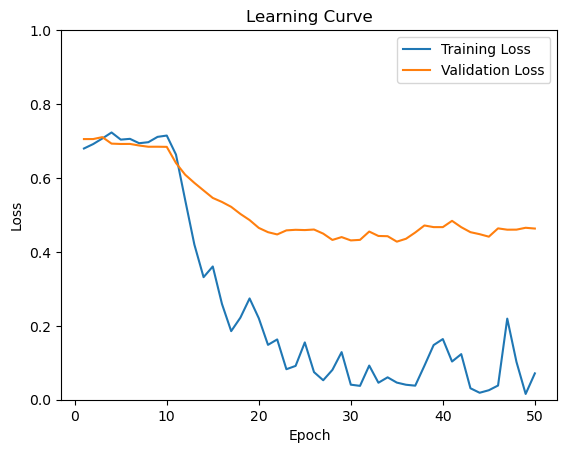

Fold 4
Accuracy Train: 0.8542857176491193. Accuracy valid: 0.7220000042021275
Recall Train: 0.8155714273452759. Recall valid: 0.7666667103767395
Precision Train: 0.8366667032241821. Precision valid: 0.5366666913032532
Best Valid Accuracy Epoc: 16. Value = 0.875 Recall val = 0.5
Best Valid Recall Epoc: 18. Value = 1.0 Acc val = 0.7750000059604645


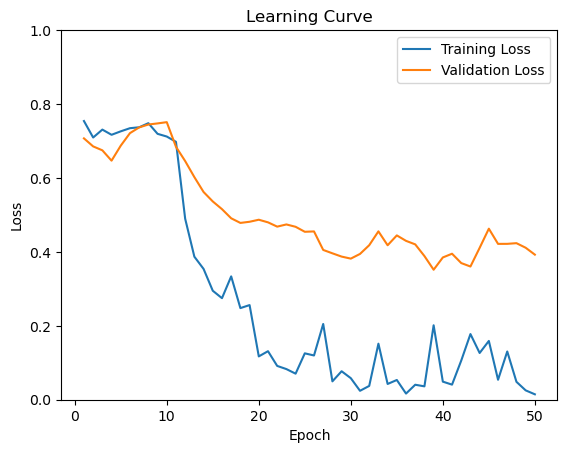

Fold 5
Accuracy Train: 0.8390000031515956. Accuracy valid: 0.7666666740179062
Recall Train: 0.6945416927337646. Recall valid: 0.6499999761581421
Precision Train: 0.71833336353302. Precision valid: 0.6396666765213013
Best Valid Accuracy Epoc: 21. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.533333346247673


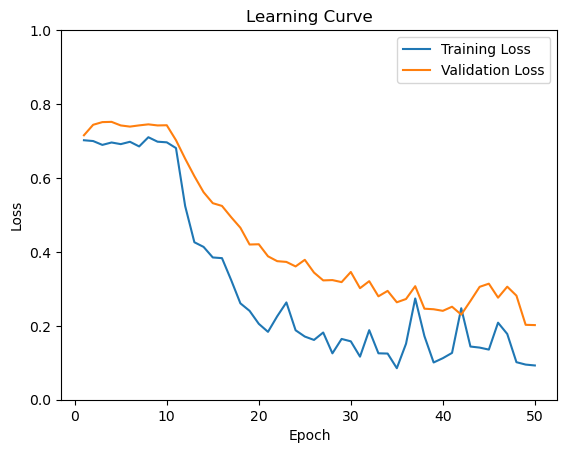

5
Fold 0: Training Loss: 0.2609575997665525, Validation Loss: 0.5264543330669403
Fold 1: Training Loss: 0.22387182397767902, Validation Loss: 0.3649749721586704
Fold 2: Training Loss: 0.26074470072984696, Validation Loss: 0.5197517462074757
Fold 3: Training Loss: 0.2657712170295417, Validation Loss: 0.5026552297174931
Fold 4: Training Loss: 0.31107433408498764, Validation Loss: 0.43458560079336167
TRAIN LOSS MEDIA: 0.26448393511772156 VALID LOSS MEDIA: 0.46968437638878824
TRAIN ACC MEDIA: 0.8620857176237873 VALID ACC MEDIA: 0.7533333378732204
TRAIN RECALL MEDIA: 0.7712226510047913 VALID RECALL MEDIA: 0.6609999537467957
TRAIN PRECISION MEDIA: 0.7880190740823746 VALID PRECISION MEDIA: 0.6934000117182733


In [22]:
prueba_k_fold_resnet_pre(df_mean, 5, 10,40, optim.AdamW , 5, 0.00001, False, None)

Fold 1
Accuracy Train: 0.9379591860333267. Accuracy valid: 0.7200000058327403
Recall Train: 0.8897958993911743. Recall valid: 0.5142857432365417
Precision Train: 0.9115646481513977. Precision valid: 0.9102380871772766
Best Valid Accuracy Epoc: 4. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 0. Value = 0.75 Acc val = 0.45000000298023224


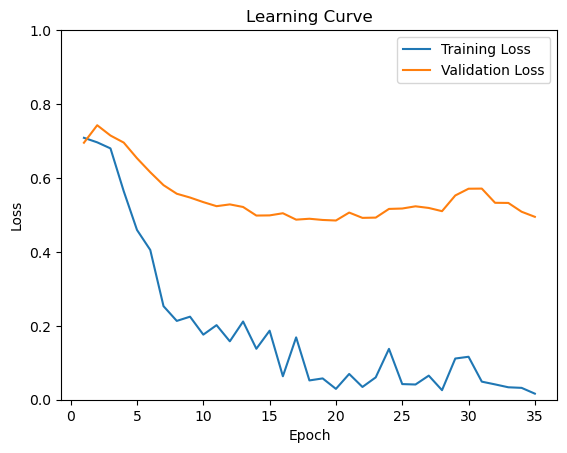

Fold 2
Accuracy Train: 0.928979593454575. Accuracy valid: 0.7835714346596173
Recall Train: 0.844149649143219. Recall valid: 0.7952380776405334
Precision Train: 0.8857142925262451. Precision valid: 0.6988095262220928
Best Valid Accuracy Epoc: 12. Value = 0.9000000059604645 Recall val = 1.0
Best Valid Recall Epoc: 12. Value = 1.0 Acc val = 0.9000000059604645


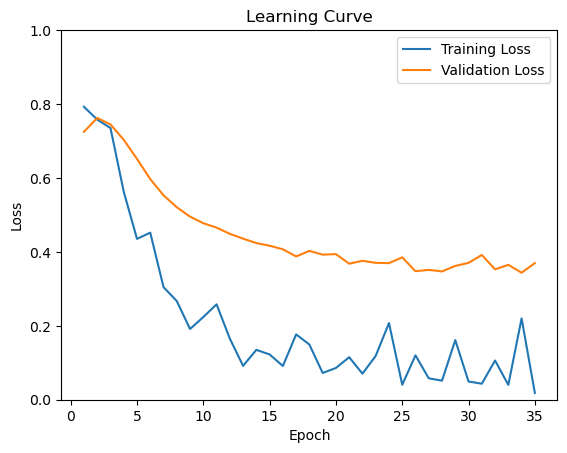

Fold 3
Accuracy Train: 0.8840816353048597. Accuracy valid: 0.7828571443046842
Recall Train: 0.9730612635612488. Recall valid: 0.8809524774551392
Precision Train: 0.8739455938339233. Precision valid: 0.8504762053489685
Best Valid Accuracy Epoc: 11. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4750000014901161


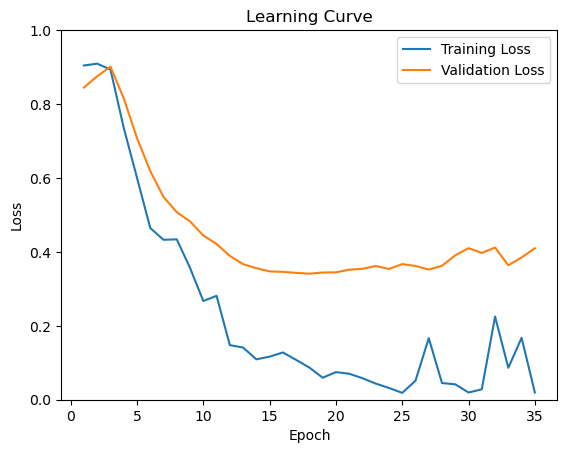

Fold 4
Accuracy Train: 0.913469389750033. Accuracy valid: 0.657142863529069
Recall Train: 0.9493197798728943. Recall valid: 0.6952381134033203
Precision Train: 0.9023810029029846. Precision valid: 0.4526190757751465
Best Valid Accuracy Epoc: 7. Value = 0.7750000059604645 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


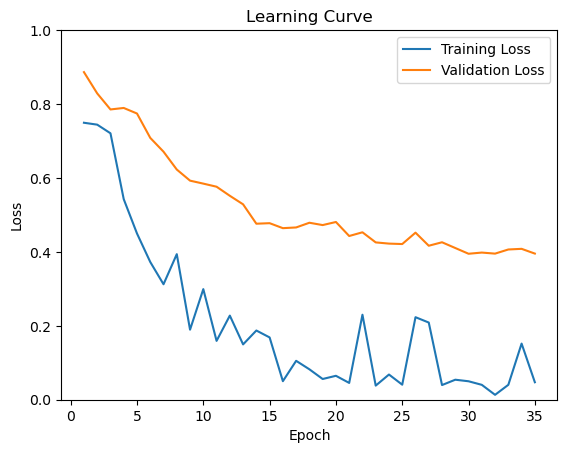

Fold 5
Accuracy Train: 0.887142858813916. Accuracy valid: 0.9066666709525245
Recall Train: 0.7423213720321655. Recall valid: 0.800000011920929
Precision Train: 0.7642857432365417. Precision valid: 0.8142857142857143
Best Valid Accuracy Epoc: 11. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 11. Value = 1.0 Acc val = 1.0


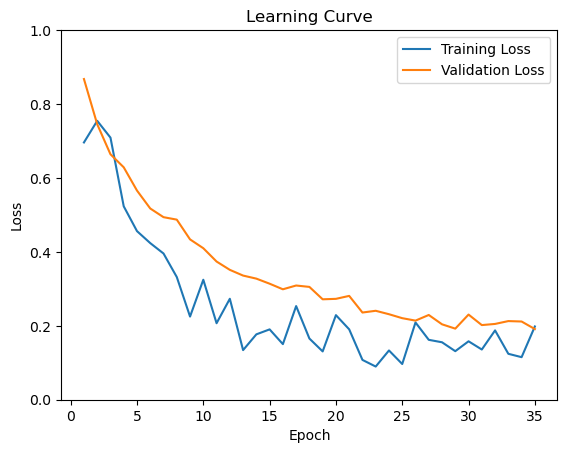

5
Fold 0: Training Loss: 0.18643550063882555, Validation Loss: 0.5485904629741396
Fold 1: Training Loss: 0.21401688680052758, Validation Loss: 0.4535775721073151
Fold 2: Training Loss: 0.23783980618630138, Validation Loss: 0.45651386683540685
Fold 3: Training Loss: 0.20904315265693835, Validation Loss: 0.5281675504786628
Fold 4: Training Loss: 0.25557479155915125, Validation Loss: 0.3507581638438361
TRAIN LOSS MEDIA: 0.22058202756834883 VALID LOSS MEDIA: 0.4675215232478721
TRAIN ACC MEDIA: 0.9103265326713421 VALID ACC MEDIA: 0.7700476238557271
TRAIN RECALL MEDIA: 0.8797296285629272 VALID RECALL MEDIA: 0.7371429204940796
TRAIN PRECISION MEDIA: 0.8675782084465027 VALID PRECISION MEDIA: 0.7452857217618398


In [23]:
prueba_k_fold_resnet_pre(df_mean, 5, 2,33, optim.AdamW , 5, 0.00001, False, None)

Fold 1
Accuracy Train: 0.9074285738808768. Accuracy valid: 0.7385000056028366
Recall Train: 0.8763334155082703. Recall valid: 0.5600000023841858
Precision Train: 0.8876190185546875. Precision valid: 0.9100000262260437
Best Valid Accuracy Epoc: 9. Value = 0.9000000059604645 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.45000000298023224


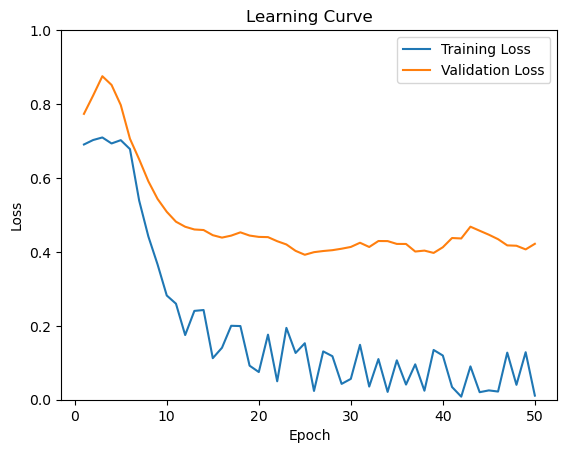

Fold 2
Accuracy Train: 0.922857145028455. Accuracy valid: 0.7835000059008599
Recall Train: 0.8100951910018921. Recall valid: 0.7166666984558105
Precision Train: 0.8285714310407638. Precision valid: 0.7200000023841858
Best Valid Accuracy Epoc: 7. Value = 0.9000000059604645 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 7. Value = 0.8333333730697632 Acc val = 0.9000000059604645


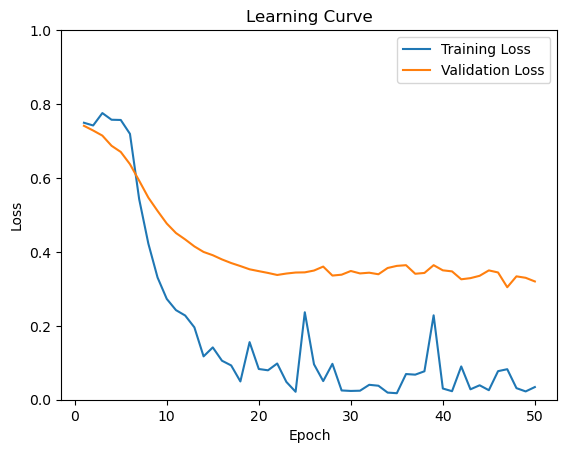

Fold 3
Accuracy Train: 0.9120000020521027. Accuracy valid: 0.8050000008940696
Recall Train: 0.8139523863792419. Recall valid: 0.7200000286102295
Precision Train: 0.8457143306732178. Precision valid: 0.8558333337306976
Best Valid Accuracy Epoc: 11. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 0.8333333730697632 Acc val = 0.45000000298023224


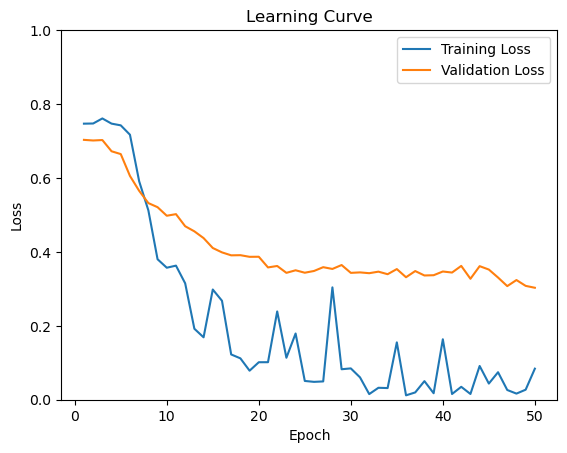

Fold 4
Accuracy Train: 0.9331428597228867. Accuracy valid: 0.7035000032186508
Recall Train: 0.8757619261741638. Recall valid: 0.643333375453949
Precision Train: 0.9114286303520203. Precision valid: 0.5058333873748779
Best Valid Accuracy Epoc: 27. Value = 0.875 Recall val = 1.0
Best Valid Recall Epoc: 25. Value = 1.0 Acc val = 0.7750000059604645


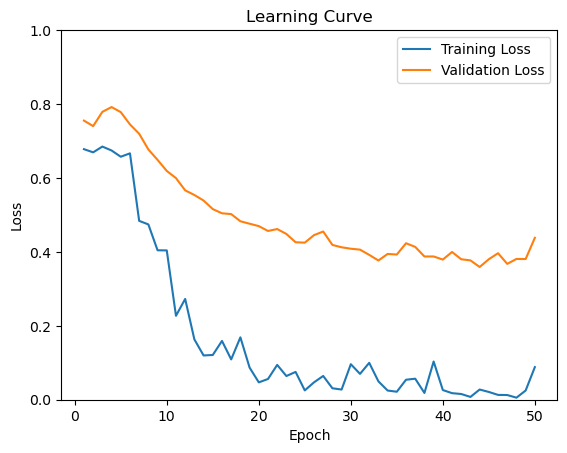

Fold 5
Accuracy Train: 0.8795000024139881. Accuracy valid: 0.8380000078678131
Recall Train: 0.703499972820282. Recall valid: 0.7300000190734863
Precision Train: 0.73. Precision valid: 0.8533333373069764
Best Valid Accuracy Epoc: 16. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 16. Value = 1.0 Acc val = 1.0


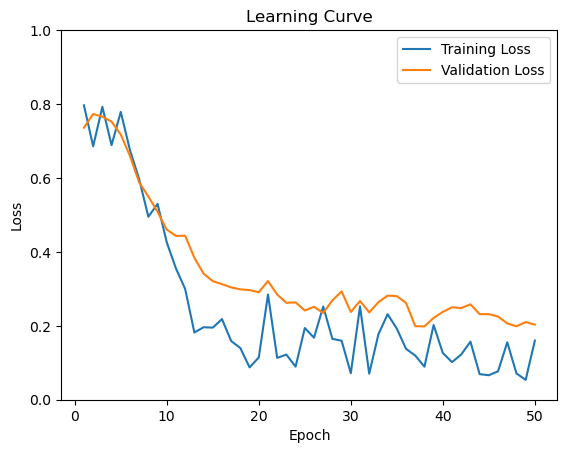

5
Fold 0: Training Loss: 0.1991674690693617, Validation Loss: 0.48526761442422867
Fold 1: Training Loss: 0.1864634883031249, Validation Loss: 0.4095151552557945
Fold 2: Training Loss: 0.21122537270188332, Validation Loss: 0.4132993081584573
Fold 3: Training Loss: 0.17221929855644702, Validation Loss: 0.4926910674571991
Fold 4: Training Loss: 0.25324836775660514, Validation Loss: 0.34630275949835776
TRAIN LOSS MEDIA: 0.2044647992774844 VALID LOSS MEDIA: 0.4294151809588075
TRAIN ACC MEDIA: 0.9109857166196619 VALID ACC MEDIA: 0.7737000046968461
TRAIN RECALL MEDIA: 0.81592857837677 VALID RECALL MEDIA: 0.6740000247955322
TRAIN PRECISION MEDIA: 0.8406666821241379 VALID PRECISION MEDIA: 0.7690000174045564


In [24]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,45, optim.AdamW , 5, 0.00001, False, None)

## ADAMW DATA AUG

Fold 1
Accuracy Train: 0.878857146884714. Accuracy valid: 0.6975000065565109
Recall Train: 0.9364286065101624. Recall valid: 0.5899999737739563
Precision Train: 0.8554286360740662. Precision valid: 0.8326666951179504
Best Valid Accuracy Epoc: 8. Value = 0.7750000059604645 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.550000011920929


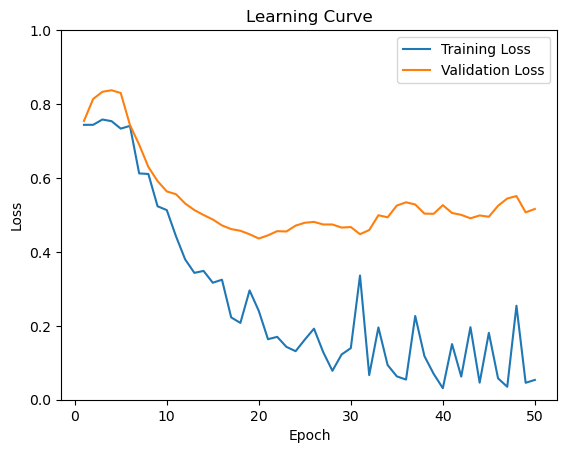

Fold 2
Accuracy Train: 0.8960000037721224. Accuracy valid: 0.8830000041425228
Recall Train: 0.8459523916244507. Recall valid: 0.8633332848548889
Precision Train: 0.8976190686225891. Precision valid: 0.9333333373069763
Best Valid Accuracy Epoc: 15. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 15. Value = 1.0 Acc val = 1.0


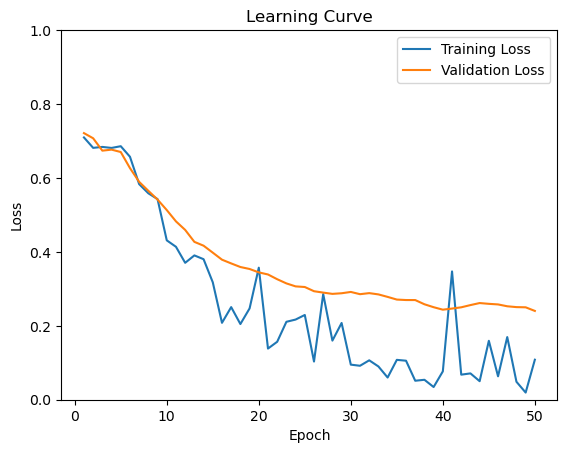

Fold 3
Accuracy Train: 0.8977142895119531. Accuracy valid: 0.8030000007152558
Recall Train: 0.8094761371612549. Recall valid: 0.6933333873748779
Precision Train: 0.8685714602470398. Precision valid: 0.83
Best Valid Accuracy Epoc: 13. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 13. Value = 0.8333333730697632 Acc val = 0.875


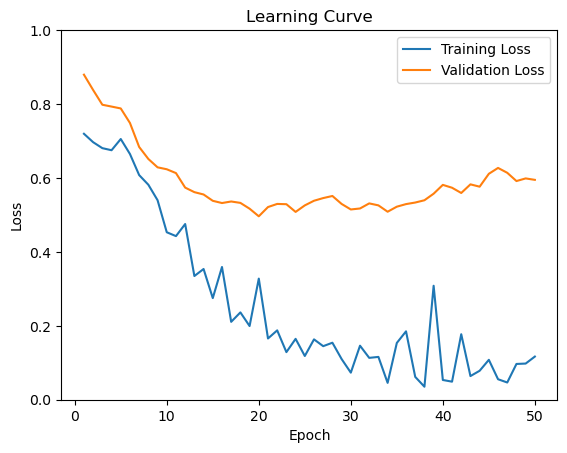

Fold 4
Accuracy Train: 0.880571432369096. Accuracy valid: 0.7775000029802323
Recall Train: 0.9108572602272034. Recall valid: 0.986666738986969
Precision Train: 0.870190441608429. Precision valid: 0.6690000295639038
Best Valid Accuracy Epoc: 15. Value = 0.875 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


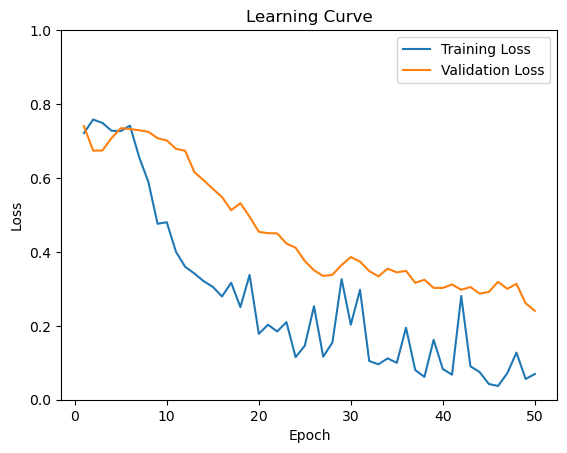

Fold 5
Accuracy Train: 0.836000003144145. Accuracy valid: 0.7646666768193245
Recall Train: 0.8877500295639038. Recall valid: 0.8050000071525574
Precision Train: 0.8147083520889282. Precision valid: 0.8766667246818542
Best Valid Accuracy Epoc: 7. Value = 0.8333333432674408 Recall val = 1.0
Best Valid Recall Epoc: 4. Value = 1.0 Acc val = 0.533333346247673


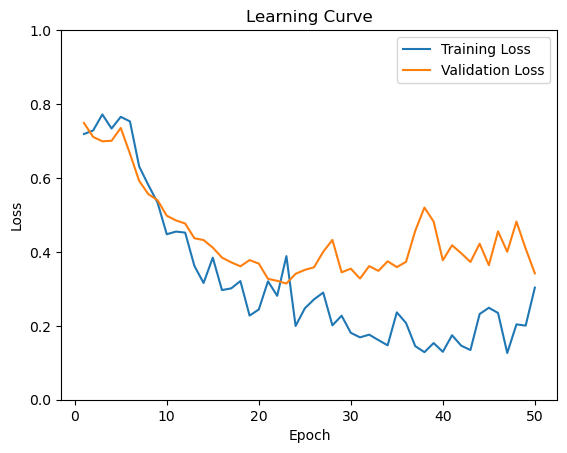

5
Fold 0: Training Loss: 0.2725140750780702, Validation Loss: 0.5393954357504844
Fold 1: Training Loss: 0.26084879502654074, Validation Loss: 0.3707923139631748
Fold 2: Training Loss: 0.26116121515631674, Validation Loss: 0.5891839307546616
Fold 3: Training Loss: 0.27679576553404334, Validation Loss: 0.45922457955777646
Fold 4: Training Loss: 0.32581698685884475, Validation Loss: 0.4427869749441743
TRAIN LOSS MEDIA: 0.27942736753076314 VALID LOSS MEDIA: 0.48027664699405437
TRAIN ACC MEDIA: 0.8778285751364061 VALID ACC MEDIA: 0.7851333382427693
TRAIN RECALL MEDIA: 0.878092885017395 VALID RECALL MEDIA: 0.7876666784286499
TRAIN PRECISION MEDIA: 0.8613036274909973 VALID PRECISION MEDIA: 0.8283333573341369


In [7]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,45, optim.AdamW , 5, 0.00001, True, None)

## ADAMW GLOROT/HE INI

Fold 1
Accuracy Train: 0.8811428604807173. Accuracy valid: 0.7255000072717667
Recall Train: 0.8486191034317017. Recall valid: 0.5049999952316284
Precision Train: 0.878095269203186. Precision valid: 0.8883333802223206
Best Valid Accuracy Epoc: 14. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 0. Value = 0.75 Acc val = 0.42500001192092896


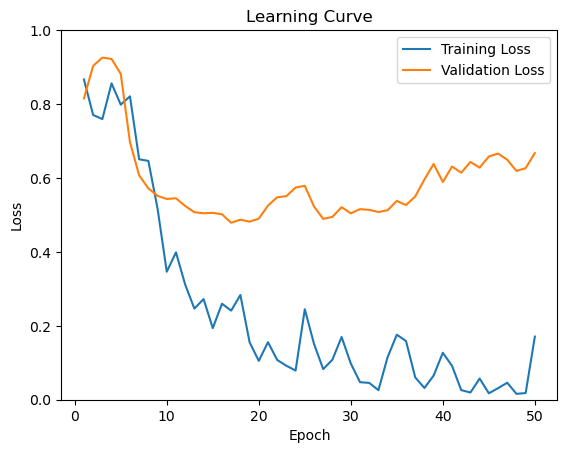

Fold 2
Accuracy Train: 0.8794285749111858. Accuracy valid: 0.7005000013113022
Recall Train: 0.8744285702705383. Recall valid: 0.893333375453949
Precision Train: 0.8609524369239807. Precision valid: 0.6008333480358123
Best Valid Accuracy Epoc: 47. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 7. Value = 1.0 Acc val = 0.6500000059604645


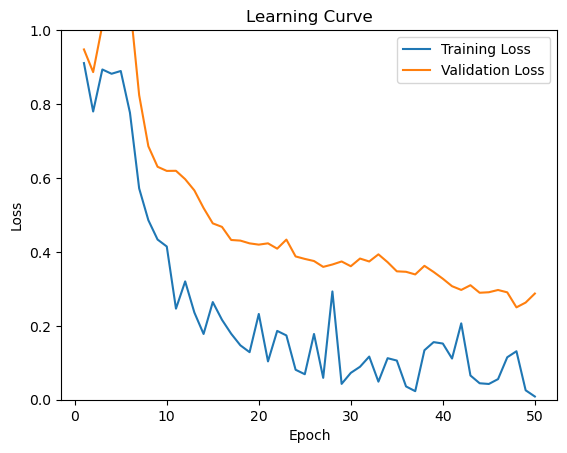

Fold 3
Accuracy Train: 0.8342857179471425. Accuracy valid: 0.7735000018775463
Recall Train: 0.9514762163162231. Recall valid: 0.8999999761581421
Precision Train: 0.8233809471130371. Precision valid: 0.8128332495689392
Best Valid Accuracy Epoc: 15. Value = 0.9000000059604645 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4750000014901161


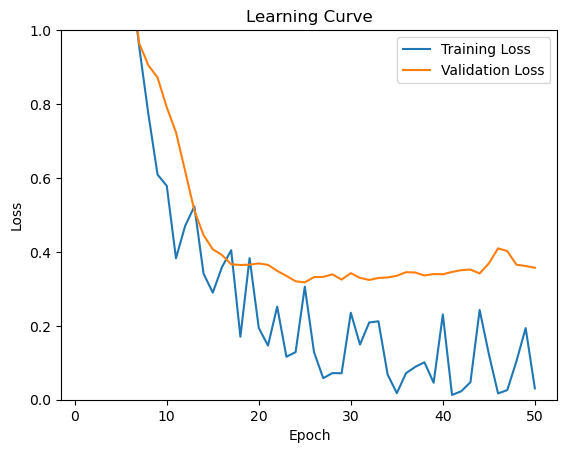

Fold 4
Accuracy Train: 0.8788571469272887. Accuracy valid: 0.711000006198883
Recall Train: 0.9209523797035217. Recall valid: 0.8899999856948853
Precision Train: 0.8573333024978638. Precision valid: 0.5584999918937683
Best Valid Accuracy Epoc: 40. Value = 0.875 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


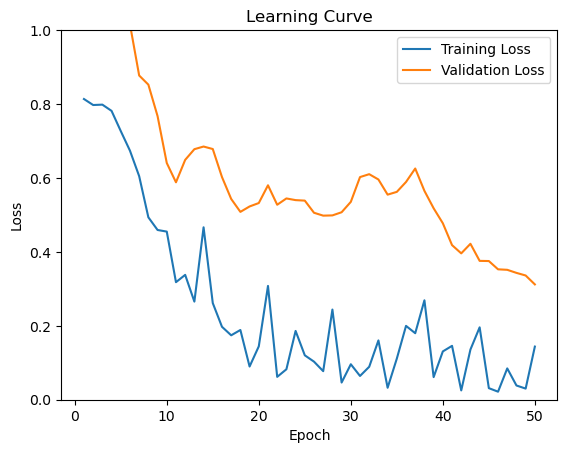

Fold 5
Accuracy Train: 0.8340000034868718. Accuracy valid: 0.7060000145435333
Recall Train: 0.6512916684150696. Recall valid: 0.4650000035762787
Precision Train: 0.7004166674613953. Precision valid: 0.72
Best Valid Accuracy Epoc: 15. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 15. Value = 0.75 Acc val = 0.8333333432674408


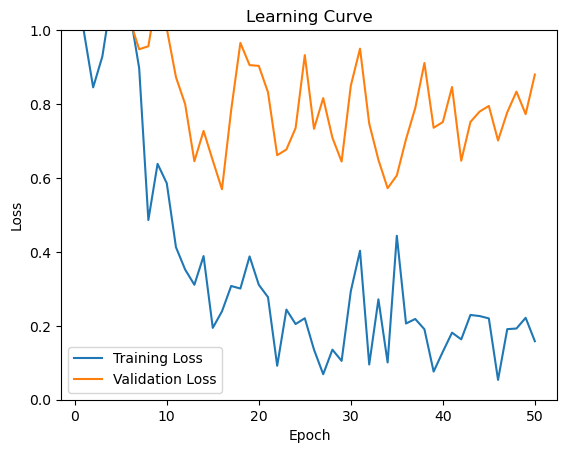

5
Fold 0: Training Loss: 0.24270664773881434, Validation Loss: 0.5928709790110588
Fold 1: Training Loss: 0.24449457667768001, Validation Loss: 0.4882077033817768
Fold 2: Training Loss: 0.3440762983076274, Validation Loss: 0.5129453229159117
Fold 3: Training Loss: 0.2504761238768697, Validation Loss: 0.6482049971818924
Fold 4: Training Loss: 0.34938920617103575, Validation Loss: 0.8380280277132988
TRAIN LOSS MEDIA: 0.2862285705544054 VALID LOSS MEDIA: 0.6160514060407877
TRAIN ACC MEDIA: 0.8615428607506412 VALID ACC MEDIA: 0.7233000062406063
TRAIN RECALL MEDIA: 0.8493536114692688 VALID RECALL MEDIA: 0.7306665778160095
TRAIN PRECISION MEDIA: 0.8240357246398926 VALID PRECISION MEDIA: 0.716099993944168


In [8]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,45, optim.AdamW , 5, 0.00001, True, 'G')

Fold 1
Accuracy Train: 0.9057142889499664. Accuracy valid: 0.715000006556511
Recall Train: 0.8573333621025085. Recall valid: 0.46000000834465027
Precision Train: 0.8833332657814026. Precision valid: 0.8666667342185974
Best Valid Accuracy Epoc: 0. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 0. Value = 0.5 Acc val = 0.7750000059604645


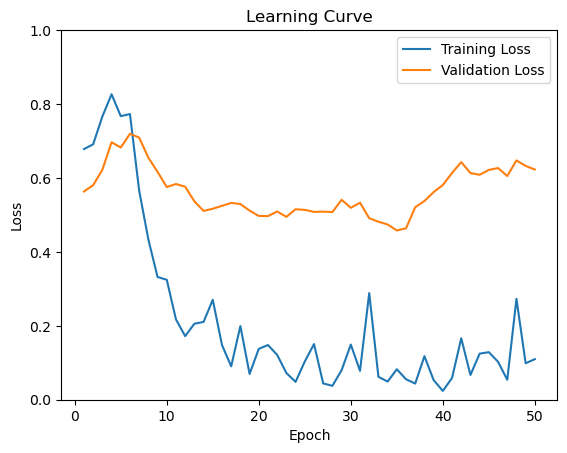

Fold 2
Accuracy Train: 0.8708571467655046. Accuracy valid: 0.7785000056028366
Recall Train: 0.9543333649635315. Recall valid: 1.0
Precision Train: 0.848380982875824. Precision valid: 0.7006666660308838
Best Valid Accuracy Epoc: 33. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


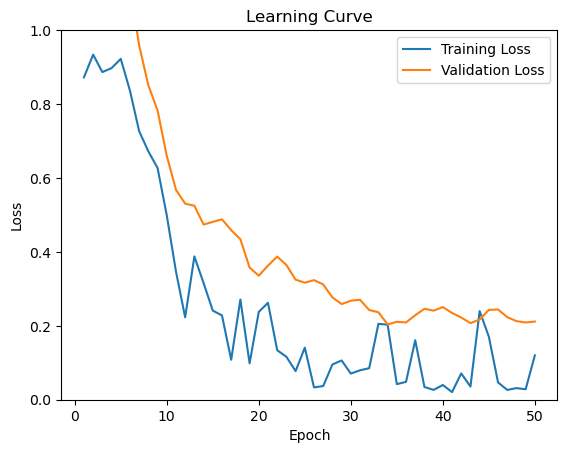

Fold 3
Accuracy Train: 0.8874285750729698. Accuracy valid: 0.7945000025629997
Recall Train: 0.9384286403656006. Recall valid: 0.8266667127609253
Precision Train: 0.870190441608429. Precision valid: 0.8758333325386047
Best Valid Accuracy Epoc: 13. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 7. Value = 1.0 Acc val = 0.675000011920929


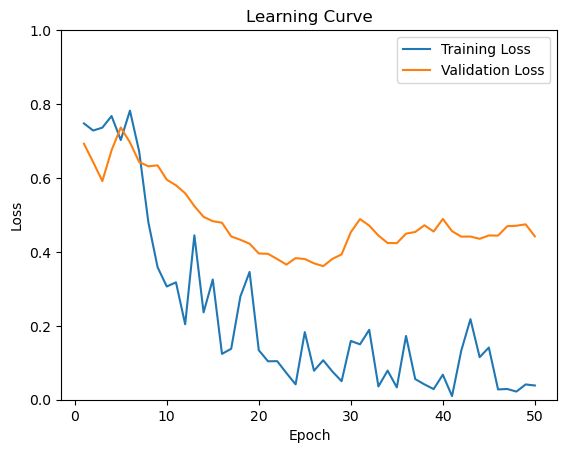

Fold 4
Accuracy Train: 0.9040000033378601. Accuracy valid: 0.8185000011324882
Recall Train: 0.9185714721679688. Recall valid: 0.9633333683013916
Precision Train: 0.8921428918838501. Precision valid: 0.6949999928474426
Best Valid Accuracy Epoc: 8. Value = 0.875 Recall val = 1.0
Best Valid Recall Epoc: 2. Value = 1.0 Acc val = 0.5250000059604645


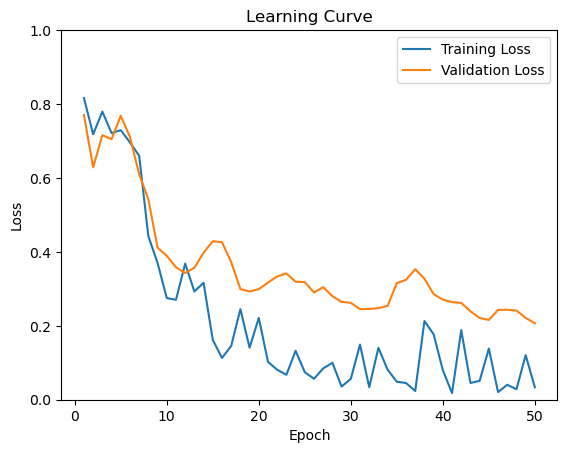

Fold 5
Accuracy Train: 0.8590000033006072. Accuracy valid: 0.8033333441615105
Recall Train: 0.690500020980835. Recall valid: 0.6850000023841858
Precision Train: 0.7341666674613953. Precision valid: 0.92
Best Valid Accuracy Epoc: 5. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 5. Value = 0.75 Acc val = 0.8333333432674408


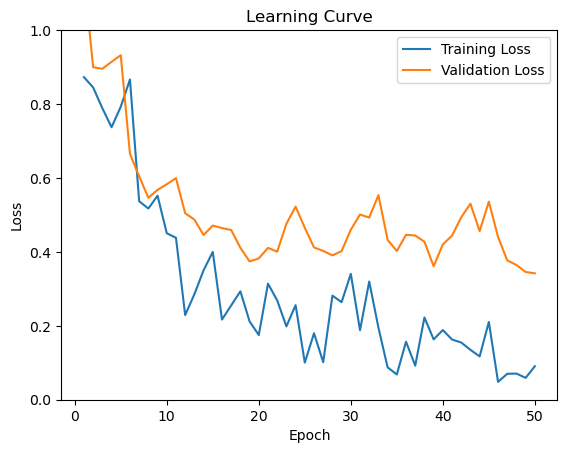

5
Fold 0: Training Loss: 0.2174121740832925, Validation Loss: 0.5638649225234985
Fold 1: Training Loss: 0.2623923386633396, Validation Loss: 0.45404099859297276
Fold 2: Training Loss: 0.22869752062484622, Validation Loss: 0.4860690729320049
Fold 3: Training Loss: 0.21902487222105266, Validation Loss: 0.36171029586344955
Fold 4: Training Loss: 0.29842603899538517, Validation Loss: 0.5101829146966338
TRAIN LOSS MEDIA: 0.24519058891758325 VALID LOSS MEDIA: 0.4751736409217119
TRAIN ACC MEDIA: 0.8854000034853817 VALID ACC MEDIA: 0.7819666720032691
TRAIN RECALL MEDIA: 0.8718334436416626 VALID RECALL MEDIA: 0.7870000600814819
TRAIN PRECISION MEDIA: 0.8456428499221802 VALID PRECISION MEDIA: 0.8116333451271057


In [9]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,45, optim.AdamW , 5, 0.00001, True, 'H')

## ADAGRAD NO AUG

### PRUEBAS LR

Fold 1
Accuracy Train: 0.8783673504785615. Accuracy valid: 0.7128571480512619
Recall Train: 0.8286395072937012. Recall valid: 0.5571428537368774
Precision Train: 0.8374829888343811. Precision valid: 0.8323809538568769
Best Valid Accuracy Epoc: 7. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.45000000298023224


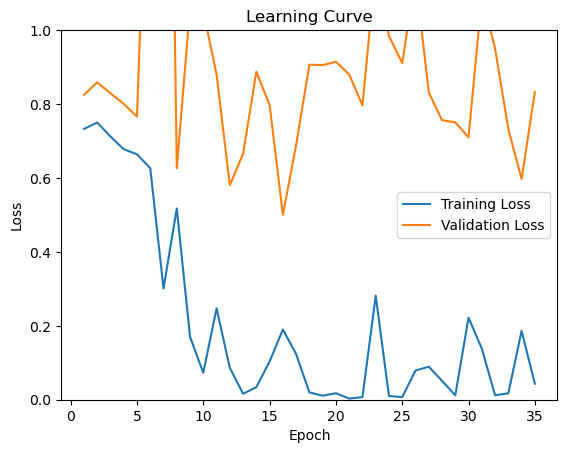

Fold 2
Accuracy Train: 0.8922449012191928. Accuracy valid: 0.919285717180797
Recall Train: 0.838503360748291. Recall valid: 0.8571428656578064
Precision Train: 0.8772109150886536. Precision valid: 0.9095238447189331
Best Valid Accuracy Epoc: 8. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.75


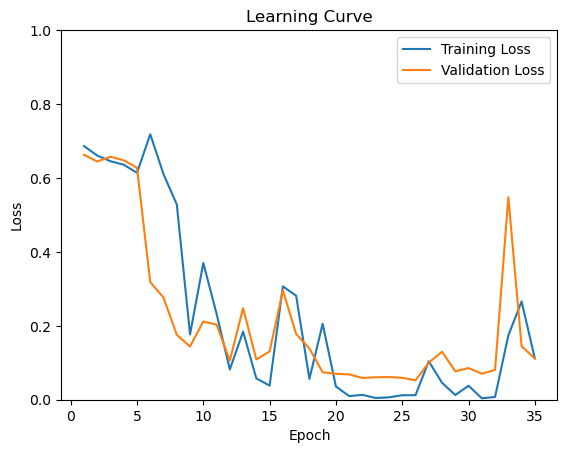

Fold 3
Accuracy Train: 0.9110204117030514. Accuracy valid: 0.8392857159887042
Recall Train: 0.8879592418670654. Recall valid: 0.833333432674408
Precision Train: 0.9031972885131836. Precision valid: 0.925000011920929
Best Valid Accuracy Epoc: 1. Value = 0.9000000059604645 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.675000011920929


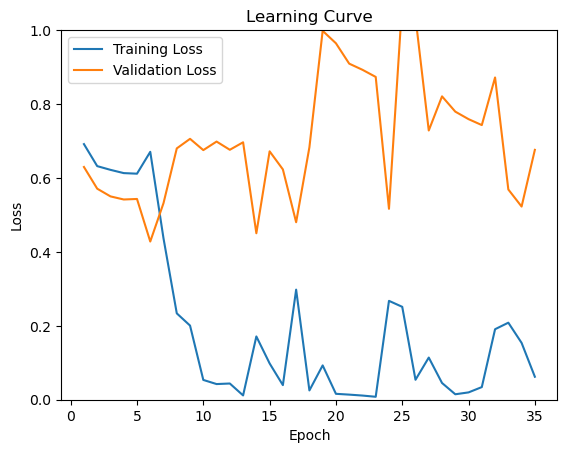

Fold 4
Accuracy Train: 0.8824489829491596. Accuracy valid: 0.8085714318922588
Recall Train: 0.8165306448936462. Recall valid: 0.9238095879554749
Precision Train: 0.8340136408805847. Precision valid: 0.6857143044471741
Best Valid Accuracy Epoc: 8. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 0.7750000059604645


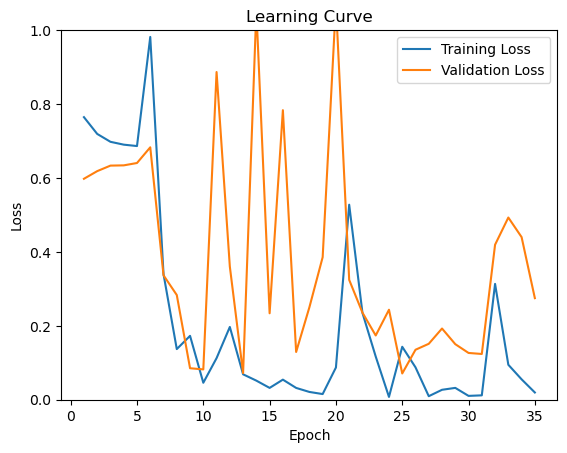

Fold 5
Accuracy Train: 0.8742857177342688. Accuracy valid: 0.8038095346518925
Recall Train: 0.7438095808029175. Recall valid: 0.8857142925262451
Precision Train: 0.7510714530944824. Precision valid: 0.7795238307544163
Best Valid Accuracy Epoc: 15. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.9000000059604645


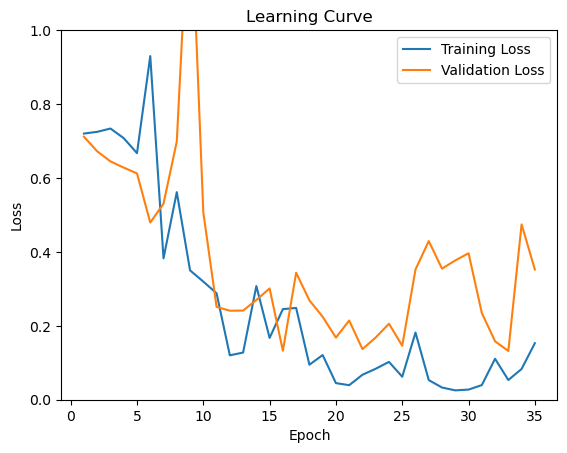

5
Fold 0: Training Loss: 0.20665298589239164, Validation Loss: 0.9310843710388456
Fold 1: Training Loss: 0.22707085918768177, Validation Loss: 0.2179707197339407
Fold 2: Training Loss: 0.2015109144151211, Validation Loss: 0.7020178718691957
Fold 3: Training Loss: 0.21708434254729322, Validation Loss: 0.3822230330269252
Fold 4: Training Loss: 0.2564945680754525, Validation Loss: 0.3847074123897723
TRAIN LOSS MEDIA: 0.22176273402358807 VALID LOSS MEDIA: 0.5236006816117359
TRAIN ACC MEDIA: 0.8876734728168468 VALID ACC MEDIA: 0.816761909552983
TRAIN RECALL MEDIA: 0.8230884671211243 VALID RECALL MEDIA: 0.8114286661148071
TRAIN PRECISION MEDIA: 0.8405952453613281 VALID PRECISION MEDIA: 0.8264285891396659


In [7]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.Adagrad , 5, 0.001, False, None)

Fold 1
Accuracy Train: 0.8302040878607303. Accuracy valid: 0.6942857197352819
Recall Train: 0.7802041172981262. Recall valid: 0.5785714387893677
Precision Train: 0.844285786151886. Precision valid: 0.7438095211982727
Best Valid Accuracy Epoc: 29. Value = 0.9000000059604645 Recall val = 0.75
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.45000000298023224


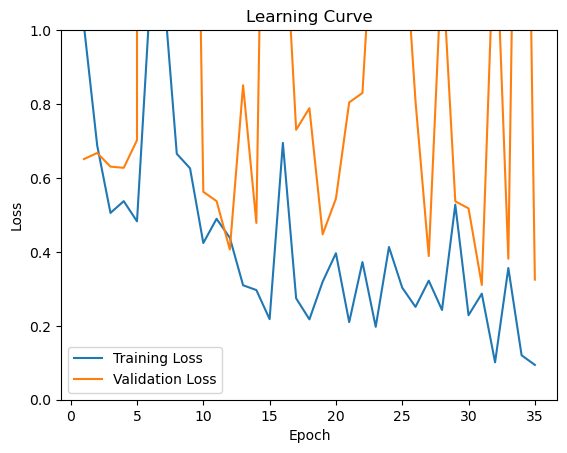

Fold 2
Accuracy Train: 0.827755108475685. Accuracy valid: 0.7092857211828232
Recall Train: 0.7956463098526001. Recall valid: 0.6047619581222534
Precision Train: 0.8256463408470154. Precision valid: 0.5828571489879063
Best Valid Accuracy Epoc: 8. Value = 0.9000000059604645 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


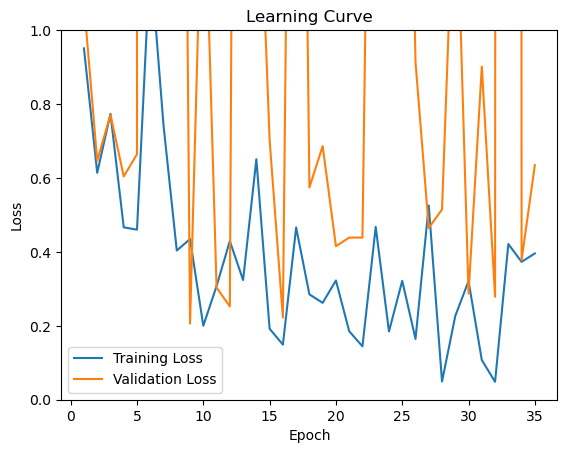

Fold 3
Accuracy Train: 0.8400000063132267. Accuracy valid: 0.7578571453690529
Recall Train: 0.7901360392570496. Recall valid: 0.7380952835083008
Precision Train: 0.8010884523391724. Precision valid: 0.7692857154778072
Best Valid Accuracy Epoc: 8. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4750000014901161


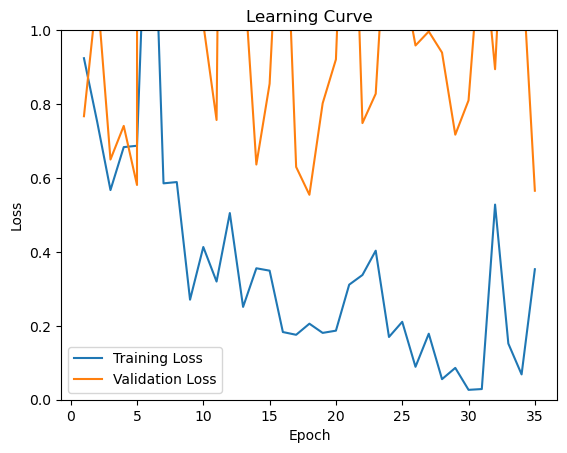

Fold 4
Accuracy Train: 0.8106122528411904. Accuracy valid: 0.7535714328289032
Recall Train: 0.7802720665931702. Recall valid: 0.8095238208770752
Precision Train: 0.822789192199707. Precision valid: 0.6095238123621259
Best Valid Accuracy Epoc: 24. Value = 0.9000000059604645 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.42500001192092896


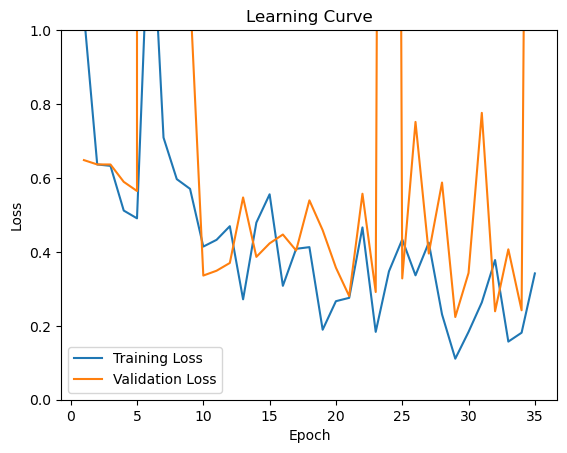

Fold 5
Accuracy Train: 0.802857149711677. Accuracy valid: 0.6247619203158787
Recall Train: 0.7016071677207947. Recall valid: 0.6214285492897034
Precision Train: 0.7302976250648499. Precision valid: 0.5414285847118923
Best Valid Accuracy Epoc: 6. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 2. Value = 1.0 Acc val = 0.533333346247673


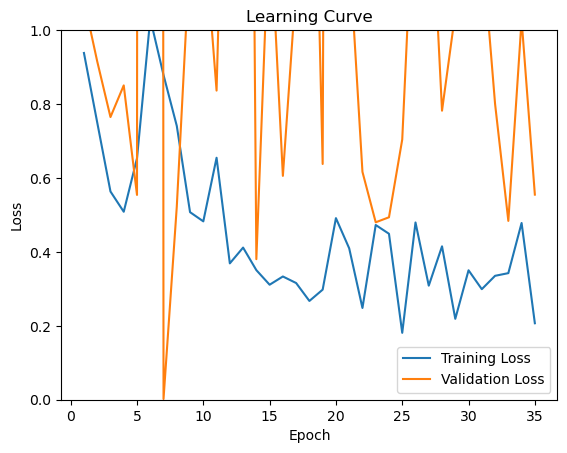

5
Fold 0: Training Loss: 0.423700707086495, Validation Loss: 4609.005616778614
Fold 1: Training Loss: 0.38768304884433746, Validation Loss: 72.7515804210711
Fold 2: Training Loss: 0.36728037148714066, Validation Loss: 4.4367837832375825
Fold 3: Training Loss: 0.43215505949088506, Validation Loss: 488.6081205543663
Fold 4: Training Loss: 0.45861388530050007, Validation Loss: 2.67792852602766
TRAIN LOSS MEDIA: 0.41388661444187164 VALID LOSS MEDIA: 1035.4960060126632
TRAIN ACC MEDIA: 0.8222857210405019 VALID ACC MEDIA: 0.7079523878863879
TRAIN RECALL MEDIA: 0.7695731520652771 VALID RECALL MEDIA: 0.6704761981964111
TRAIN PRECISION MEDIA: 0.8048214912414551 VALID PRECISION MEDIA: 0.6493809565476008


In [9]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.Adagrad , 5, 0.01, False, None)

Fold 1
Accuracy Train: 0.9151020431396911. Accuracy valid: 0.6950000073228564
Recall Train: 0.8229252099990845. Recall valid: 0.40714284777641296
Precision Train: 0.8387755108731133. Precision valid: 0.7357142857142858
Best Valid Accuracy Epoc: 8. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 8. Value = 0.5 Acc val = 0.7750000059604645


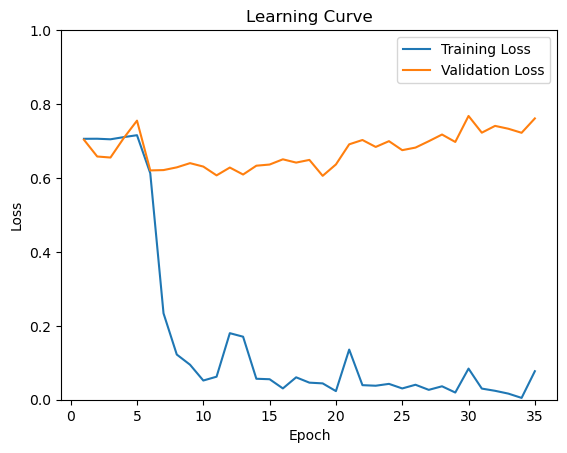

Fold 2
Accuracy Train: 0.8710204105596154. Accuracy valid: 0.8114285771335874
Recall Train: 0.8443537354469299. Recall valid: 0.9571428298950195
Precision Train: 0.8384354114532471. Precision valid: 0.7916666865348816
Best Valid Accuracy Epoc: 6. Value = 0.9000000059604645 Recall val = 1.0
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 0.9000000059604645


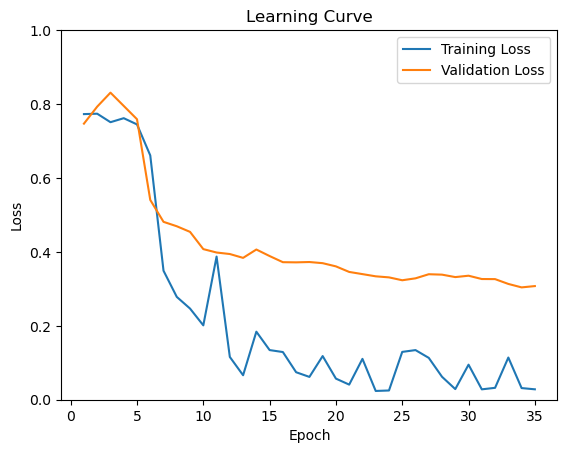

Fold 3
Accuracy Train: 0.9159183696216465. Accuracy valid: 0.7935714295932225
Recall Train: 0.7962585687637329. Recall valid: 0.6619048714637756
Precision Train: 0.8081632673740387. Precision valid: 0.8142857142857143
Best Valid Accuracy Epoc: 11. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 11. Value = 0.8333333730697632 Acc val = 0.875


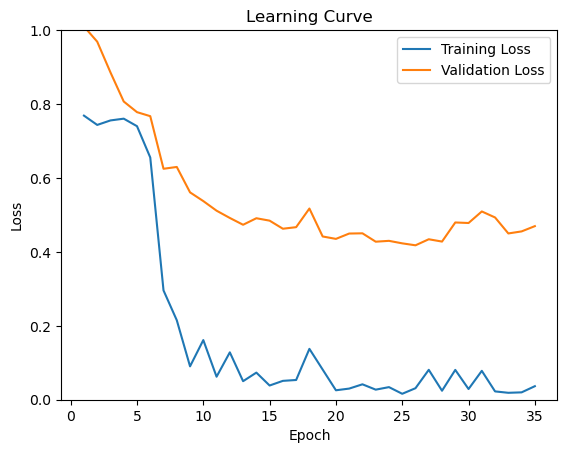

Fold 4
Accuracy Train: 0.8816326557981725. Accuracy valid: 0.6542857182877404
Recall Train: 0.9263265132904053. Recall valid: 0.6142857074737549
Precision Train: 0.8703401684761047. Precision valid: 0.45404762029647827
Best Valid Accuracy Epoc: 11. Value = 0.75 Recall val = 0.5
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


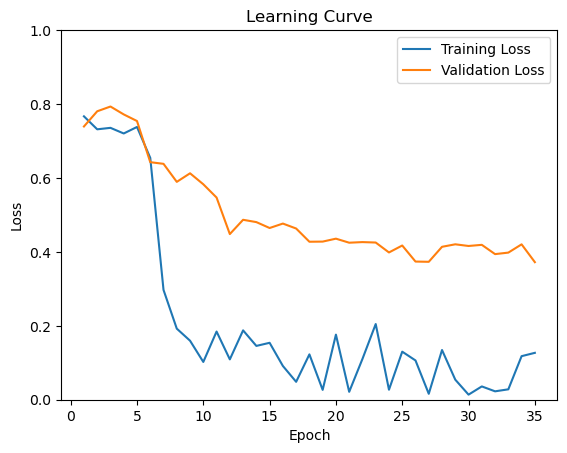

Fold 5
Accuracy Train: 0.8678571450390986. Accuracy valid: 0.9038095267755645
Recall Train: 0.7130952477455139. Recall valid: 0.8714285492897034
Precision Train: 0.75. Precision valid: 0.9142857193946838
Best Valid Accuracy Epoc: 6. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 1.0


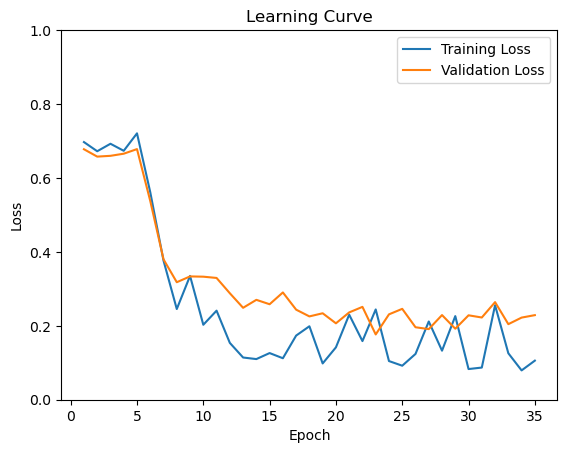

5
Fold 0: Training Loss: 0.17241865864821843, Validation Loss: 0.6747106075286865
Fold 1: Training Loss: 0.22471112225736892, Validation Loss: 0.42915221133402415
Fold 2: Training Loss: 0.18453986266893999, Validation Loss: 0.5468725712703807
Fold 3: Training Loss: 0.21411158894853932, Validation Loss: 0.5044582145554679
Fold 4: Training Loss: 0.25449445119925906, Validation Loss: 0.31873117962053843
TRAIN LOSS MEDIA: 0.21005513674446513 VALID LOSS MEDIA: 0.49478495686181956
TRAIN ACC MEDIA: 0.8903061248316447 VALID ACC MEDIA: 0.7716190518225942
TRAIN RECALL MEDIA: 0.820591926574707 VALID RECALL MEDIA: 0.7023809552192688
TRAIN PRECISION MEDIA: 0.8211428716353006 VALID PRECISION MEDIA: 0.7420000052452087


In [10]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.Adagrad , 5, 0.0001, False, None)

### PRUEBAS BS

Fold 1
Accuracy Train: 0.8730158763982001. Accuracy valid: 0.7333333463895889
Recall Train: 0.7035714983940125. Recall valid: 0.4523809552192688
Precision Train: 0.7452381253242493. Precision valid: 0.5761904920850481
Best Valid Accuracy Epoc: 6. Value = 0.7777777910232544 Recall val = 0.5
Best Valid Recall Epoc: 7. Value = 0.8333333134651184 Acc val = 0.7777777910232544


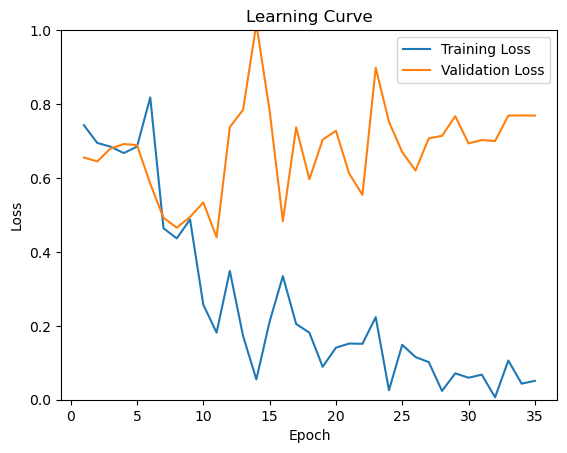

Fold 2
Accuracy Train: 0.8678571464050383. Accuracy valid: 0.911111113854817
Recall Train: 0.7035714387893677. Recall valid: 0.8571428656578064
Precision Train: 0.7345237731933594. Precision valid: 0.855555534362793
Best Valid Accuracy Epoc: 7. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.8888888955116272


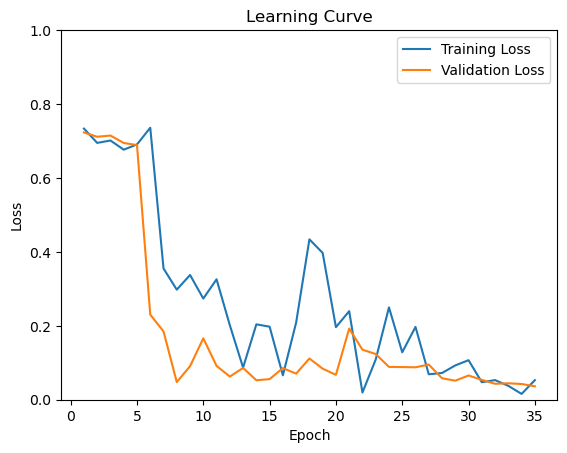

Fold 3
Accuracy Train: 0.8702380982892853. Accuracy valid: 0.8190476281302316
Recall Train: 0.6936507821083069. Recall valid: 0.6428570747375488
Precision Train: 0.7198413014411926. Precision valid: 0.6126984272684369
Best Valid Accuracy Epoc: 3. Value = 0.8888888955116272 Recall val = 0.8333333134651184
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.5555555721124014


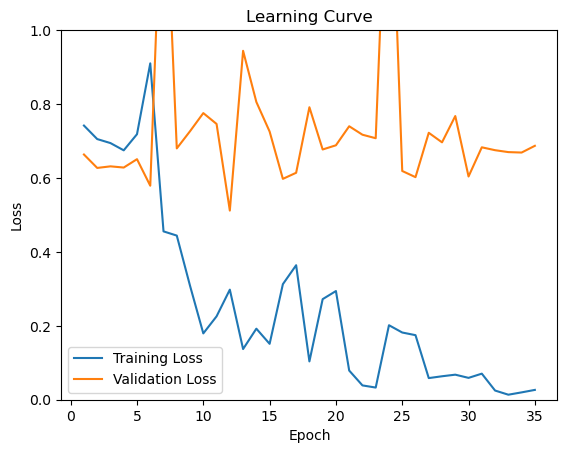

Fold 4
Accuracy Train: 0.8690476220278512. Accuracy valid: 0.806349216472535
Recall Train: 0.7253968119621277. Recall valid: 0.8809523582458496
Precision Train: 0.7523809671401978. Precision valid: 0.7222221493721008
Best Valid Accuracy Epoc: 9. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.4444444576899211


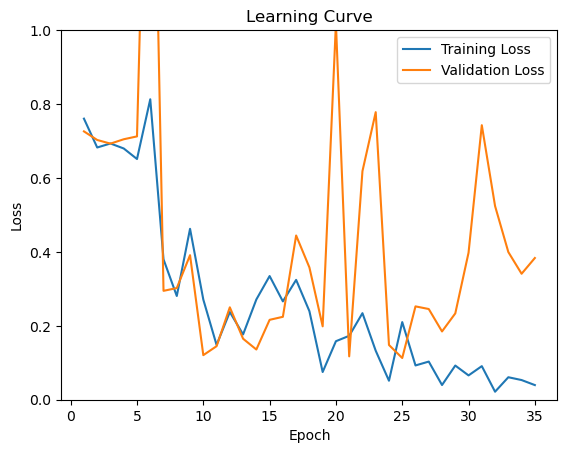

Fold 5
Accuracy Train: 0.8849206387287094. Accuracy valid: 0.8190476247242519
Recall Train: 0.7178570628166199. Recall valid: 0.7523809671401978
Precision Train: 0.7583332657814026. Precision valid: 0.6730158925056458
Best Valid Accuracy Epoc: 13. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.5000000099341074


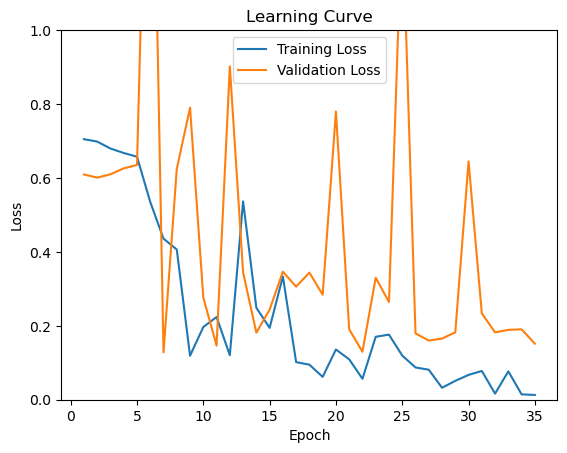

5
Fold 0: Training Loss: 0.26299390399030276, Validation Loss: 0.675319427145379
Fold 1: Training Loss: 0.26587382070720195, Validation Loss: 0.1779046580195427
Fold 2: Training Loss: 0.26557240975754604, Validation Loss: 0.7357168097403787
Fold 3: Training Loss: 0.26761747992464474, Validation Loss: 0.43854753318287076
Fold 4: Training Loss: 0.23720066164221082, Validation Loss: 0.43719353454098814
TRAIN LOSS MEDIA: 0.25985165520438125 VALID LOSS MEDIA: 0.4929363925258318
TRAIN ACC MEDIA: 0.8730158763698169 VALID ACC MEDIA: 0.8177777859142848
TRAIN RECALL MEDIA: 0.708809494972229 VALID RECALL MEDIA: 0.7171428799629211
TRAIN PRECISION MEDIA: 0.7420634031295776 VALID PRECISION MEDIA: 0.687936499118805


In [11]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.Adagrad , 3, 0.001, False, None)

Fold 1
Accuracy Train: 0.8754761913844518. Accuracy valid: 0.44821428571428573
Recall Train: 0.8155238628387451. Recall valid: 0.3333333134651184
Precision Train: 0.8293333053588867. Precision valid: 0.464880952664784
Best Valid Accuracy Epoc: 7. Value = 0.9375 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 0.6875


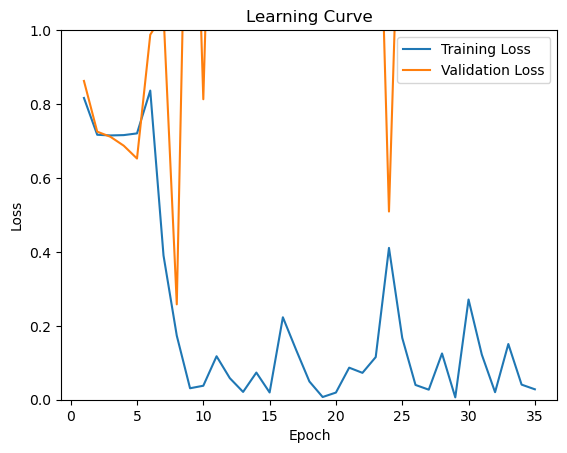

Fold 2
Accuracy Train: 0.8890476201261794. Accuracy valid: 0.7910714285714285
Recall Train: 0.8639047145843506. Recall valid: 0.699999988079071
Precision Train: 0.8608570694923401. Precision valid: 0.7642857142857142
Best Valid Accuracy Epoc: 11. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 11. Value = 1.0 Acc val = 1.0


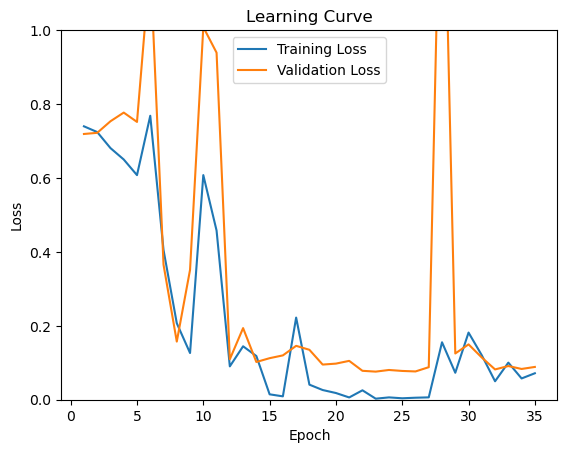

Fold 3
Accuracy Train: 0.9080952388899667. Accuracy valid: 0.8089285714285714
Recall Train: 0.8904489278793335. Recall valid: 0.7142858505249023
Precision Train: 0.8919999003410339. Precision valid: 0.8369047675813948
Best Valid Accuracy Epoc: 6. Value = 0.9375 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 7. Value = 1.0 Acc val = 0.6875


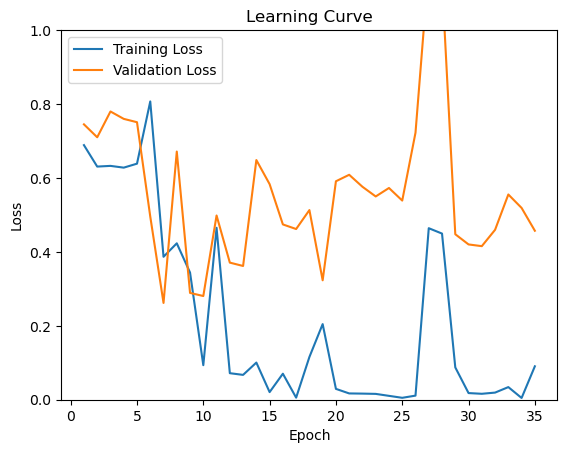

Fold 4
Accuracy Train: 0.9126190485273089. Accuracy valid: 0.7589285714285714
Recall Train: 0.8760407567024231. Recall valid: 0.46785715222358704
Precision Train: 0.8860952258110046. Precision valid: 0.33564624190330505
Best Valid Accuracy Epoc: 26. Value = 1.0 Recall val = 0.5
Best Valid Recall Epoc: 1. Value = 0.5 Acc val = 0.25


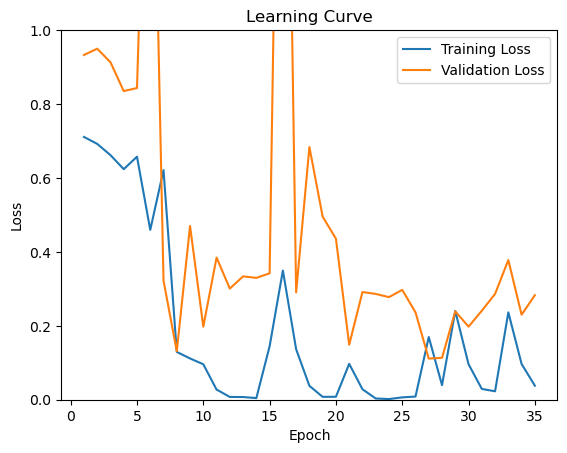

Fold 5
Accuracy Train: 0.8871428571428571. Accuracy valid: 0.8
Recall Train: 0.8019999861717224. Recall valid: 0.7142857313156128
Precision Train: 0.8136190176010132. Precision valid: 0.8174149692058563
Best Valid Accuracy Epoc: 16. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 7. Value = 1.0 Acc val = 0.625


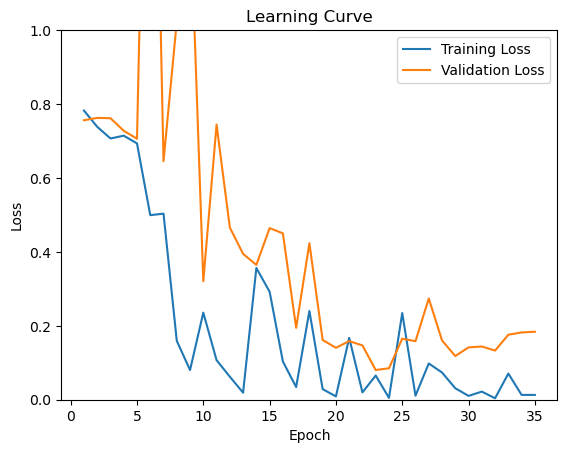

5
Fold 0: Training Loss: 0.21606512740254402, Validation Loss: 2.244986530712673
Fold 1: Training Loss: 0.2149994157720357, Validation Loss: 0.3382333596818301
Fold 2: Training Loss: 0.21953991853765079, Validation Loss: 0.5634198095050773
Fold 3: Training Loss: 0.18881370175762902, Validation Loss: 0.49809283991510583
Fold 4: Training Loss: 0.20585288740694524, Validation Loss: 0.44264387892825263
TRAIN LOSS MEDIA: 0.20905421017536097 VALID LOSS MEDIA: 0.8174752837485876
TRAIN ACC MEDIA: 0.8944761912141528 VALID ACC MEDIA: 0.7214285714285713
TRAIN RECALL MEDIA: 0.849583625793457 VALID RECALL MEDIA: 0.5859524011611938
TRAIN PRECISION MEDIA: 0.8563809394836426 VALID PRECISION MEDIA: 0.6438265291282109


In [12]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.Adagrad , 8, 0.001, False, None)

Fold 1
Accuracy Train: 0.869642858845847. Accuracy valid: 0.7301587453910283
Recall Train: 0.8289411067962646. Recall valid: 0.4928571283817291
Precision Train: 0.8579233288764954. Precision valid: 0.7650793663093022
Best Valid Accuracy Epoc: 19. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 12. Value = 1.0 Acc val = 0.4444444477558136


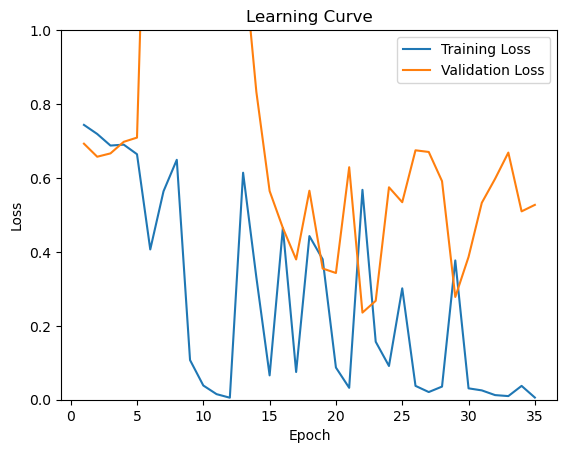

Fold 2
Accuracy Train: 0.8829365103017717. Accuracy valid: 0.8888888955116272
Recall Train: 0.8181859254837036. Recall valid: 0.8785714507102966
Precision Train: 0.8624318242073059. Precision valid: 0.9204761981964111
Best Valid Accuracy Epoc: 6. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.5555555820465088


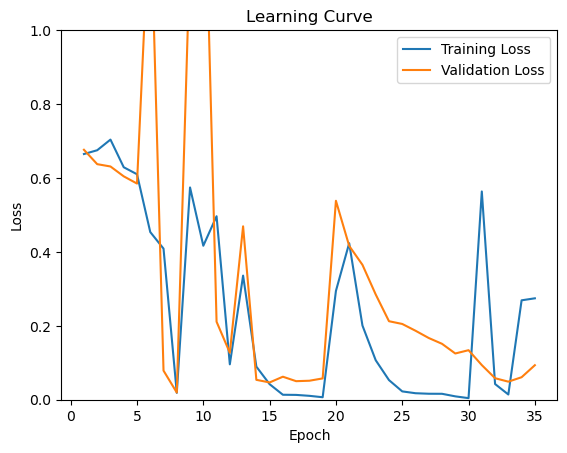

Fold 3
Accuracy Train: 0.905753969578516. Accuracy valid: 0.7682539795126234
Recall Train: 0.9046598672866821. Recall valid: 0.6928571462631226
Precision Train: 0.8916175961494446. Precision valid: 0.8423809553895678
Best Valid Accuracy Epoc: 2. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.4444444477558136


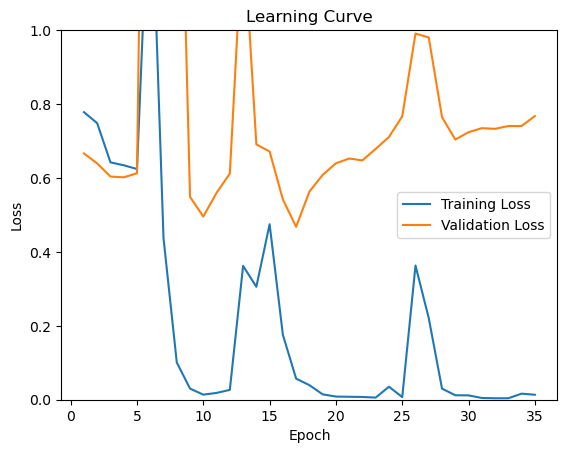

Fold 4
Accuracy Train: 0.8823412716388702. Accuracy valid: 0.7492063633033208
Recall Train: 0.8186394572257996. Recall valid: 0.8142856955528259
Precision Train: 0.8523129224777222. Precision valid: 0.5853514867169517
Best Valid Accuracy Epoc: 20. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.7777777910232544


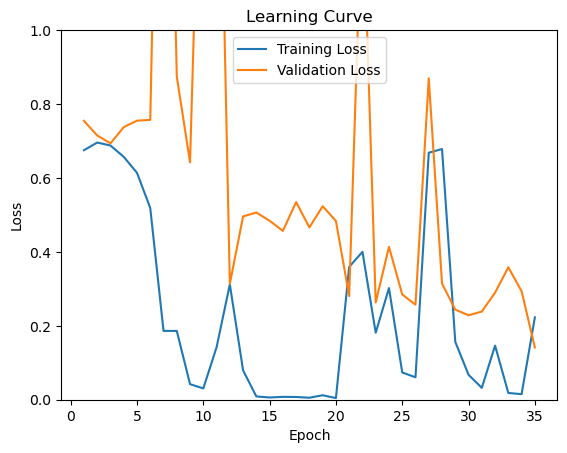

Fold 5
Accuracy Train: 0.8958333333333333. Accuracy valid: 0.75
Recall Train: 0.8456953763961792. Recall valid: 0.7142857313156128
Precision Train: 0.8742554783821106. Precision valid: 0.7839455808912005
Best Valid Accuracy Epoc: 9. Value = 0.875 Recall val = 1.0
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.5


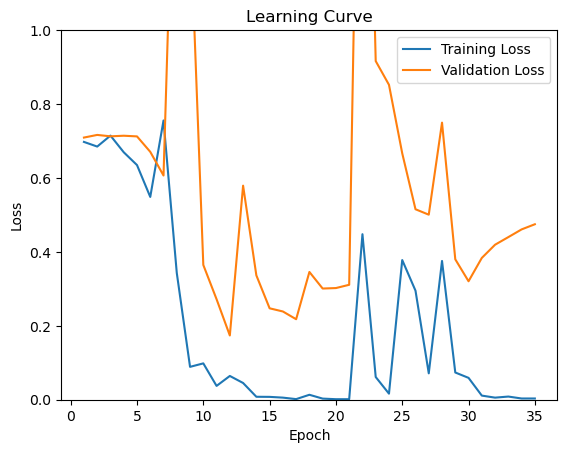

5
Fold 0: Training Loss: 0.2712390010644283, Validation Loss: 0.7379562590803419
Fold 1: Training Loss: 0.24530978413032634, Validation Loss: 0.3329936267009803
Fold 2: Training Loss: 0.22076190247067384, Validation Loss: 0.812794988495963
Fold 3: Training Loss: 0.23604211432061026, Validation Loss: 0.6412963079554694
Fold 4: Training Loss: 0.20672572137056186, Validation Loss: 0.6021003437893732
TRAIN LOSS MEDIA: 0.2360157046713201 VALID LOSS MEDIA: 0.6254283052044256
TRAIN ACC MEDIA: 0.8873015887396676 VALID ACC MEDIA: 0.77730159674372
TRAIN RECALL MEDIA: 0.8432243466377258 VALID RECALL MEDIA: 0.7185714840888977
TRAIN PRECISION MEDIA: 0.8677083253860474 VALID PRECISION MEDIA: 0.7794467175006867


In [13]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.Adagrad , 16, 0.001, False, None)

### PRUEBAS EPOCS

Fold 1
Accuracy Train: 0.8880000037380629. Accuracy valid: 0.7595000064373016
Recall Train: 0.854285717010498. Recall valid: 0.49000000953674316
Precision Train: 0.878761887550354. Precision valid: 0.9100000023841858
Best Valid Accuracy Epoc: 3. Value = 0.9000000059604645 Recall val = 0.75
Best Valid Recall Epoc: 1. Value = 0.75 Acc val = 0.675000011920929


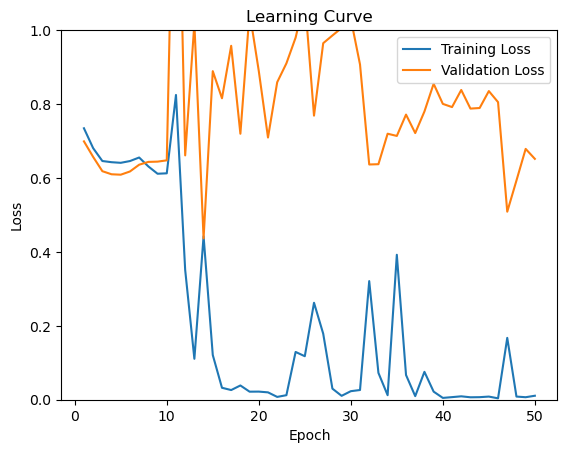

Fold 2
Accuracy Train: 0.8834285757371358. Accuracy valid: 0.8420000064373017
Recall Train: 0.8080953359603882. Recall valid: 0.8233333826065063
Precision Train: 0.8581905364990234. Precision valid: 0.8963333368301392
Best Valid Accuracy Epoc: 15. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


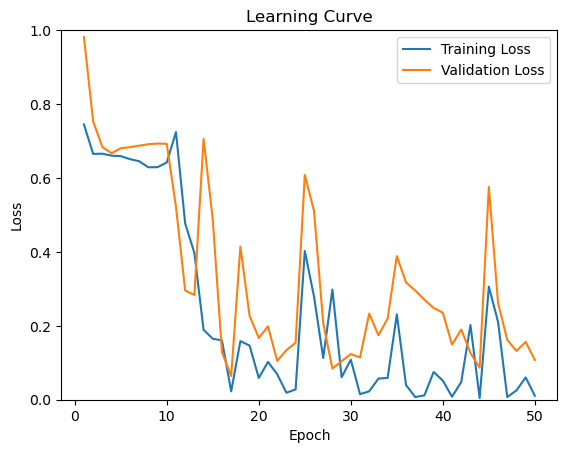

Fold 3
Accuracy Train: 0.904000004019056. Accuracy valid: 0.8000000011920929
Recall Train: 0.8144762516021729. Recall valid: 0.6600000262260437
Precision Train: 0.8647618889808655. Precision valid: 0.8
Best Valid Accuracy Epoc: 10. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 10. Value = 0.8333333730697632 Acc val = 0.875


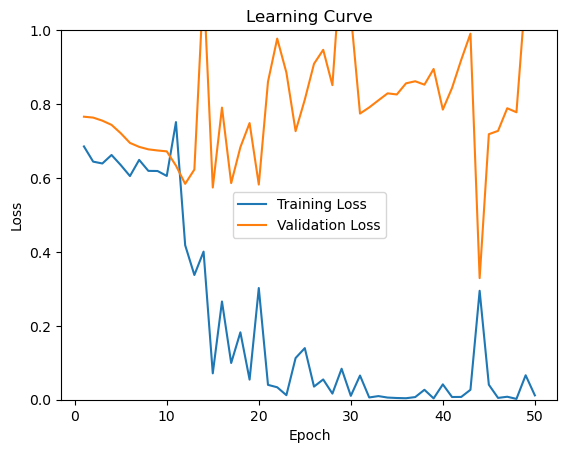

Fold 4
Accuracy Train: 0.9062857179130828. Accuracy valid: 0.7480000045895576
Recall Train: 0.8525238633155823. Recall valid: 0.8833333849906921
Precision Train: 0.8910475969314575. Precision valid: 0.6433332562446594
Best Valid Accuracy Epoc: 23. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 10. Value = 1.0 Acc val = 0.42500001192092896


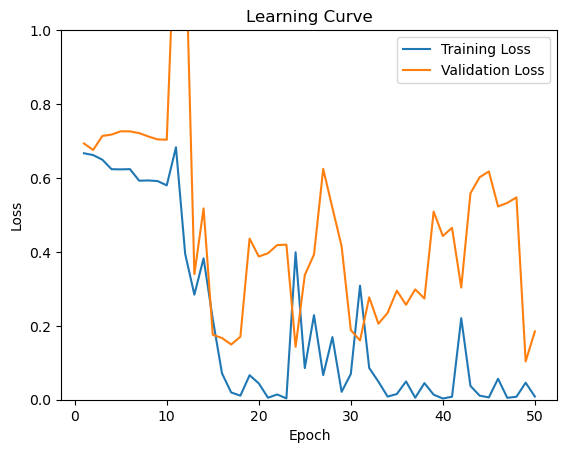

Fold 5
Accuracy Train: 0.8705000030249357. Accuracy valid: 0.8046666738390923
Recall Train: 0.7150416374206543. Recall valid: 0.75
Precision Train: 0.7184999585151672. Precision valid: 0.7906666696071625
Best Valid Accuracy Epoc: 11. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.533333346247673


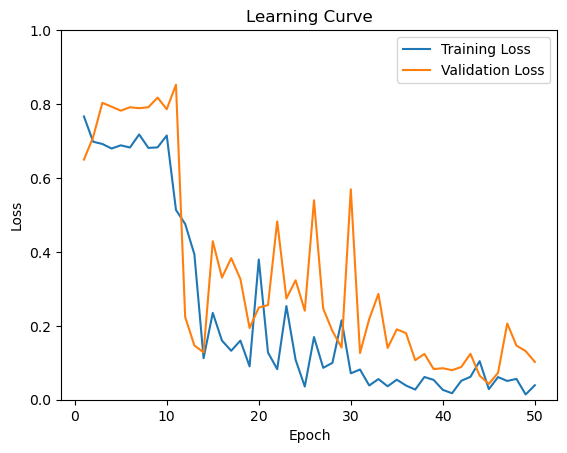

5
Fold 0: Training Loss: 0.2104302684776485, Validation Loss: 0.794415942132473
Fold 1: Training Loss: 0.2404551561921835, Validation Loss: 0.34361402940005065
Fold 2: Training Loss: 0.20862721549812704, Validation Loss: 0.7967531632469036
Fold 3: Training Loss: 0.20873499951325358, Validation Loss: 0.4664586669579148
Fold 4: Training Loss: 0.23728907268494367, Validation Loss: 0.336738668307662
TRAIN LOSS MEDIA: 0.22110734247323127 VALID LOSS MEDIA: 0.5475960940090008
TRAIN ACC MEDIA: 0.8904428608864545 VALID ACC MEDIA: 0.7908333384990692
TRAIN RECALL MEDIA: 0.8088845014572144 VALID RECALL MEDIA: 0.721333384513855
TRAIN PRECISION MEDIA: 0.8422524333000183 VALID PRECISION MEDIA: 0.8080666530132294


In [14]:
prueba_k_fold_resnet_pre(df_mean, 5, 10,40, optim.Adagrad , 5, 0.001, False, None)

Fold 1
Accuracy Train: 0.9281632677024724. Accuracy valid: 0.7457142915044512
Recall Train: 0.8799999952316284. Recall valid: 0.5071428418159485
Precision Train: 0.8945578213248934. Precision valid: 0.9104761907032558
Best Valid Accuracy Epoc: 22. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 2. Value = 1.0 Acc val = 0.45000000298023224


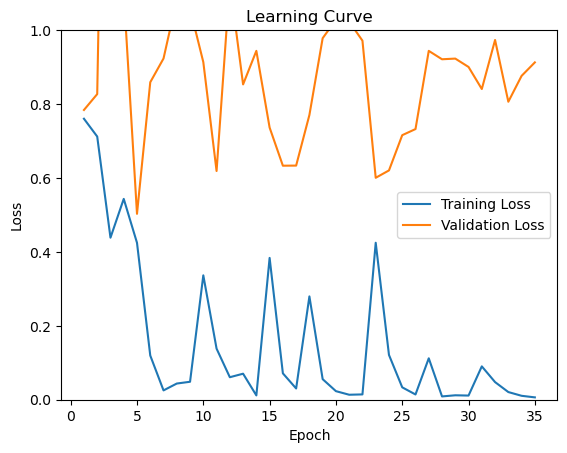

Fold 2
Accuracy Train: 0.9330612271415945. Accuracy valid: 0.9471428577389036
Recall Train: 0.9061225056648254. Recall valid: 0.9666667580604553
Precision Train: 0.9057143330574036. Precision valid: 0.93452388048172
Best Valid Accuracy Epoc: 4. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 3. Value = 1.0 Acc val = 0.75


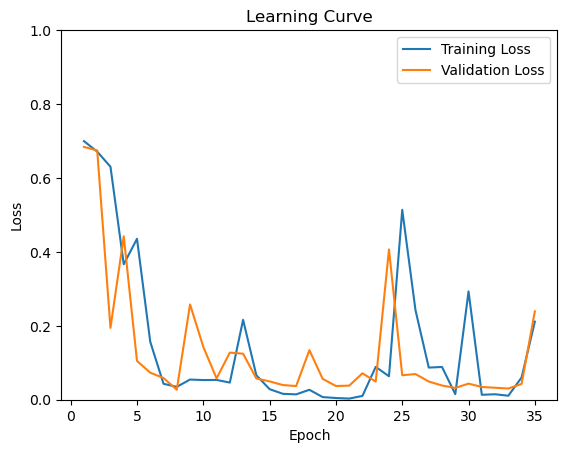

Fold 3
Accuracy Train: 0.9322449007812811. Accuracy valid: 0.8057142872895513
Recall Train: 0.9129931926727295. Recall valid: 0.7904762029647827
Precision Train: 0.925782322883606. Precision valid: 0.9047619700431824
Best Valid Accuracy Epoc: 5. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 32. Value = 1.0 Acc val = 0.7000000029802322


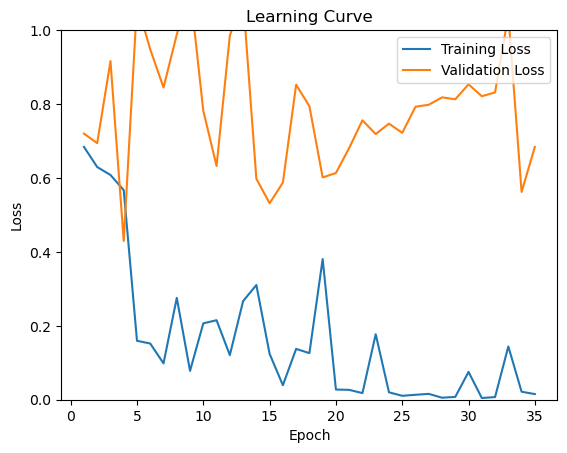

Fold 4
Accuracy Train: 0.9224489822071426. Accuracy valid: 0.7678571483918599
Recall Train: 0.8762585520744324. Recall valid: 0.8857142925262451
Precision Train: 0.8816326856613159. Precision valid: 0.6328571447304316
Best Valid Accuracy Epoc: 8. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 3. Value = 1.0 Acc val = 0.9000000059604645


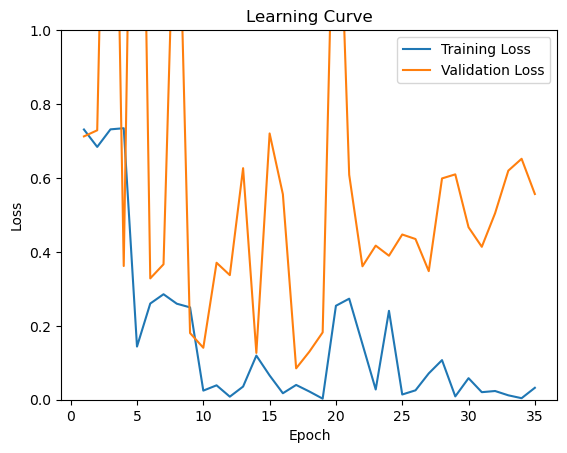

Fold 5
Accuracy Train: 0.8971428591225828. Accuracy valid: 0.7666666775941848
Recall Train: 0.7995833158493042. Recall valid: 0.7357142567634583
Precision Train: 0.8051786422729492. Precision valid: 0.8495238150869097
Best Valid Accuracy Epoc: 3. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 2. Value = 1.0 Acc val = 0.6333333551883698


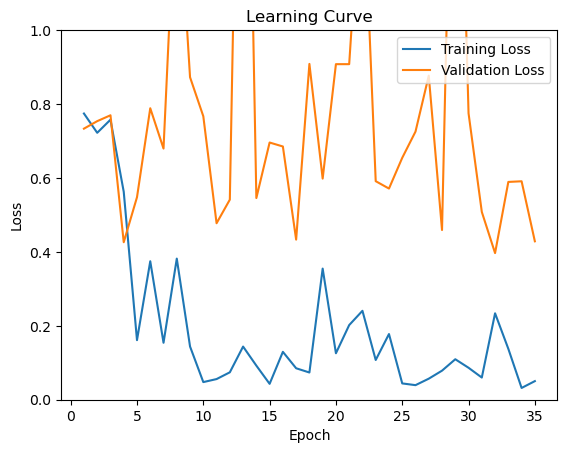

5
Fold 0: Training Loss: 0.15767542464392525, Validation Loss: 0.9115946135350637
Fold 1: Training Loss: 0.152607404081417, Validation Loss: 0.13210744865770851
Fold 2: Training Loss: 0.16484553551833545, Validation Loss: 0.7835184057176645
Fold 3: Training Loss: 0.16511657609870392, Validation Loss: 0.6184940049158675
Fold 4: Training Loss: 0.1975577728024551, Validation Loss: 0.7898053423235459
TRAIN LOSS MEDIA: 0.16756054262896733 VALID LOSS MEDIA: 0.64710396302997
TRAIN ACC MEDIA: 0.9226122473910147 VALID ACC MEDIA: 0.8066190525037902
TRAIN RECALL MEDIA: 0.8749915361404419 VALID RECALL MEDIA: 0.7771428823471069
TRAIN PRECISION MEDIA: 0.8825731610400336 VALID PRECISION MEDIA: 0.8464286002090999


In [15]:
prueba_k_fold_resnet_pre(df_mean, 5, 2,33, optim.Adagrad , 5, 0.001, False, None)

Fold 1
Accuracy Train: 0.9222857167465347. Accuracy valid: 0.7235000060498714
Recall Train: 0.8830476403236389. Recall valid: 0.5350000262260437
Precision Train: 0.8973333835601807. Precision valid: 0.905500054359436
Best Valid Accuracy Epoc: 7. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.45000000298023224


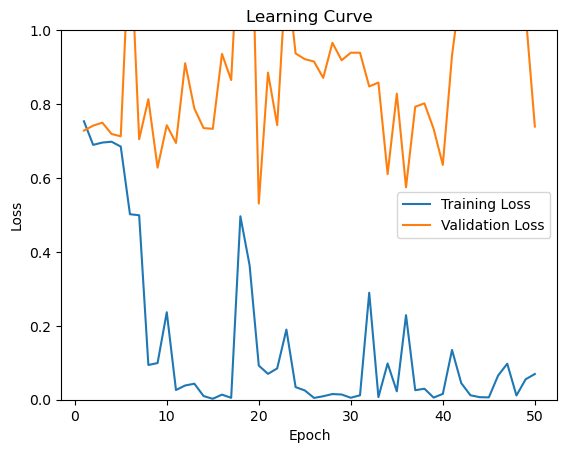

Fold 2
Accuracy Train: 0.9091428594929831. Accuracy valid: 0.9115000018477439
Recall Train: 0.8697142601013184. Recall valid: 0.8700000047683716
Precision Train: 0.8790476322174072. Precision valid: 0.8666666674613953
Best Valid Accuracy Epoc: 8. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.6500000059604645


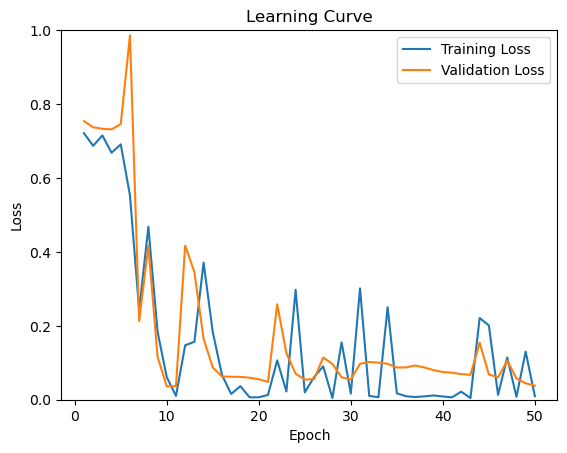

Fold 3
Accuracy Train: 0.9297142884135247. Accuracy valid: 0.8355000013113022
Recall Train: 0.8982856869697571. Recall valid: 0.7933333516120911
Precision Train: 0.9223809838294983. Precision valid: 0.9066666680574417
Best Valid Accuracy Epoc: 7. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 4. Value = 1.0 Acc val = 0.800000011920929


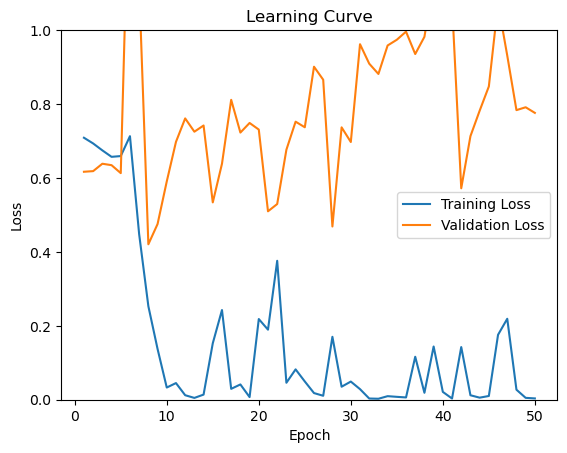

Fold 4
Accuracy Train: 0.9102857169083187. Accuracy valid: 0.8400000017881394
Recall Train: 0.84333336353302. Recall valid: 0.8899999856948853
Precision Train: 0.8692857623100281. Precision valid: 0.705
Best Valid Accuracy Epoc: 9. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.7750000059604645


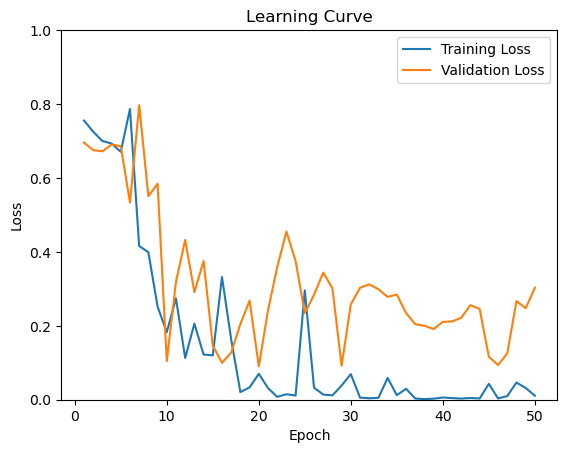

Fold 5
Accuracy Train: 0.9100000021234155. Accuracy valid: 0.743333342820406
Recall Train: 0.812791645526886. Recall valid: 0.7350000143051147
Precision Train: 0.831250011920929. Precision valid: 0.8425000059604645
Best Valid Accuracy Epoc: 6. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 7. Value = 1.0 Acc val = 0.7333333492279053


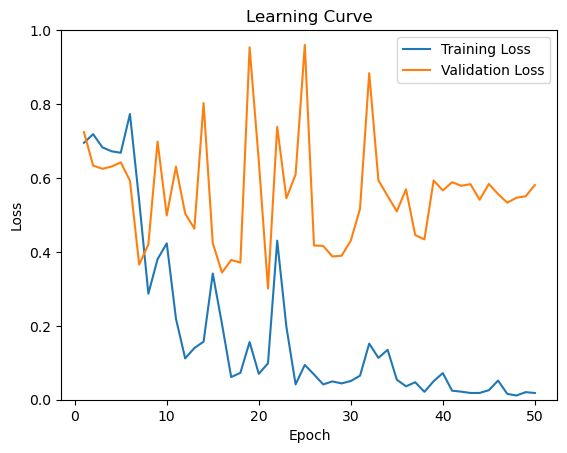

5
Fold 0: Training Loss: 0.15472406158223748, Validation Loss: 0.8874508912861347
Fold 1: Training Loss: 0.16279239400289952, Validation Loss: 0.1881193347275257
Fold 2: Training Loss: 0.1546616725018248, Validation Loss: 0.7879225973784924
Fold 3: Training Loss: 0.15706878472818062, Validation Loss: 0.31789328991435467
Fold 4: Training Loss: 0.18923697710037232, Validation Loss: 0.556947604957968
TRAIN LOSS MEDIA: 0.16369677798310295 VALID LOSS MEDIA: 0.547666743652895
TRAIN ACC MEDIA: 0.9162857167369554 VALID ACC MEDIA: 0.8107666707634925
TRAIN RECALL MEDIA: 0.8614345788955688 VALID RECALL MEDIA: 0.7646666765213013
TRAIN PRECISION MEDIA: 0.8798595666885376 VALID PRECISION MEDIA: 0.8452666791677477


In [16]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,45, optim.Adagrad , 5, 0.001, False, None)

## ADAGRAD DATA AUG

Fold 1
Accuracy Train: 0.8710204123234263. Accuracy valid: 0.7228571491582053
Recall Train: 0.8572788834571838. Recall valid: 0.5785714387893677
Precision Train: 0.870884358882904. Precision valid: 0.8852381110191345
Best Valid Accuracy Epoc: 6. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.45000000298023224


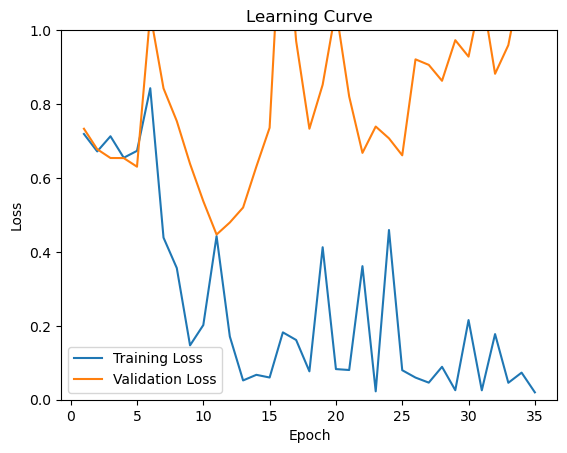

Fold 2
Accuracy Train: 0.859591841819335. Accuracy valid: 0.8600000023841858
Recall Train: 0.7904761433601379. Recall valid: 0.800000011920929
Precision Train: 0.8000000012772424. Precision valid: 0.7892857159887041
Best Valid Accuracy Epoc: 8. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 0.75


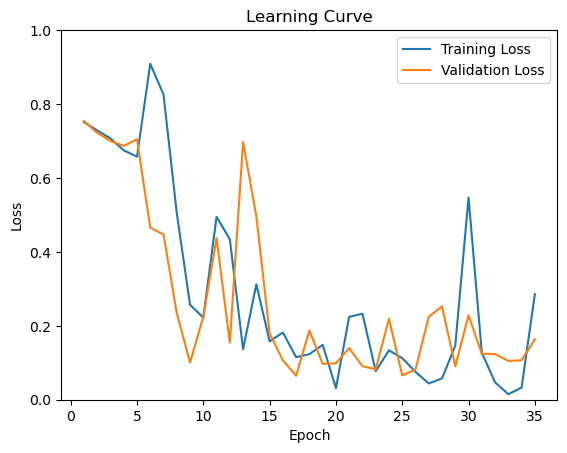

Fold 3
Accuracy Train: 0.8595918404812716. Accuracy valid: 0.7685714293803487
Recall Train: 0.8216326832771301. Recall valid: 0.7428572177886963
Precision Train: 0.8431973457336426. Precision valid: 0.8504762053489685
Best Valid Accuracy Epoc: 5. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 0.4750000014901161


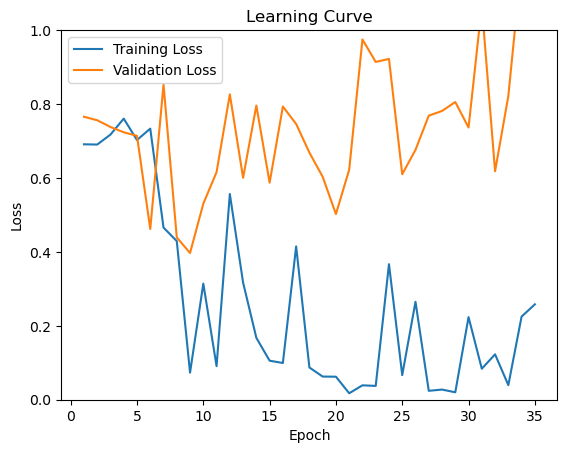

Fold 4
Accuracy Train: 0.8726530657739054. Accuracy valid: 0.8107142899717603
Recall Train: 0.8312245011329651. Recall valid: 0.8999999761581421
Precision Train: 0.8639456033706665. Precision valid: 0.7292857766151428
Best Valid Accuracy Epoc: 7. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.7750000059604645


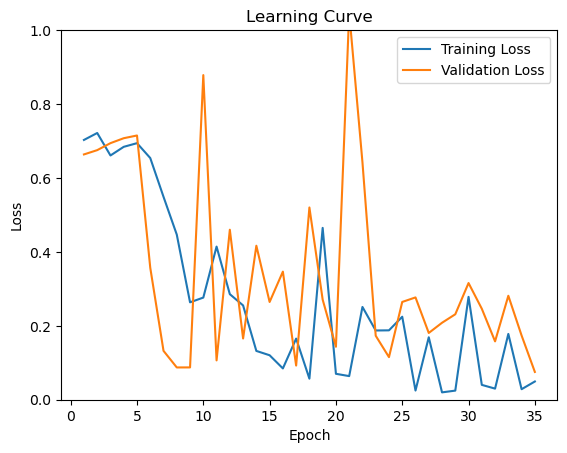

Fold 5
Accuracy Train: 0.8321428617196424. Accuracy valid: 0.6409523951155799
Recall Train: 0.7179761528968811. Recall valid: 0.7071428298950195
Precision Train: 0.7610118985176086. Precision valid: 0.675714373588562
Best Valid Accuracy Epoc: 5. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 7. Value = 1.0 Acc val = 0.533333346247673


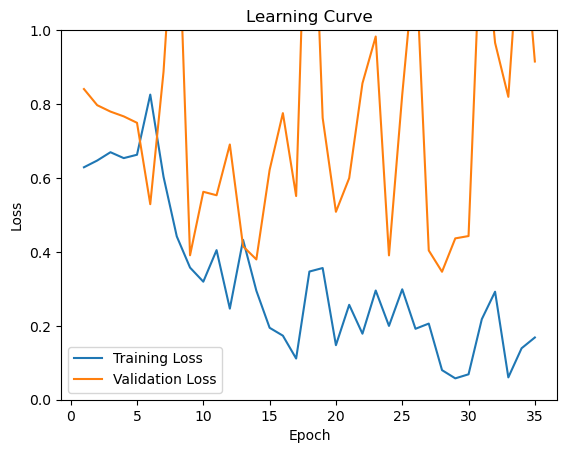

5
Fold 0: Training Loss: 0.25457057952880857, Validation Loss: 0.8120103235755648
Fold 1: Training Loss: 0.30093691545937745, Validation Loss: 0.2759669984823891
Fold 2: Training Loss: 0.2673701028738703, Validation Loss: 0.7366194547919024
Fold 3: Training Loss: 0.2702786098633494, Validation Loss: 0.3478410647383758
Fold 4: Training Loss: 0.32087638612304414, Validation Loss: 0.7595559730593647
TRAIN LOSS MEDIA: 0.28280651876969 VALID LOSS MEDIA: 0.5863987629295193
TRAIN ACC MEDIA: 0.8590000044235161 VALID ACC MEDIA: 0.7606190532020161
TRAIN RECALL MEDIA: 0.8037177324295044 VALID RECALL MEDIA: 0.7457143068313599
TRAIN PRECISION MEDIA: 0.8278078415564127 VALID PRECISION MEDIA: 0.7860000365121025


In [17]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.Adagrad , 5, 0.001, True, None)

Fold 1
Accuracy Train: 0.8612244937492876. Accuracy valid: 0.695000006045614
Recall Train: 0.835374116897583. Recall valid: 0.44285714626312256
Precision Train: 0.8428571820259094. Precision valid: 0.8333333730697632
Best Valid Accuracy Epoc: 6. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 5. Value = 0.5 Acc val = 0.6500000059604645


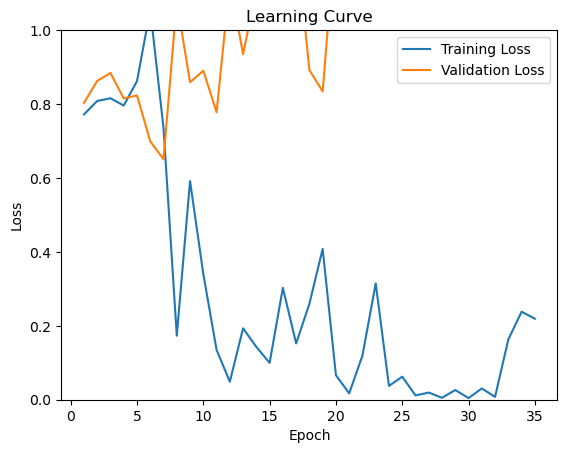

Fold 2
Accuracy Train: 0.8644898015017412. Accuracy valid: 0.815000006556511
Recall Train: 0.8506122827529907. Recall valid: 0.8238096237182617
Precision Train: 0.8653061389923096. Precision valid: 0.8607142891202654
Best Valid Accuracy Epoc: 14. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


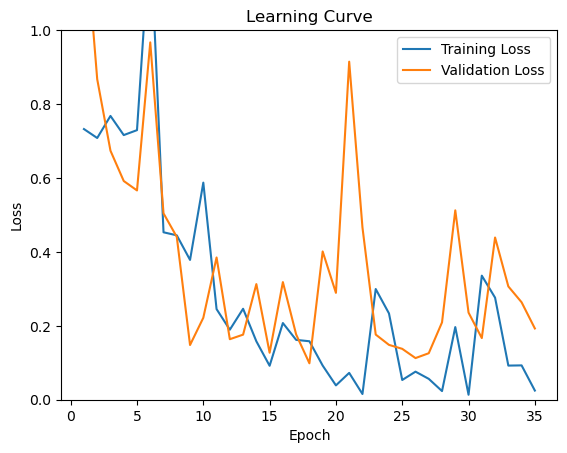

Fold 3
Accuracy Train: 0.8653061271322018. Accuracy valid: 0.7878571437937872
Recall Train: 0.8514285683631897. Recall valid: 0.7666667103767395
Precision Train: 0.8555102348327637. Precision valid: 0.8592857139451163
Best Valid Accuracy Epoc: 19. Value = 0.9000000059604645 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4750000014901161


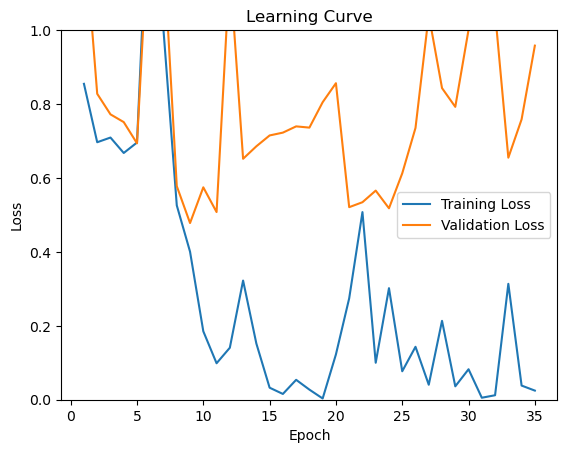

Fold 4
Accuracy Train: 0.8718367398393397. Accuracy valid: 0.7642857185431889
Recall Train: 0.8295918107032776. Recall valid: 0.9571428298950195
Precision Train: 0.8581632375717163. Precision valid: 0.6485713720321655
Best Valid Accuracy Epoc: 24. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.42500001192092896


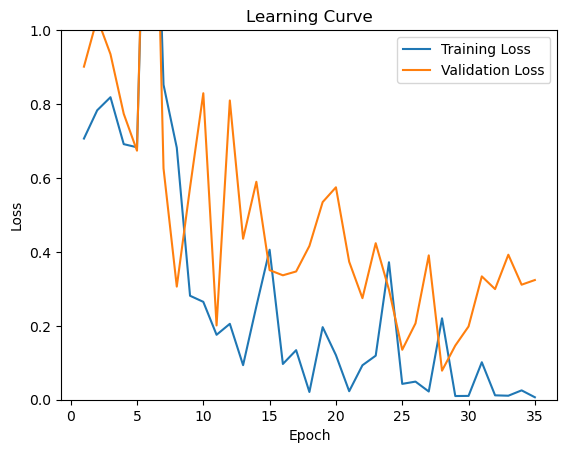

Fold 5
Accuracy Train: 0.8528571471571922. Accuracy valid: 0.6961904883384704
Recall Train: 0.7532737851142883. Recall valid: 0.6857143044471741
Precision Train: 0.7557142972946167. Precision valid: 0.7414285813059126
Best Valid Accuracy Epoc: 4. Value = 0.9000000059604645 Recall val = 0.75
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.533333346247673


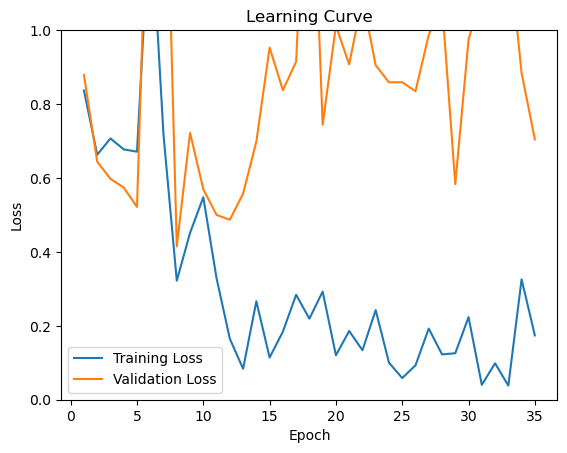

5
Fold 0: Training Loss: 0.28670323880921517, Validation Loss: 1.1052321621349879
Fold 1: Training Loss: 0.29253823584211724, Validation Loss: 0.37566177241720394
Fold 2: Training Loss: 0.29632409302118634, Validation Loss: 0.79300255577213
Fold 3: Training Loss: 0.3024697226605245, Validation Loss: 0.5011951459305627
Fold 4: Training Loss: 0.3185450361243316, Validation Loss: 0.8976409203638988
TRAIN LOSS MEDIA: 0.299316065291475 VALID LOSS MEDIA: 0.7345465113237567
TRAIN ACC MEDIA: 0.8631428618759525 VALID ACC MEDIA: 0.7516666726555143
TRAIN RECALL MEDIA: 0.8240561485290527 VALID RECALL MEDIA: 0.7352381348609924
TRAIN PRECISION MEDIA: 0.83551025390625 VALID PRECISION MEDIA: 0.7886666658946446


In [18]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.Adagrad , 5, 0.001, True, 'G')

Fold 1
Accuracy Train: 0.866122454465652. Accuracy valid: 0.6985714361071587
Recall Train: 0.8209524154663086. Recall valid: 0.48571428656578064
Precision Train: 0.8598639965057373. Precision valid: 0.8107143044471741
Best Valid Accuracy Epoc: 10. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 0. Value = 0.75 Acc val = 0.3500000014901161


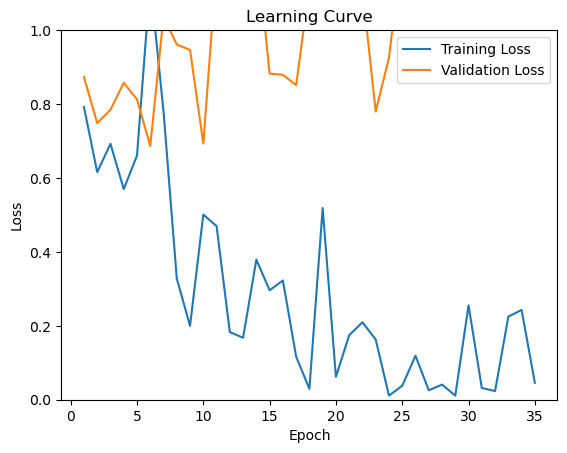

Fold 2
Accuracy Train: 0.8326530655427854. Accuracy valid: 0.8742857175213951
Recall Train: 0.7892516255378723. Recall valid: 0.9285714030265808
Precision Train: 0.8190476298332214. Precision valid: 0.881428599357605
Best Valid Accuracy Epoc: 8. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.5250000059604645


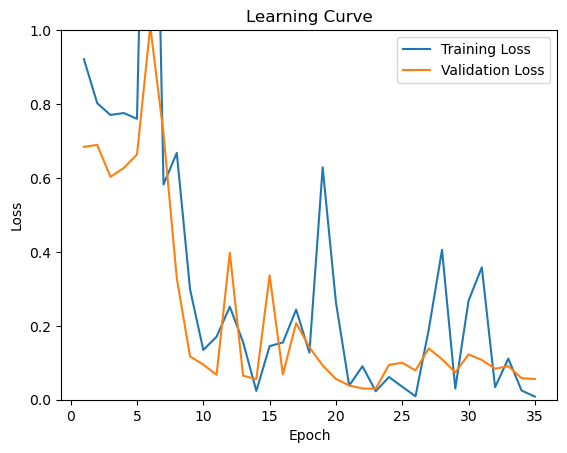

Fold 3
Accuracy Train: 0.8848979637330892. Accuracy valid: 0.8235714299338205
Recall Train: 0.855850338935852. Recall valid: 0.6809524297714233
Precision Train: 0.8752381205558777. Precision valid: 0.8857142925262451
Best Valid Accuracy Epoc: 8. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 8. Value = 0.8333333730697632 Acc val = 0.875


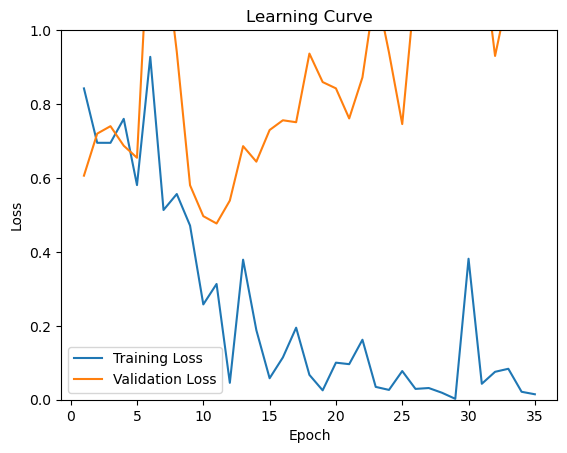

Fold 4
Accuracy Train: 0.8587755146683479. Accuracy valid: 0.7992857173085213
Recall Train: 0.9014285802841187. Recall valid: 0.8619047403335571
Precision Train: 0.8483673930168152. Precision valid: 0.6838095784187317
Best Valid Accuracy Epoc: 21. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


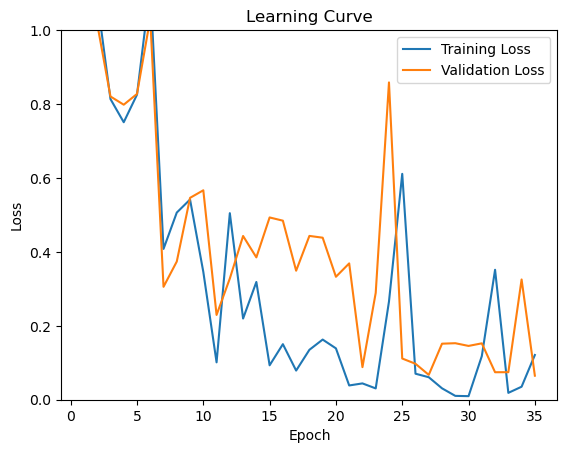

Fold 5
Accuracy Train: 0.8307142903762205. Accuracy valid: 0.7009523936680385
Recall Train: 0.7161905169487. Recall valid: 0.6571428775787354
Precision Train: 0.7282737493515015. Precision valid: 0.7214285863297326
Best Valid Accuracy Epoc: 7. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 0.9000000059604645


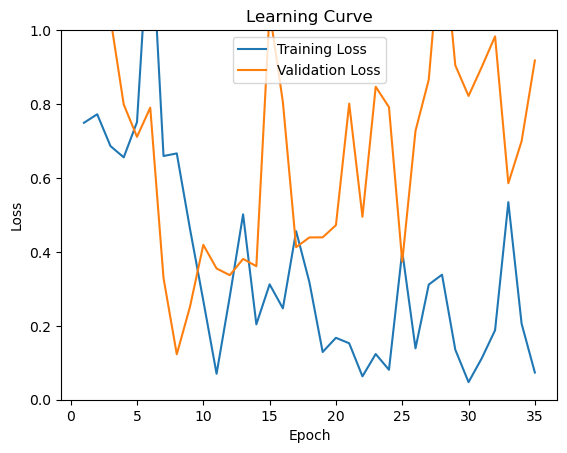

5
Fold 0: Training Loss: 0.2980770089530519, Validation Loss: 1.0854027782167708
Fold 1: Training Loss: 0.3407421391191227, Validation Loss: 0.23546423187279808
Fold 2: Training Loss: 0.25387771004544835, Validation Loss: 0.8940034711600414
Fold 3: Training Loss: 0.3312751594398703, Validation Loss: 0.4212744605261832
Fold 4: Training Loss: 0.36000612122671943, Validation Loss: 0.6927440744425569
TRAIN LOSS MEDIA: 0.3167956277568425 VALID LOSS MEDIA: 0.6657778032436701
TRAIN ACC MEDIA: 0.854632657757219 VALID ACC MEDIA: 0.7793333389077868
TRAIN RECALL MEDIA: 0.8167346715927124 VALID RECALL MEDIA: 0.7228571176528931
TRAIN PRECISION MEDIA: 0.8261582255363464 VALID PRECISION MEDIA: 0.7966190722158977


In [19]:
prueba_k_fold_resnet_pre(df_mean, 5, 5,30, optim.Adagrad , 5, 0.001, True, 'H')